<b><font color='aquamarine' size="6"> Data Preprocessing and Visualization</font></b>

<b><font size="6" color="aquamarine">City Hospital – Data Preprocessing &
Exploratory Analysis</font></b><a class="anchor"></a><a id="toc"></a><br>

### Group 16 - Team Members

| Name | Student Number |
|---|---|
| João Umbelino | 20251309 |
| Mariana Monteiri | 20251290 |
| Martim Violante | 20251310 |
| Rafael Portela | 20251361 |

---
## <font color='#BFD72F'>Table of Contents</font> <a class="anchor" id='toc'></a>

- [1. Part A - Data Understanding & Cleaning](#1)
  - [1.1 Loading and Importing the Data](#1_1)
  - [1.2 Initial Understanding of the Dataset](#1_2)
  - [1.3 Checking Duplicate Records and Label Hygiene](#1_3)
  - [1.4 Checking Missing Values](#1_4)
  - [1.5 Checking Patient Attribute Consistency](#1_5)
  - [1.6 Logical Rules and Hidden Structure in the Data](#1_6)
  - [1.7 Identifying Outliers](#1_7)
  - [1.8 Applying and Documenting Cleaning Decisions](#1_8)

- [2. Part B - Feature Engineering & ABT Construction](#2)
  - [2.1 Patient-Level ABT Construction](#2_1)
    - [2.1.1 Static Attributes](#2_1_1)
    - [2.1.2 Visit Behaviour Features](#2_1_2)
    - [2.1.3 Financial Features](#2_1_3)
    - [2.1.4 Satisfaction Features](#2_1_4)
    - [2.1.5 Recency and Activity Features](#2_1_5)
    - [2.1.6 Assembling and Validating the ABT](#2_1_6)
  - [2.2 Data Dictionary](#2_2)
  - [2.3 Exporting the ABT](#2_3)

- [3. Part C - Exploratory Visualization & Insights](#3)
  - [3.1 Patient Demographics](#3_1)
  - [3.2 Department and Service Usage](#3_2)
  - [3.3 Patient Satisfaction](#3_3)
  - [3.4 Additional Visualizations](#3_4)
  - [3.5 Management Questions and Key Insights](#3_5)
  - [3.6 Recommendations for the Next Analytics Team](#3_6)

---

### <font color='turquoise' size='6'>1. Part A – Data Understanding & Cleaning </font> <a class="anchor" id="1"></a>
  [Back to TOC](#toc)

**Approach.** Every problem found below follows the same four steps: **detect → show evidence → decide (correct / impute / flag / remove) → apply and log**. The raw Excel file is never modified: `raw` is read once, all cleaning happens on copies and is fully reproducible. Every decision is also written to an automatic *issue log* (section 1.8) so the report can be produced directly from the notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path
from scipy import stats
from IPython.display import display
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.labelsize": 11, "figure.autolayout": False})
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 220)

REFERENCE_DATE = pd.Timestamp("2024-07-01")   # imposed by the project brief
pid = "Patient ID"

## <font color='turquoise'>1.1 Loading and Importing the Data</font> <a class="anchor" id="1_1"></a>

In [2]:
# The brief calls the file "Project_Data.xlsx"; the version we received is "Project_Data_nova.xlsx".
# The loader accepts either name so the notebook runs from start to finish on any machine.
CANDIDATES = ["Project_Data.xlsx", "Project_Data_nova.xlsx", "Project Data nova.xlsx", "Project Data.xlsx"]
DATA_FILE = next((Path(p) for p in CANDIDATES if Path(p).exists()), None)
if DATA_FILE is None:
    raise FileNotFoundError(f"Place the Excel file in the notebook folder. Looked for: {CANDIDATES}")

raw = pd.read_excel(DATA_FILE)     # never modified after this line
df = raw.copy()                    # working copy used for the diagnostics of Part A
print(f"Loaded '{DATA_FILE.name}'")

Loaded 'Project Data nova.xlsx'


In [3]:
# Small audit trail: every cleaning decision is registered here and displayed in section 1.8
issue_log = []
def log_issue(area, issue, rows, decision, justification, patients=None):
    issue_log.append({"Area": area, "Issue": issue, "Rows affected": int(rows),
                      "Patients affected": (int(patients) if patients is not None else np.nan),
                      "Decision": decision, "Justification": justification})

## <font color='turquoise'>1.2 Initial Understanding of the Dataset</font> <a class="anchor" id="1_2"></a>

In [4]:
visits_pp = df.groupby(pid).size()
print(f"Dimensions          : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"Unique patients     : {df[pid].nunique()}   (Patient ID range {df[pid].min()} - {df[pid].max()})")
print(f"Observation window  : {df['Visit Date'].min().date()}  ->  {df['Visit Date'].max().date()}")
print(f"Visits per patient  : min {visits_pp.min()} | median {visits_pp.median():.0f} | max {visits_pp.max()}")
print()
print("Data types:")
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "non-null": df.notna().sum(),
                      "missing": df.isna().sum(), "unique values": df.nunique()}))

Dimensions          : 10,008 rows x 16 columns
Unique patients     : 500   (Patient ID range 1000 - 1499)
Observation window  : 2024-01-01  ->  2024-06-30
Visits per patient  : min 9 | median 20 | max 39

Data types:


,dtype,non-null,missing,unique values
Patient ID,int64,10008,0,500
Age,float64,9952,56,104
Gender,str,10008,0,3
City of Residence,str,10008,0,8
Profession,str,10008,0,10
Insurance Provider,str,8098,1910,4
Family History,str,8015,1993,4
Education Level,str,9979,29,8
Marital Status,str,10008,0,4
Visit Date,datetime64[us],10008,0,182


In [5]:
df.head()

,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
0,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-02-22,Endocrinology,110,2,38839.0,293.014042,0.0
1,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-01-21,Emergency,76,4,52219.0,287.208982,0.0
2,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-06-13,Neurology,17,5,41491.0,241.254507,0.0
3,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-03-24,Emergency,15,3,34944.0,221.177483,0.0
4,1482,65.0,Female,Birmingham,Retired,NaN,Heart Disease,Master,Divorced,2024-03-19,Neurology,99,1,39248.0,219.743794,0.0


In [6]:
num_cols = [c for c in df.columns if pd.api.types.is_numeric_dtype(df[c]) and c != pid]
cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])
            and not pd.api.types.is_datetime64_any_dtype(df[c])]

print("Numerical variables:")
display(df[num_cols].describe().T.round(2))

print("Categorical variables (all values that exist):")
for c in cat_cols:
    print(f"  {c} ({df[c].nunique()}): {sorted(df[c].dropna().unique())}")

Numerical variables:


,count,mean,std,min,25%,50%,75%,max
Age,9952.0,50.64,31.19,0.00,23.00,52.00,75.00,195.00
Consultation Duration,10008.0,67.81,32.45,15.00,41.00,68.00,94.00,600.00
Satisfaction Level,10008.0,3.20,1.57,1.00,2.00,3.00,5.00,6.00
Approximate Annual Income,9854.0,43402.76,268142.01,0.00,31157.75,40876.50,50721.75,11970900.00
Consultation Price,10008.0,187.26,862.87,50.04,111.32,159.53,199.82,39999.22
Insurance Coverage,9958.0,115.43,79.34,0.00,59.69,115.94,165.44,421.89


Categorical variables (all values that exist):
  Gender (3): ['Female', 'Male', 'Other']
  City of Residence (8): ['Belfast', 'Birmingham', 'Dublin', 'Edinburgh', 'Glasgow', 'Liverpool', 'London', 'Manchester']
  Profession (10): ['Artist', 'Businessperson', 'Doctor', 'Engineer', 'Lawyer', 'Nurse', 'Retired', 'Scientist', 'Student', 'Teacher']
  Insurance Provider (4): ['Provider A', 'Provider B', 'Provider C', 'Provider D']
  Family History (4): ['Cancer', 'Diabetes', 'Heart Disease', 'Hypertension']
  Education Level (8): ['Elementary school', 'High school', 'Kindergarten', 'Master', 'Middle school/junior high', 'PhD', 'Pre-school', 'Undergraduate']
  Marital Status (4): ['Divorced', 'Married', 'Single', 'Widowed']
  Department (13): ['Allergology', 'Cardiology', 'Dermatology', 'ENT', 'Emergency', 'Endocrinology', 'Gastroenterology', 'General Practice', 'Neurology', 'Orthopedics', 'Psychiatry', 'Pulmonology', 'Rheumatology']


**First impressions.** The size matches the brief (10,008 rows, 500 patients, 16 variables, January-June 2024). However, the numerical summary already hints at several problems that a pure `info()` would never reveal: `Age` goes up to **195**, `Approximate Annual Income` up to **~12 million**, `Consultation Price` up to **~£40,000**, `Consultation Duration` up to **600 minutes** and `Satisfaction Level` reaches **6** on a 1-5 scale. We investigate each of them below instead of assuming what is wrong.

## <font color='turquoise'>1.3 Checking Duplicate Records and Label Hygiene</font> <a class="anchor" id="1_3"></a>

In [7]:
# --- exact duplicates -----------------------------------------------------------
dup_all = df[df.duplicated(keep=False)].sort_values([pid, "Visit Date", "Department"])
print(f"Rows that are exact copies of an earlier row: {df.duplicated().sum()}")
display(dup_all.head(8))

Rows that are exact copies of an earlier row: 8


,Patient ID,Age,Gender,City of Residence,Profession,Insurance Provider,Family History,Education Level,Marital Status,Visit Date,Department,Consultation Duration,Satisfaction Level,Approximate Annual Income,Consultation Price,Insurance Coverage
1769,1011,11.0,Female,London,Student,NaN,NaN,Middle school/junior high,Single,2024-04-12,Psychiatry,101,1,0.0,133.415959,0.000000
1770,1011,11.0,Female,London,Student,NaN,NaN,Middle school/junior high,Single,2024-04-12,Psychiatry,101,1,0.0,133.415959,0.000000
983,1217,78.0,Other,London,Retired,NaN,Heart Disease,Undergraduate,Divorced,2024-05-03,Rheumatology,109,4,52131.0,164.423323,0.000000
984,1217,78.0,Other,London,Retired,NaN,Heart Disease,Undergraduate,Divorced,2024-05-03,Rheumatology,109,4,52131.0,164.423323,0.000000
2863,1253,38.0,Other,Manchester,Engineer,Provider A,Hypertension,Master,Married,2024-03-25,Emergency,70,2,32726.0,355.401954,284.321563
2864,1253,38.0,Other,Manchester,Engineer,Provider A,Hypertension,Master,Married,2024-03-25,Emergency,70,2,32726.0,355.401954,284.321563
2711,1287,68.0,Male,Birmingham,Retired,Provider A,Cancer,Undergraduate,Widowed,2024-06-16,Rheumatology,99,4,37375.0,141.686817,113.349454
2712,1287,68.0,Male,Birmingham,Retired,Provider A,Cancer,Undergraduate,Widowed,2024-06-16,Rheumatology,99,4,37375.0,141.686817,113.349454


In [8]:
# --- near-duplicates: same patient, same day, same department --------------------
key = [pid, "Visit Date", "Department"]
near = df[df.duplicated(key, keep=False) & ~df.duplicated(keep=False)]
n_groups = near.groupby(key).ngroups
differ = near.groupby(key)[["Consultation Duration", "Consultation Price"]].nunique().gt(1).any(axis=1).mean()

print(f"Patient/day/department combinations that appear more than once (but are NOT exact copies): {n_groups}")
print(f"Share of those pairs that differ in duration or price: {differ:.0%}")
print(f"Patients with two or more visits on the same day (any department): {df.duplicated([pid, 'Visit Date']).sum()} rows")

Patient/day/department combinations that appear more than once (but are NOT exact copies): 57
Share of those pairs that differ in duration or price: 100%
Patients with two or more visits on the same day (any department): 579 rows


In [9]:
# --- label hygiene: would trimming / case-folding merge any categories? ----------------
hyg = []
for c in cat_cols:
    s = df[c].dropna().astype(str)
    hyg.append({"Variable": c, "Distinct labels": s.nunique(),
                "After strip + case-fold": s.str.strip().str.casefold().str.replace(r"\s+", " ", regex=True).nunique()})
hyg = pd.DataFrame(hyg)
hyg["Variants to merge"] = hyg["Distinct labels"] - hyg["After strip + case-fold"]
display(hyg)

,Variable,Distinct labels,After strip + case-fold,Variants to merge
0,Gender,3,3,0
1,City of Residence,8,8,0
2,Profession,10,10,0
3,Insurance Provider,4,4,0
4,Family History,4,4,0
5,Education Level,8,8,0
6,Marital Status,4,4,0
7,Department,13,13,0


**Decisions.**
- **Exact duplicates (8 rows):** identical in all 16 columns, including a price with 15 decimals. Two genuinely different consultations can never match to that precision, so these are the same record loaded twice → **remove, keeping the first occurrence** (done programmatically, not by hard-coded row numbers, so it still works if the file is refreshed).
- **Same patient + same day + same department (≈60 cases):** these differ in duration, price and rating, so they are separate consultations (a patient can be seen twice on a day, e.g. follow-up) → **keep**. The count is also what we would expect by chance for patients with ~20 visits over 181 days.
- **Labels:** no variants such as `"ENT "`, `"ent"` or `"Gen. Practice"` exist, so no category merging is needed. A trim is still applied in the pipeline as a safeguard.

## <font color='turquoise'>1.4 Checking Missing Values</font> <a class="anchor" id="1_4"></a>

Missing values are not all alike. Before choosing a treatment we need to know **how** each variable is missing: patient by patient (the whole patient is blank → probably *structural*, a meaningful "none") or visit by visit (a few random blanks → *data-entry gaps*).

In [10]:
miss_cols = [c for c in df.columns if df[c].isna().any()]

def miss_pattern(col):
    share = df.groupby(pid)[col].apply(lambda x: x.isna().mean())
    return pd.Series({"Rows missing": df[col].isna().sum(),
                      "% rows": round(df[col].isna().mean() * 100, 2),
                      "Patients fully missing": int((share == 1).sum()),
                      "Patients partially missing": int(((share > 0) & (share < 1)).sum())})

miss_table = pd.DataFrame({c: miss_pattern(c) for c in miss_cols}).T
display(miss_table)

,Rows missing,% rows,Patients fully missing,Patients partially missing
Age,56.0,0.56,0.0,53.0
Insurance Provider,1910.0,19.08,92.0,36.0
Family History,1993.0,19.91,99.0,0.0
Education Level,29.0,0.29,0.0,2.0
Approximate Annual Income,154.0,1.54,0.0,133.0
Insurance Coverage,50.0,0.50,0.0,33.0


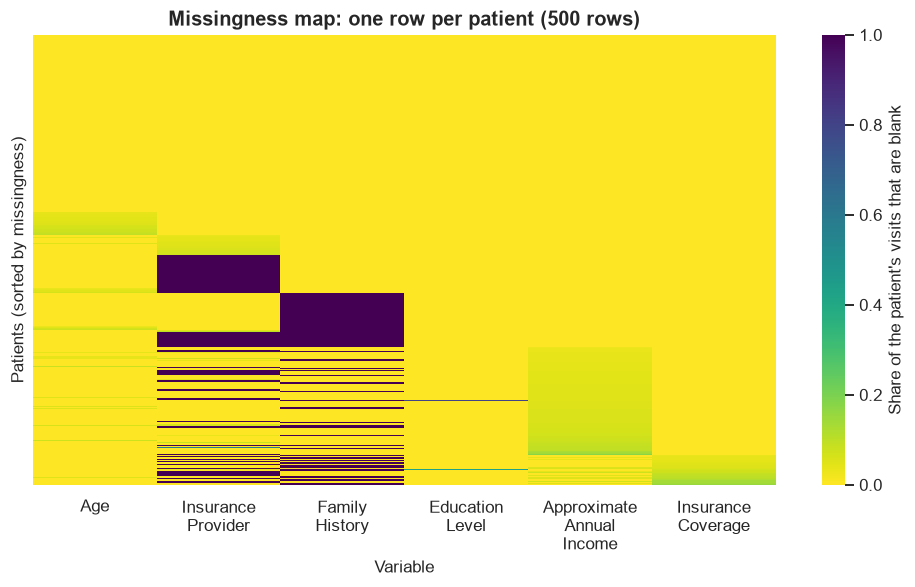

In [11]:
# Patient x variable map: share of each patient's visits that is blank
share_map = pd.DataFrame({c: df.groupby(pid)[c].apply(lambda x: x.isna().mean()) for c in miss_cols})

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(share_map.sort_values(miss_cols[::-1]).values, cmap="viridis_r", cbar_kws={"label": "Share of the patient's visits that are blank"},
            xticklabels=[c.replace(" ", "\n") for c in miss_cols], yticklabels=False, ax=ax)
ax.set_title("Missingness map: one row per patient (500 rows)")
ax.set_xlabel("Variable")
ax.set_ylabel("Patients (sorted by missingness)")
plt.tight_layout(); plt.show()

**Interpretation.** Two completely different mechanisms appear:
- `Family History` is blank for **entire patients** and never partially → a blank is a *recorded absence*, not a lost value (structural missingness).
- `Age`, `Income`, `Education Level` and `Insurance Coverage` have a few isolated blanks inside patients that are otherwise complete → classical *data-entry gaps*, which can be recovered from the patient's other visits.
- `Insurance Provider` mixes both: many patients have no provider on any visit, and 36 patients have it missing on some visits only. We test whether "no provider" means "no insurance" below.

In [12]:
# Does a missing Insurance Provider mean "uninsured"?  Compare the coverage paid on those rows.
nop = df[df["Insurance Provider"].isna()]
print(f"Rows without provider: {len(nop):,}")
print(f"  of which coverage is exactly £0 : {(nop['Insurance Coverage'] == 0).mean():.1%}")
print(f"  of which coverage is missing    : {nop['Insurance Coverage'].isna().mean():.1%}")
print(f"  of which coverage > £0          : {(nop['Insurance Coverage'] > 0).mean():.1%}")
print()

# Where coverage > 0 without a provider, WHO are these patients?
pos = nop[nop["Insurance Coverage"] > 0]
print("Patients with positive coverage but no provider on those rows:")
display(pos.groupby(pid).size().to_frame("rows with coverage > 0 and no provider").T)

# Minimum coverage when a provider IS present (is "0" ever a legitimate value for insured rows?)
print(f"\nMinimum coverage on rows WITH a provider: £{df.loc[df['Insurance Provider'].notna(), 'Insurance Coverage'].min():.2f}")

Rows without provider: 1,910
  of which coverage is exactly £0 : 94.1%
  of which coverage is missing    : 1.1%
  of which coverage > £0          : 4.8%

Patients with positive coverage but no provider on those rows:


Patient ID,1013,1014,1015,1028,1031,1034,1038,1088,1089,1092,1100,1103,1105,1121,1135,1143,1234,1245,1248,1260,1261,1266,1272,1285,1294,1302,1308,1317,1333,1340,1343,1381,1449,1451,1455,1485,1490,1498
rows with coverage > 0 and no provider,18,24,13,1,1,1,1,1,1,1,1,1,1,1,1,1,2,1,1,1,1,1,1,1,2,1,1,1,1,1,1,1,1,1,1,1,1,1



Minimum coverage on rows WITH a provider: £35.07


**Interpretation.** When a provider is present, coverage is never zero (minimum ≈ £35), while when it is absent almost all rows have coverage = £0. So **a blank provider means "no insurance"** for most patients. The few exceptions (patients with positive coverage but no provider label) are patients whose provider was simply not recorded - we will recover their provider from the coverage rate (see 1.6, where we discover that each provider pays a fixed percentage of the price).

The decisions for each variable are applied in 1.8, once all the evidence has been collected.

## <font color='turquoise'>1.5 Checking Patient Attribute Consistency</font> <a class="anchor" id="1_5"></a>

Attributes that describe the *person* (gender, city, profession, education, marital status, age, provider, family history) should not change between consultations that happened within six months.

In [13]:
stable_cols = ["Gender", "City of Residence", "Profession", "Insurance Provider", "Family History",
               "Education Level", "Marital Status", "Age", "Approximate Annual Income"]

def modal(s):
    m = s.mode(dropna=True)
    return m.iloc[0] if len(m) else np.nan

rows = []
for c in stable_cols:
    nun = df.groupby(pid)[c].nunique(dropna=True)
    bad_p = nun[nun > 1].index
    sub = df[df[pid].isin(bad_p)]
    if c == "Approximate Annual Income":
        minority = np.nan
    else:
        mode_p = sub.groupby(pid)[c].transform(modal)
        minority = (sub[c].notna() & (sub[c] != mode_p)).sum()
    rows.append({"Variable": c, "Patients with >1 value": len(bad_p),
                 "Rows that disagree with the patient's usual value": minority,
                 "Rows of those patients": len(sub)})
consistency = pd.DataFrame(rows).set_index("Variable")
display(consistency)

,Patients with >1 value,Rows that disagree with the patient's usual value,Rows of those patients
Variable,,,
Gender,5,10.0,106
City of Residence,0,0.0,0
Profession,2,7.0,37
Insurance Provider,0,0.0,0
Family History,0,0.0,0
Education Level,0,0.0,0
Marital Status,4,5.0,84
Age,1,1.0,22
Approximate Annual Income,390,NaN,7801


In [14]:
# One example per variable: the patient with the most conflicting rows
for c in ["Gender", "Profession", "Marital Status", "Age"]:
    nun = df.groupby(pid)[c].nunique()
    ex = nun[nun > 1].index[0]
    print(f"{c:15s} | patient {ex}: {df.loc[df[pid] == ex, c].value_counts().to_dict()}")

Gender          | patient 1050: {'Female': 14, 'Male': 3}
Profession      | patient 1488: {'Student': 17, 'Retired': 2}
Marital Status  | patient 1140: {'Single': 18, 'Widowed': 1}
Age             | patient 1198: {138.0: 21, 38.0: 1}


**Interpretation.** Gender (5 patients), Profession (2), Marital Status (4) and Age (1) show conflicts (the 2 Profession cases turn out to be children, handled by a separate rule in 1.6), and in every example the conflicting value is a **tiny minority** (e.g. 14 visits "Female" vs 3 "Male"; 17 "Single" vs 1 "Widowed"). A person's gender does not change from one consultation to the next, so the minority entries are data-entry errors and the patient's **modal value** is the best estimate → **correct with the mode**.

`Approximate Annual Income` is different: 390 patients have several values. But the brief says income is *"as recorded at the consultation"*, so it is a noisy measurement, not necessarily an error. We check whether the variation is natural or whether there are real mistakes:

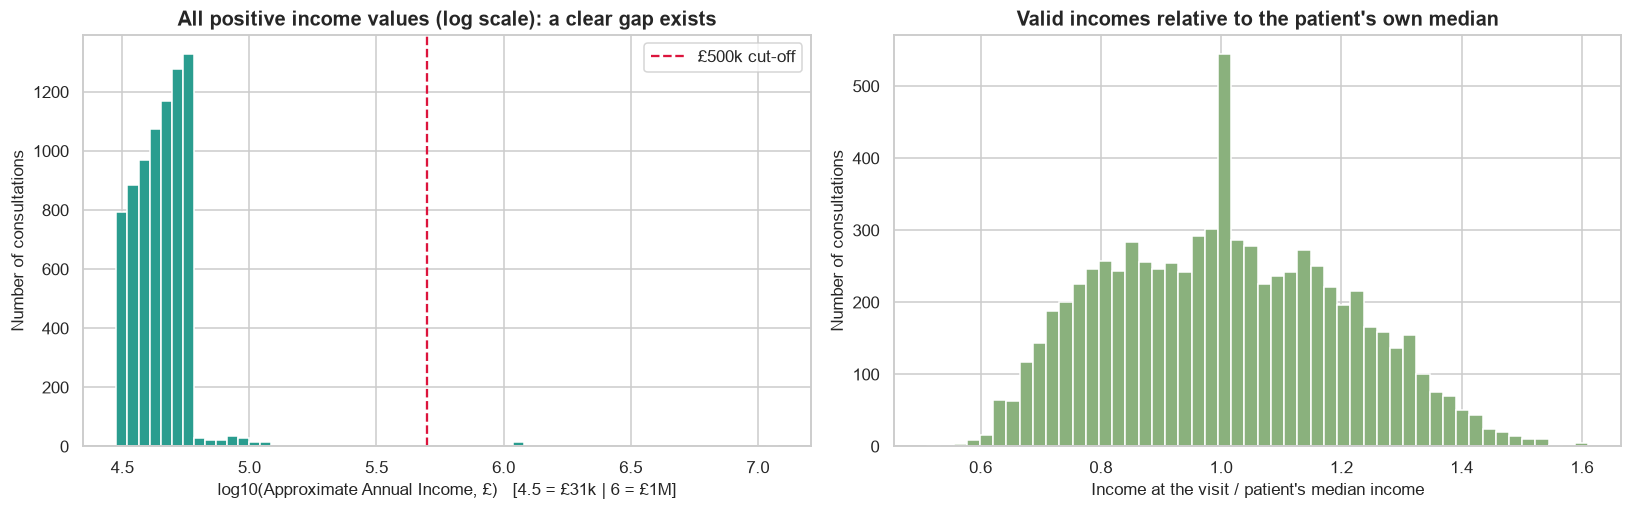

Valid-income ratio to patient median: 1st pct 0.64 | 99th pct 1.44
Rows with income above £500k: 21 (largest legitimate value: £113,120)


In [15]:
inc = df.loc[df["Approximate Annual Income"].between(1, 500_000), [pid, "Approximate Annual Income"]].copy()
inc["ratio"] = inc["Approximate Annual Income"] / inc.groupby(pid)["Approximate Annual Income"].transform("median")

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
pos_inc = df["Approximate Annual Income"][df["Approximate Annual Income"] > 0]
ax[0].hist(np.log10(pos_inc), bins=60, color="#2a9d8f", edgecolor="white")
ax[0].set_title("All positive income values (log scale): a clear gap exists")
ax[0].set_xlabel("log10(Approximate Annual Income, £)   [4.5 = £31k | 6 = £1M]")
ax[0].set_ylabel("Number of consultations")
ax[0].axvline(np.log10(500_000), color="crimson", ls="--", label="£500k cut-off")
ax[0].legend()

ax[1].hist(inc["ratio"], bins=50, color="#8ab17d", edgecolor="white")
ax[1].set_title("Valid incomes relative to the patient's own median")
ax[1].set_xlabel("Income at the visit / patient's median income")
ax[1].set_ylabel("Number of consultations")
plt.tight_layout(); plt.show()

print(f"Valid-income ratio to patient median: 1st pct {inc['ratio'].quantile(.01):.2f} | 99th pct {inc['ratio'].quantile(.99):.2f}")
print(f"Rows with income above £500k: {(df['Approximate Annual Income'] > 500_000).sum()} (largest legitimate value: £{df.loc[df['Approximate Annual Income'] <= 500_000, 'Approximate Annual Income'].max():,.0f})")

**Interpretation.** Legitimate incomes move within roughly ±40-60 % of the patient's own level (visit-to-visit recording noise), whereas a small group of values sits one order of magnitude above everything else (≥ £1.1 million, with nothing between £120k and £1.1M). The first group is **natural measurement variation** (kept, summarised with the patient's **median**, which is robust); the second is **recording errors** (extra digits) → treated as invalid and re-estimated from the patient's other visits.

## <font color='turquoise'>1.6 Logical Rules and Hidden Structure in the Data</font> <a class="anchor" id="1_6"></a>

Simple range checks catch *impossible* values; they miss values that are **possible but wrong**. To catch those we look for rules the data obeys almost perfectly - once a rule is known, violations stand out.

In [16]:
# ---- Cleaning parameters (all thresholds in one place, each justified in the text) ----------
AGE_MAX         = 110             # no valid age above this; typos show up as 118, 138, 142, 158, 195
INCOME_CAP      = 500_000         # largest legitimate income is ~£120k; errors start above £1.1M
DURATION_RANGE  = (15, 120)       # bulk of the data is 15-120 min; next value above is 228
RATING_RANGE    = (1, 5)          # scale defined in the brief
PRICE_TYPO_X    = 10              # a price above 10x its department median is a scale error
ADULT_AGE       = 18

Coverage rate paid by each provider (median coverage / price): {'Provider A': 0.8, 'Provider B': 0.9, 'Provider C': 0.7, 'Provider D': 1.0}


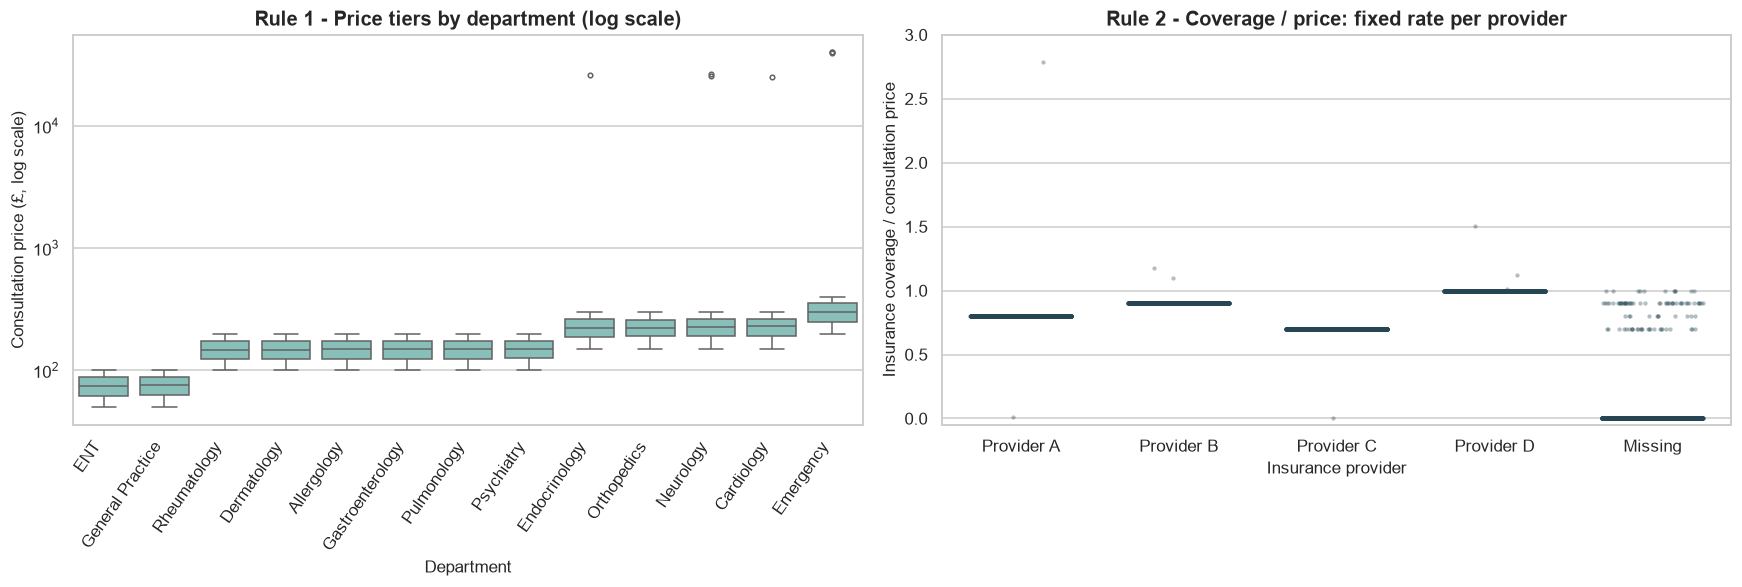

In [17]:
# ---- Rule 1: every department charges within a narrow price tier ------------------------------
# ---- Rule 2: every insurance provider pays a FIXED percentage of the price --------------------
tmp = df.assign(ratio=df["Insurance Coverage"] / df["Consultation Price"],
                Provider=df["Insurance Provider"].fillna("Missing"))

RATE = tmp.groupby("Insurance Provider")["ratio"].median().round(2).to_dict()     # derived, not typed in
RATE_ALL = {**RATE, "Uninsured": 0.0}
print("Coverage rate paid by each provider (median coverage / price):", RATE)

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
order = df.groupby("Department")["Consultation Price"].median().sort_values().index
sns.boxplot(data=df, x="Department", y="Consultation Price", order=order, ax=ax[0], color="#7fc8c0", fliersize=3)
ax[0].set_yscale("log")
ax[0].set_title("Rule 1 - Price tiers by department (log scale)")
ax[0].set_xlabel("Department"); ax[0].set_ylabel("Consultation price (£, log scale)")
plt.setp(ax[0].get_xticklabels(), rotation=55, ha="right")

prov_order = ["Provider A", "Provider B", "Provider C", "Provider D", "Missing"]
sns.stripplot(data=tmp.dropna(subset=["ratio"]), x="Provider", y="ratio", order=prov_order, ax=ax[1],
              size=2.8, alpha=.35, jitter=.32, color="#264653")
ax[1].set_ylim(-0.05, 3)
ax[1].set_title("Rule 2 - Coverage / price: fixed rate per provider")
ax[1].set_xlabel("Insurance provider"); ax[1].set_ylabel("Insurance coverage / consultation price")
plt.tight_layout(); plt.show()

**Interpretation.**
- **Rule 1:** departments charge in four clear tiers (ENT and General Practice ≈ £75; Allergology, Dermatology, Gastroenterology, Psychiatry, Pulmonology, Rheumatology ≈ £150; Cardiology, Endocrinology, Neurology, Orthopedics ≈ £225; Emergency ≈ £300). A handful of points sit **~100× above their tier** (£25,000-£40,000). Looking closely at the digits (next cell), they are the right price with **two extra digits inserted after the hundreds digit** (`253.79` → `25300.79`, `399.18` → `39999.18`) - and for insured patients we can *prove* it, because `coverage ÷ provider rate` reproduces the true price.
- **Rule 2:** Provider A pays 80 %, B 90 %, C 70 % and D 100 % of the price - every insured row sits on a horizontal line. Rows off the lines are errors, and, more importantly, the **correct coverage can be recomputed exactly** (`rate × price`) instead of guessing it with a median. The rule also lets us recover the provider of patients whose label is missing but whose coverage is not.

In [18]:
# ---- Evidence for the price typo: remove the two inserted digits and compare with the price implied by coverage ----
p = df["Consultation Price"]
dept_med_raw = df.groupby("Department")["Consultation Price"].transform("median")
typo_rows = df.loc[p > PRICE_TYPO_X * dept_med_raw, [pid, "Department", "Consultation Price", "Insurance Provider", "Insurance Coverage"]].copy()
typo_rows["Fix: drop the 2 inserted digits"] = np.floor(typo_rows["Consultation Price"] / 100) + (typo_rows["Consultation Price"] % 1)
typo_rows["Price implied by coverage / rate"] = typo_rows["Insurance Coverage"] / typo_rows["Insurance Provider"].map(RATE)
display(typo_rows.round(2))
chk = typo_rows.dropna(subset=["Price implied by coverage / rate"])
print(f"Insured rows that can be verified independently: {len(chk)}  |  max difference between fix and implied price: £{(chk['Fix: drop the 2 inserted digits'] - chk['Price implied by coverage / rate']).abs().max():.3f}")

,Patient ID,Department,Consultation Price,Insurance Provider,Insurance Coverage,Fix: drop the 2 inserted digits,Price implied by coverage / rate
333,1373,Endocrinology,26399.89,NaN,0.00,263.89,NaN
575,1313,Neurology,25899.55,NaN,0.00,258.55,NaN
660,1292,Emergency,39999.22,NaN,0.00,399.22,NaN
1685,1029,Neurology,26799.94,NaN,0.00,267.94,NaN
1777,1005,Emergency,39400.18,NaN,0.00,394.18,NaN
3189,1175,Emergency,39999.18,Provider A,319.34,399.18,399.18
5997,1445,Cardiology,25300.79,Provider C,177.66,253.79,253.79


Insured rows that can be verified independently: 2  |  max difference between fix and implied price: £0.000


Satisfaction Level,1,2,3,4,5,6
col_0,,,,,,
ENT + General Practice,13.5,13.9,13.3,11.8,11.4,36.0
Other 11 departments,19.9,20.1,19.6,20.6,19.6,0.0


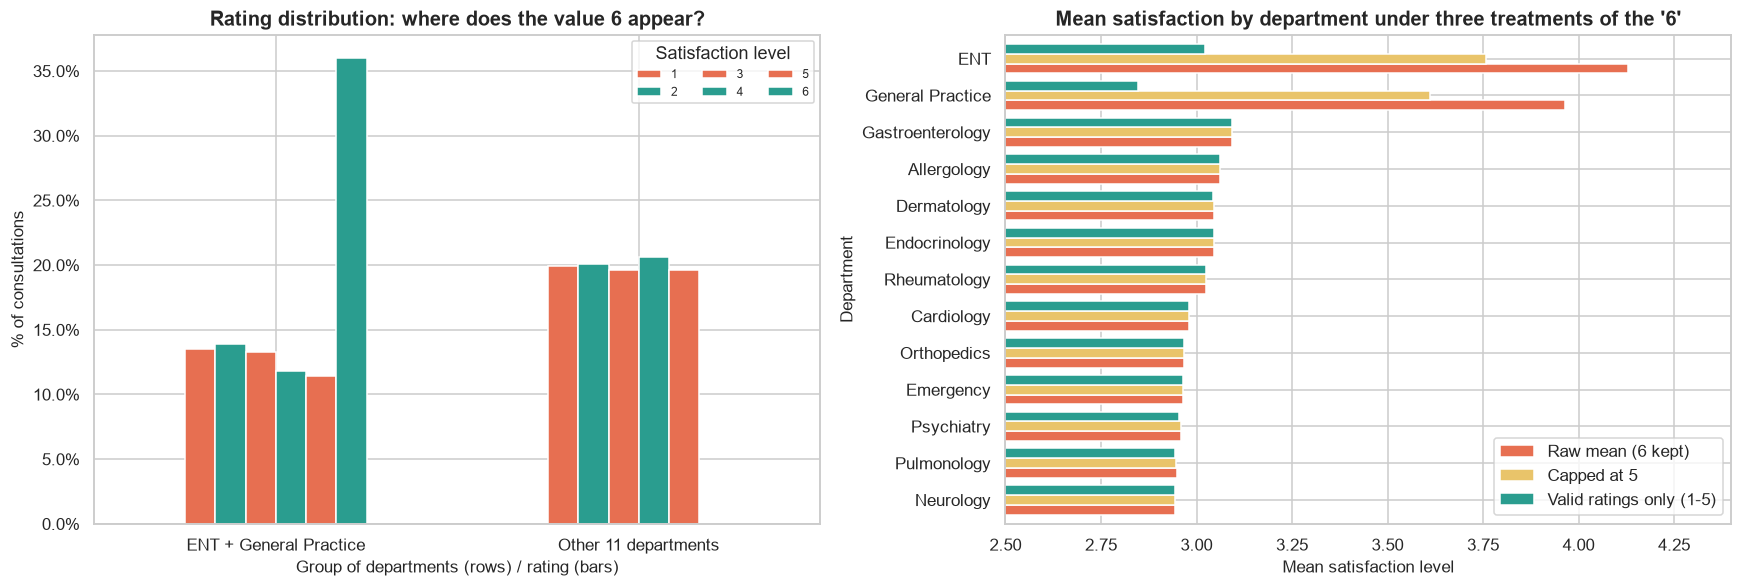

Rows with rating = 6: 719  |  of those in ENT or General Practice: 99.4%


In [19]:
# ---- Rule 3: the satisfaction scale ----------------------------------------------------------
grp = np.where(df["Department"].isin(["ENT", "General Practice"]), "ENT + General Practice", "Other 11 departments")
dist = (pd.crosstab(df["Satisfaction Level"], grp, normalize="columns") * 100).round(1)
display(dist.T)

naive  = df.groupby("Department")["Satisfaction Level"].mean()
capped = df.assign(s=df["Satisfaction Level"].clip(upper=5)).groupby("Department")["s"].mean()
valid  = df[df["Satisfaction Level"].between(*RATING_RANGE)].groupby("Department")["Satisfaction Level"].mean()
cmp = pd.DataFrame({"Raw mean (6 kept)": naive, "Capped at 5": capped, "Valid ratings only (1-5)": valid}).sort_values("Raw mean (6 kept)")

fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
(dist.T).plot(kind="bar", ax=ax[0], color=["#e76f51", "#2a9d8f"], edgecolor="white", rot=0)
ax[0].set_title("Rating distribution: where does the value 6 appear?")
ax[0].set_xlabel("Group of departments (rows) / rating (bars)"); ax[0].set_ylabel("% of consultations")
ax[0].yaxis.set_major_formatter(mtick.PercentFormatter())
ax[0].legend(title="Satisfaction level", ncol=3, fontsize=8)

cmp.plot(kind="barh", ax=ax[1], color=["#e76f51", "#e9c46a", "#2a9d8f"], width=.8)
ax[1].set_xlim(2.5, 4.4)
ax[1].set_title("Mean satisfaction by department under three treatments of the '6'")
ax[1].set_xlabel("Mean satisfaction level"); ax[1].set_ylabel("Department")
plt.tight_layout(); plt.show()

print(f"Rows with rating = 6: {(df['Satisfaction Level'] == 6).sum()}  |  of those in ENT or General Practice: "
      f"{df.loc[df['Satisfaction Level'] == 6, 'Department'].isin(['ENT', 'General Practice']).mean():.1%}")

**Interpretation - this is the most consequential finding of the whole cleaning stage.** The value 6 is not scattered randomly: it is concentrated almost exclusively in **ENT and General Practice**, where about **36 %** of ratings are 6, versus ≈ 0 % everywhere else. If we followed the usual shortcut (cap 6 at 5), these two departments would jump to a mean of ≈ 4.0-4.1 and become the "best-rated" in the hospital - **an artefact of the data, not of patient experience**. Looking only at valid 1-5 ratings, ENT and General Practice sit at ≈ 3.0, in line with every other department.

→ **Decision: treat 6 as invalid (set to missing + flag), not as 5.** We cannot know what rating the patient meant, and inventing one would bias exactly the comparison management cares about. All satisfaction features use valid ratings only, and the number of discarded ratings is kept as a feature (`N_Invalid_Ratings`) so the next team can see where the information is thinner. We also recommend asking the information-systems team whether those two departments use a different rating form.

In [20]:
# ---- Evidence for the age and profession rules --------------------------------------------------
print("Ages above the maximum:")
display(df[df["Age"] > AGE_MAX].groupby(pid).agg(Age_recorded=("Age", "max"), Rows=("Age", "size"),
        Profession=("Profession", "first"), Education=("Education Level", "first"),
        Marital=("Marital Status", "first")).assign(Age_minus_100=lambda x: x["Age_recorded"] - 100))

print("Patients under 18 whose profession is not 'Student':")
kids = df[(df["Age"] < ADULT_AGE) & (df["Profession"] != "Student")]
display(kids.groupby(pid).agg(Age=("Age", "first"), Profession_recorded=("Profession", modal),
        Education=("Education Level", "first"), Median_income=("Approximate Annual Income", "median"),
        Rows=("Age", "size")))

Ages above the maximum:


,Age_recorded,Rows,Profession,Education,Marital,Age_minus_100
Patient ID,,,,,,
1000,158.0,20,Artist,Undergraduate,Divorced,58.0
1180,195.0,16,Retired,Master,Divorced,95.0
1198,138.0,21,Engineer,Undergraduate,Divorced,38.0
1207,118.0,27,Student,High school,Single,18.0
1319,142.0,19,Engineer,Master,Widowed,42.0


Patients under 18 whose profession is not 'Student':


,Age,Profession_recorded,Education,Median_income,Rows
Patient ID,,,,,
1181,1.0,Lawyer,Pre-school,0.0,25
1398,5.0,Doctor,Kindergarten,0.0,20
1433,9.0,Teacher,Elementary school,0.0,35
1479,11.0,Retired,Middle school/junior high,0.0,14
1488,11.0,Retired,Middle school/junior high,0.0,2
1496,4.0,Retired,Pre-school,0.0,13


**Interpretation.**
- All five impossible ages are **a "1" prepended to a plausible age** (118, 138, 142, 158, 195 → 18, 38, 42, 58, 95), and the corrected age is consistent with the patient's profession and education (a 18-year-old high-school student, a 95-year-old retired person, a 42-year-old engineer). → **subtract 100**, rather than deleting the patients.
- Several children aged 1-11 are recorded as *Lawyer*, *Doctor*, *Teacher* or *Retired*. Three independent variables agree that they are children: **income = £0 on every visit**, a **school-level education** (pre-school … middle school) and **single** marital status. → the profession is the faulty field; **recode to Student**.

In [21]:
# ---- Rule-based audit table (re-used after cleaning to prove the problems are gone) ----------
def rule_audit(d):
    exp_cov = d["Insurance Provider"].map(RATE_ALL) * d["Consultation Price"]
    dept_med = d.groupby("Department")["Consultation Price"].transform("median")
    rules = {
        "Age missing":                                    d["Age"].isna(),
        f"Age above {AGE_MAX}":                           d["Age"] > AGE_MAX,
        f"Non-student under {ADULT_AGE}":                 (d["Age"] < ADULT_AGE) & (d["Profession"] != "Student"),
        "Student aged 26+":                               (d["Age"] > 25) & (d["Profession"] == "Student"),
        "Retired under 55":                               (d["Age"] < 55) & (d["Profession"] == "Retired"),
        "Doctor under 24 / Lawyer under 22":              ((d["Age"] < 24) & (d["Profession"] == "Doctor")) | ((d["Age"] < 22) & (d["Profession"] == "Lawyer")),
        "Master/PhD under 21":                            (d["Age"] < 21) & d["Education Level"].isin(["Master", "PhD"]),
        "Divorced/Widowed under 18":                      (d["Age"] < 18) & d["Marital Status"].isin(["Divorced", "Widowed"]),
        "Zero income, non-student":                       (d["Approximate Annual Income"] == 0) & (d["Profession"] != "Student"),
        f"Income above £{INCOME_CAP:,}":                  d["Approximate Annual Income"] > INCOME_CAP,
        "Income missing":                                 d["Approximate Annual Income"].isna(),
        f"Duration outside {DURATION_RANGE}":             ~d["Consultation Duration"].between(*DURATION_RANGE),
        f"Rating outside {RATING_RANGE} (non-missing)":   d["Satisfaction Level"].notna() & ~d["Satisfaction Level"].between(*RATING_RANGE),
        f"Price above {PRICE_TYPO_X}x department median": d["Consultation Price"] > PRICE_TYPO_X * dept_med,
        "Coverage greater than price":                    d["Insurance Coverage"] > d["Consultation Price"] + 1e-9,
        "Coverage missing":                               d["Insurance Coverage"].isna(),
        "Coverage != provider rate x price":              exp_cov.notna() & d["Insurance Coverage"].notna() & ((d["Insurance Coverage"] - exp_cov).abs() > 0.05),
        "Provider missing":                               d["Insurance Provider"].isna(),
        "Family history missing":                         d["Family History"].isna(),
        "Education missing":                              d["Education Level"].isna(),
    }
    return pd.DataFrame({"Rows": {k: int(v.sum()) for k, v in rules.items()},
                         "Patients": {k: int(d.loc[v, pid].nunique()) for k, v in rules.items()}})

audit_raw = rule_audit(df)
display(audit_raw[audit_raw["Rows"] > 0])

,Rows,Patients
Age missing,56,53
Age above 110,103,5
Non-student under 18,109,6
Student aged 26+,27,1
Retired under 55,29,3
Doctor under 24 / Lawyer under 22,132,7
Divorced/Widowed under 18,2,2
"Zero income, non-student",109,6
"Income above £500,000",21,10
Income missing,154,133


## <font color='turquoise'>1.7 Identifying Outliers</font> <a class="anchor" id="1_7"></a>

A statistical rule (IQR) and a **domain rule** answer different questions. IQR says *"unusual"*; the domain says *"impossible"*. We compare both before choosing, because deleting something that is merely unusual destroys legitimate information (e.g. the most expensive department is not an outlier, it is Emergency).

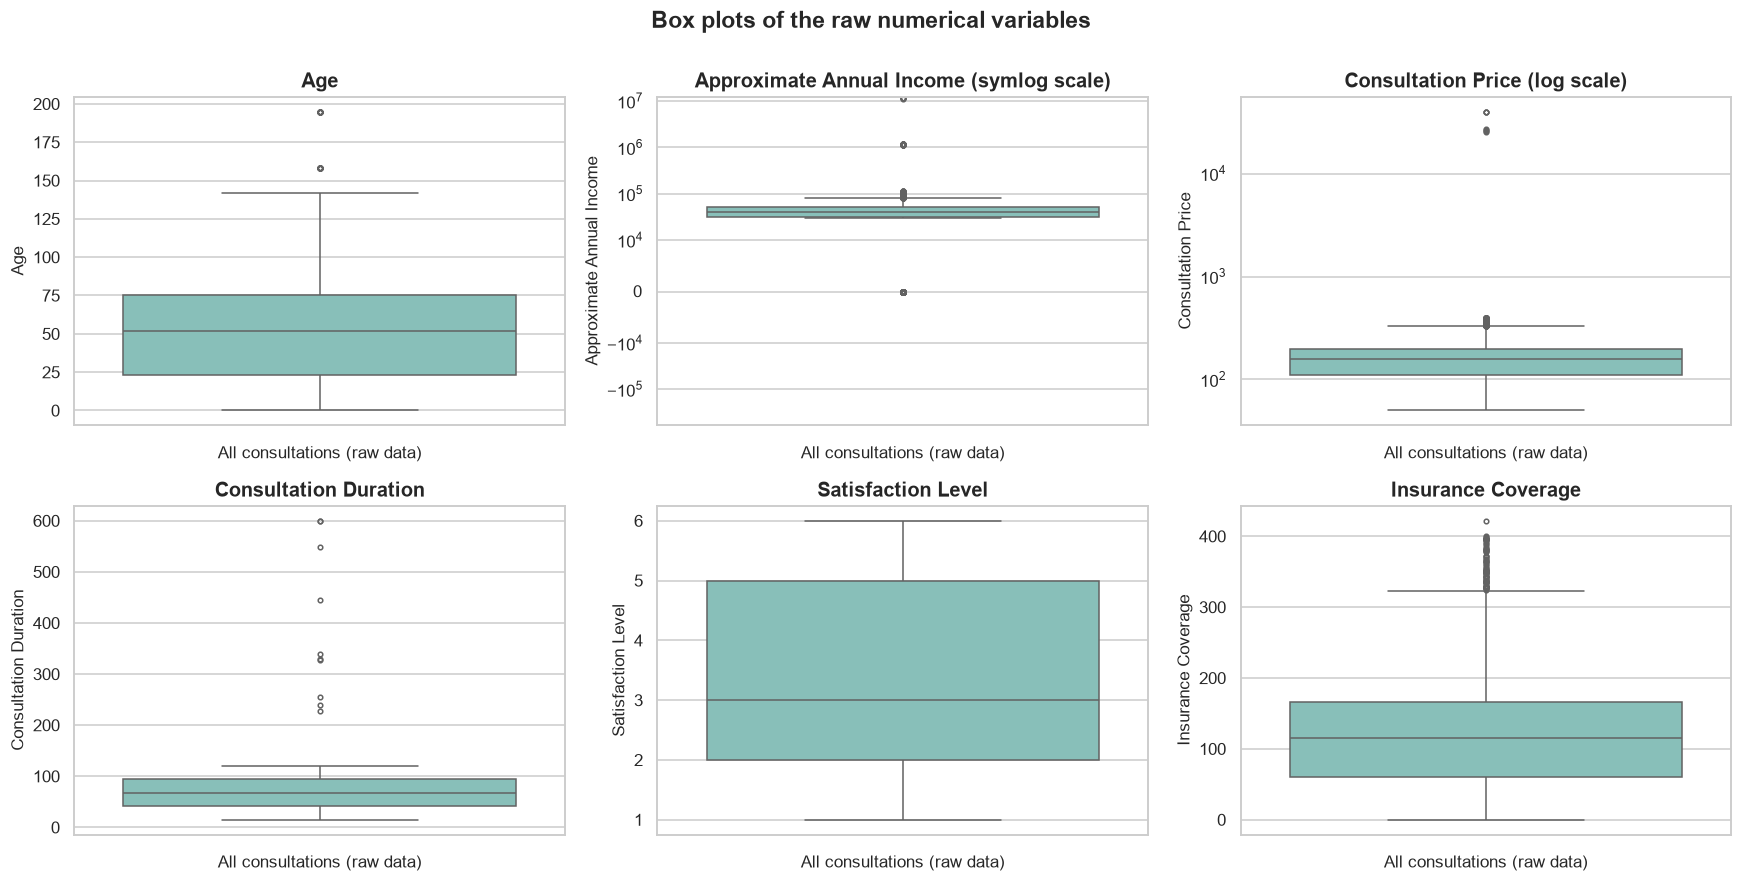

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
specs = [("Age", None), ("Approximate Annual Income", "symlog"), ("Consultation Price", "log"),
         ("Consultation Duration", None), ("Satisfaction Level", None), ("Insurance Coverage", None)]
for ax, (col, scale) in zip(axes.ravel(), specs):
    sns.boxplot(y=df[col], ax=ax, color="#7fc8c0", fliersize=3)
    if scale == "symlog": ax.set_yscale("symlog", linthresh=1e4)
    elif scale: ax.set_yscale(scale)
    ax.set_title(col + (f" ({scale} scale)" if scale else ""))
    ax.set_xlabel("All consultations (raw data)"); ax.set_ylabel(col)
fig.suptitle("Box plots of the raw numerical variables", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

In [23]:
def iqr_flag(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)

dept_med_raw = df.groupby("Department")["Consultation Price"].transform("median")
domain = {
    "Age":                       df["Age"] > AGE_MAX,
    "Approximate Annual Income": df["Approximate Annual Income"] > INCOME_CAP,
    "Consultation Price":        df["Consultation Price"] > PRICE_TYPO_X * dept_med_raw,
    "Consultation Duration":     ~df["Consultation Duration"].between(*DURATION_RANGE),
    "Satisfaction Level":        ~df["Satisfaction Level"].between(*RATING_RANGE),
    "Insurance Coverage":        df["Insurance Coverage"] > df["Consultation Price"],
}
cmp_out = []
for col, dom in domain.items():
    iq = iqr_flag(df[col]).fillna(False)
    cmp_out.append({"Variable": col, "IQR rule flags": int(iq.sum()), "Domain rule flags (real errors)": int(dom.sum()),
                    "IQR flags that are NOT errors": int((iq & ~dom).sum()),
                    "Errors the IQR rule misses": int((dom & ~iq).sum())})
cmp_out = pd.DataFrame(cmp_out).set_index("Variable")
display(cmp_out)

,IQR rule flags,Domain rule flags (real errors),IQR flags that are NOT errors,Errors the IQR rule misses
Variable,,,,
Age,36,103,0,67
Approximate Annual Income,2288,21,2267,0
Consultation Price,241,7,234,0
Consultation Duration,10,10,0,0
Satisfaction Level,0,719,0,719
Insurance Coverage,77,6,75,4


**Interpretation.** Applying IQR blindly would have **deleted thousands of perfectly valid records** - over 2,000 legitimate incomes (everyone earning above ≈ £80k) and ≈ 230 genuine Emergency prices (£332-£399) - while it can also **miss genuine errors** that hide inside a legitimate range (a rating of 6, a coverage that is wrong but below the price). We therefore use the domain rules established in 1.6:

| Variable | Rule | Treatment |
|---|---|---|
| Age | > 110 | subtract the prepended "1" (validated against profession/education) |
| Income | > £500k | invalid → re-estimate from the patient's own valid visits |
| Price | > 10 × department median | remove the two inserted digits and **verify** (against coverage / provider rate and the department's price band) |
| Duration | outside 15-120 min | invalid → patient's median duration (duration is unrelated to department) |
| Rating | outside 1-5 | invalid → missing (see 1.6) |
| Coverage | ≠ rate × price | recompute exactly from the provider's rate |

We remove **no outlier rows**: each problem value is corrected, re-estimated or flagged, so the patients' complete histories are preserved. Only the 8 duplicates are deleted.

## <font color='turquoise'>1.8 Applying and Documenting Cleaning Decisions</font> <a class="anchor" id="1_8"></a>

The whole pipeline is one sequence of small, ordered steps (the order matters: e.g. prices must be fixed *before* coverage is recomputed from them). Each step logs how many rows/patients it touched. Corrected visits also receive a `flag_*` column so nothing is silently altered.

In [24]:
clean = df.copy()
flags = {}                                   # visit-level audit flags, added to `clean` at the end

# ---- Step 1. Exact duplicates ---------------------------------------------------------------
before = len(clean)
clean = clean.drop_duplicates(keep="first").reset_index(drop=True)
log_issue("Duplicates", "Exact duplicate consultations", before - len(clean), "Remove (keep first)",
          "Identical in all 16 columns including a 15-decimal price: the same record loaded twice.")

# ---- Step 2. Safe trimming of text labels -----------------------------------------------------
for c in cat_cols:
    clean[c] = clean[c].str.strip()

In [25]:
# ---- Step 3. Age typos (a leading "1"): subtract 100, then verify ------------------------------
typo = clean["Age"] > AGE_MAX
flags["flag_age_corrected"] = typo.copy()
n_p = clean.loc[typo, pid].nunique()
clean.loc[typo, "Age"] = clean.loc[typo, "Age"] - 100
unfixable = (clean["Age"] > AGE_MAX) | (clean["Age"] < 0)
clean.loc[unfixable, "Age"] = np.nan
log_issue("Age", f"Impossible ages (>{AGE_MAX}, e.g. 118, 158, 195)", typo.sum(), "Correct (age - 100)",
          "Each is a plausible age with a leading '1'; corrected age agrees with profession and education.", n_p)

# ---- Step 4. Static attributes: one value per patient (modal value) -----------------------------
rep = []
def harmonise(cols):
    for c in cols:
        modes = clean.groupby(pid)[c].transform(modal)
        conflict = clean[c].notna() & modes.notna() & (clean[c] != modes)
        gap = clean[c].isna() & modes.notna()
        ties = int(clean.groupby(pid)[c].apply(lambda s: len(s.mode()) > 1).sum())
        flags[f"flag_{c.split()[0].lower()}_harmonised"] = conflict | gap
        clean.loc[conflict | gap, c] = modes[conflict | gap]
        rep.append({"Variable": c, "Conflicting rows corrected": int(conflict.sum()), "Blank rows filled": int(gap.sum()),
                    "Patients with a tie (no clear mode)": ties})
        if conflict.sum():
            log_issue(c, "Value changes between visits of the same patient", conflict.sum(), "Correct (patient's modal value)",
                      "A person's static attribute cannot change in 6 months; the minority entry is a typing error.",
                      clean.loc[conflict, pid].nunique())
        if gap.sum():
            log_issue(c, "Isolated missing values inside an otherwise complete patient", gap.sum(), "Impute (patient's modal value)",
                      "The patient's other visits give the true value with certainty.", clean.loc[gap, pid].nunique())

harmonise(["Age"])                                  # age first: the profession rule below depends on it

# ---- Step 5. Profession vs age: children cannot be lawyers / doctors / retired ---------------------
child_wrong = (clean["Age"] < ADULT_AGE) & (clean["Profession"] != "Student")
flags["flag_profession_recoded"] = child_wrong.copy()
log_issue("Profession", f"Patients under {ADULT_AGE} recorded with an adult profession", child_wrong.sum(), "Correct (-> Student)",
          "Income is £0 on every visit, education is school-level and marital status is Single: three variables agree they are children.",
          clean.loc[child_wrong, pid].nunique())
clean.loc[child_wrong, "Profession"] = "Student"

harmonise(["Gender", "City of Residence", "Profession", "Education Level", "Marital Status"])
display(pd.DataFrame(rep).set_index("Variable"))

# ---- Step 6. Income: invalid scale errors -> patient median of valid visits ---------------------
inc_col = "Approximate Annual Income"
bad_inc = clean[inc_col] > INCOME_CAP
clean.loc[bad_inc, inc_col] = np.nan
miss_inc = clean[inc_col].isna()
flags["flag_income_imputed"] = miss_inc.copy()
fill = clean.groupby(pid)[inc_col].transform("median")                  # median of the patient's valid visits
clean.loc[miss_inc, inc_col] = fill[miss_inc]
left = clean[inc_col].isna()                                           # fallback (should be empty)
clean.loc[left, inc_col] = clean.groupby("Profession")[inc_col].transform("median")[left]
log_issue("Income", f"Values above £{INCOME_CAP:,} (extra digits)", bad_inc.sum(), "Invalid -> re-estimate",
          "Nothing between £120k and £1.1M: they are recording errors. Replaced by the patient's median valid income.",
          clean.loc[bad_inc, pid].nunique())
log_issue("Income", "Missing income on some visits", (miss_inc & ~bad_inc).sum(), "Impute (patient median)",
          "Income fluctuates by visit, so the median of the patient's other visits is the most robust estimate.",
          clean.loc[miss_inc & ~bad_inc, pid].nunique())

,Conflicting rows corrected,Blank rows filled,Patients with a tie (no clear mode)
Variable,,,
Age,0,56,0
Gender,10,0,0
City of Residence,0,0,0
Profession,0,0,0
Education Level,0,29,0
Marital Status,5,0,0


In [26]:
# ---- Step 7. Price: two inserted digits -> remove them and VERIFY ---------------------------------
price = "Consultation Price"
dept_med = clean.groupby("Department")[price].transform("median")
p_typo = clean[price] > PRICE_TYPO_X * dept_med
cand = np.floor(clean[price] / 100) + (clean[price] % 1)                  # 25300.79 -> 253.79
ok = cand.between(0.5 * dept_med, 1.5 * dept_med)                         # must land inside the department's price band
flags["flag_price_corrected"] = p_typo.copy()
clean.loc[p_typo & ok, price] = cand[p_typo & ok]
clean.loc[p_typo & ~ok, price] = np.nan                                   # not recoverable -> department median
clean.loc[clean[price].isna(), price] = dept_med[clean[price].isna()]
log_issue("Price", f"Price > {PRICE_TYPO_X}x its department median (£25k-£40k)", p_typo.sum(), "Correct (remove the 2 inserted digits)",
          f"Two extra digits after the hundreds; {int((p_typo & ok).sum())}/{int(p_typo.sum())} corrected prices fall inside the department's band and the insured ones match coverage/rate exactly.",
          clean.loc[p_typo, pid].nunique())

# ---- Step 8. Duration: outside 15-120 minutes -> patient median ---------------------------------
dur = "Consultation Duration"
bad_dur = ~clean[dur].between(*DURATION_RANGE)
flags["flag_duration_imputed"] = bad_dur.copy()
clean[dur] = clean[dur].astype(float)
clean.loc[bad_dur, dur] = np.nan
med_dur = clean.groupby(pid)[dur].transform("median")
clean.loc[bad_dur, dur] = med_dur[bad_dur].round()
clean[dur] = clean[dur].fillna(clean[dur].median()).astype(int)
log_issue("Duration", f"Durations outside {DURATION_RANGE} min (228-600)", bad_dur.sum(), "Invalid -> impute (patient median)",
          "Valid durations are uniform 15-120 and unrelated to department; the next-highest value is a gap away.",
          clean.loc[bad_dur, pid].nunique())

In [27]:
# ---- Step 9. Insurance provider: recover or declare "Uninsured" ----------------------------------
prov = "Insurance Provider"
miss_prov = clean[prov].isna()
flags["flag_provider_imputed"] = miss_prov.copy()
clean_ratio = clean["Insurance Coverage"] / clean[price]

# (a) patients with the provider recorded on some visits: propagate it to their other visits
prov_mode = clean.groupby(pid)[prov].transform(modal)
fill_a = miss_prov & prov_mode.notna()
clean.loc[fill_a, prov] = prov_mode[fill_a]

# (b) patients with no provider on ANY visit but positive coverage: the coverage rate identifies the provider
rates = pd.Series(RATE)
inferred = {}
for p_id, s in clean_ratio[(clean["Insurance Coverage"] > 0) & clean[prov].isna()].groupby(clean[pid]):
    m = s.median()
    best = (rates - m).abs().idxmin()
    if abs(rates[best] - m) < 0.02:
        inferred[p_id] = best
fill_b = clean[prov].isna() & clean[pid].isin(inferred.keys())
clean.loc[fill_b, prov] = clean.loc[fill_b, pid].map(inferred)

# (c) everyone else: no provider and £0 coverage -> genuinely uninsured
fill_c = clean[prov].isna()
clean.loc[fill_c, prov] = "Uninsured"

log_issue("Insurance Provider", "Provider missing on some visits of an insured patient", fill_a.sum(), "Impute (patient's provider)",
          "Coverage on those rows follows the provider's fixed rate, so the patient is insured.", clean.loc[fill_a, pid].nunique())
log_issue("Insurance Provider", "Provider missing for all visits but coverage > 0", fill_b.sum(), "Infer from coverage rate",
          "coverage/price = 0.7 / 0.9 identifies the provider exactly (see rule 2).", clean.loc[fill_b, pid].nunique())
log_issue("Insurance Provider", "No provider and coverage = £0 on every visit", fill_c.sum(), "Recode as 'Uninsured'",
          "A blank provider always coincides with £0 coverage; keeping NaN would hide a real patient group (self-pay).", clean.loc[fill_c, pid].nunique())

# ---- Step 10. Insurance coverage: recompute exactly from provider rate x price --------------------
cov = "Insurance Coverage"
expected = clean[prov].map(RATE_ALL) * clean[price]
bad_cov = clean[cov].isna() | ((clean[cov] - expected).abs() > 0.05)
flags["flag_coverage_recomputed"] = bad_cov.copy()
n_missing_cov = int(clean[cov].isna().sum()); n_wrong_cov = int(bad_cov.sum() - n_missing_cov)
clean.loc[bad_cov, cov] = expected[bad_cov]
log_issue("Coverage", "Missing coverage", n_missing_cov, "Recompute (rate x price)",
          "Rate is fixed per provider (A 80%, B 90%, C 70%, D 100%), so the exact value is known - no median guess needed.",
          None)
log_issue("Coverage", "Coverage inconsistent with provider rate (incl. coverage > price)", n_wrong_cov, "Correct (rate x price)",
          "Rows off the fixed-rate line are errors; recomputed value never exceeds the price.", None)

# ---- Step 11. Family history: structural blank -> explicit category -------------------------------
fh = "Family History"
share = clean.groupby(pid)[fh].apply(lambda s: s.isna().mean())
print(f"Family History: patients fully blank = {(share == 1).sum()}, partially blank = {((share > 0) & (share < 1)).sum()}  ->  blank is a recorded absence")
n_fh = int(clean[fh].isna().sum())
clean[fh] = clean[fh].fillna("None reported")
log_issue("Family History", "Blank for entire patients (never partially)", n_fh, "Recode as 'None reported'",
          "Blank is structural (no history recorded), not lost data; imputing a disease would invent medical information.",
          int((share == 1).sum()))

# ---- Step 12. Satisfaction: the value 6 is invalid -> missing + flag ------------------------------
sat = "Satisfaction Level"
bad_sat = clean[sat].notna() & ~clean[sat].between(*RATING_RANGE)
flags["flag_rating_invalid"] = bad_sat.copy()
clean.loc[bad_sat, sat] = np.nan
log_issue("Satisfaction", "Rating = 6 on a 1-5 scale (36% of ENT & General Practice ratings)", bad_sat.sum(),
          "Invalid -> set to missing + flag",
          "Concentrated in 2 departments; capping at 5 would make them look like the best-rated (artefact). Used valid ratings only.",
          clean.loc[bad_sat, pid].nunique())

Family History: patients fully blank = 99, partially blank = 0  ->  blank is a recorded absence


In [28]:
# ---- Step 13. Atypical but plausible profiles: KEEP and FLAG ------------------------------------------
atyp = ((clean["Age"] < 24) & (clean["Profession"] == "Doctor")) | ((clean["Age"] < 22) & (clean["Profession"] == "Lawyer"))
flags["flag_atypical_age_profession"] = atyp.copy()
log_issue("Profession", "Very young doctors (<24) / lawyers (<22) with university education and income > £0", atyp.sum(), "Keep + flag",
          "Unusual but possible, and age, education and income all agree with each other; nothing proves which field is wrong, so we do not alter them.",
          clean.loc[atyp, pid].nunique())

# ---- Step 14. Derived visit-level columns + audit flags ---------------------------------------------
clean = pd.concat([clean, pd.DataFrame(flags).astype(bool)], axis=1)
clean["Out_of_Pocket"] = clean[price] - clean[cov]
clean["Visit Month"] = clean["Visit Date"].dt.to_period("M")
clean = clean.sort_values([pid, "Visit Date"]).reset_index(drop=True)
flag_cols = list(flags.keys())

# ---- Final validation: the cleaned data must satisfy every rule --------------------------------------
checks = {
    "All 500 patients retained (no patient removed)":            clean[pid].nunique() == raw[pid].nunique(),
    "Rows = raw rows - exact duplicates":                        len(clean) == len(raw) - raw.duplicated().sum(),
    "No missing values (except invalidated ratings)":            clean.drop(columns=[sat]).isna().sum().sum() == 0,
    "Static attributes constant within every patient":           all(clean.groupby(pid)[c].nunique().max() == 1 for c in ["Gender", "City of Residence", "Profession", "Education Level", "Marital Status", "Age", prov, fh]),
    "Ages within 0-110":                                         clean["Age"].between(0, AGE_MAX).all(),
    "Ratings within 1-5 (or missing)":                           clean[sat].dropna().between(*RATING_RANGE).all(),
    "Durations within 15-120":                                   clean[dur].between(*DURATION_RANGE).all(),
    "0 <= coverage <= price":                                    ((clean[cov] >= 0) & (clean[cov] <= clean[price] + 1e-9)).all(),
    "Out-of-pocket never negative":                              (clean["Out_of_Pocket"] >= -1e-9).all(),
    "Every patient has at least one valid rating":               clean.groupby(pid)[sat].count().min() > 0,
}
for k, v in checks.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(checks.values()), "A validation check failed"

PASS  All 500 patients retained (no patient removed)
PASS  Rows = raw rows - exact duplicates
PASS  No missing values (except invalidated ratings)
PASS  Static attributes constant within every patient
PASS  Ages within 0-110
PASS  Ratings within 1-5 (or missing)
PASS  Durations within 15-120
PASS  0 <= coverage <= price
PASS  Out-of-pocket never negative
PASS  Every patient has at least one valid rating


In [29]:
# ---- Before vs after, and the rule audit re-run on the cleaned data ------------------------------------
audit_clean = rule_audit(clean)
audit_view = audit_raw.join(audit_clean, lsuffix=" (raw)", rsuffix=" (clean)")
display(audit_view[(audit_view["Rows (raw)"] > 0) | (audit_view["Rows (clean)"] > 0)])

summary = pd.DataFrame({
    "raw min": raw[num_cols].min(), "clean min": clean[num_cols].min(),
    "raw max": raw[num_cols].max(), "clean max": clean[num_cols].max(),
    "raw mean": raw[num_cols].mean(), "clean mean": clean[num_cols].mean(),
    "raw missing": raw[num_cols].isna().sum(), "clean missing": clean[num_cols].isna().sum()}).round(2)
display(summary)

,Rows (raw),Patients (raw),Rows (clean),Patients (clean)
Age missing,56,53,0,0
Age above 110,103,5,0,0
Non-student under 18,109,6,0,0
Student aged 26+,27,1,0,0
Retired under 55,29,3,0,0
Doctor under 24 / Lawyer under 22,132,7,87,5
Divorced/Widowed under 18,2,2,0,0
"Zero income, non-student",109,6,0,0
"Income above £500,000",21,10,0,0
Income missing,154,133,0,0


,raw min,clean min,raw max,clean max,raw mean,clean mean,raw missing,clean missing
Age,0.00,0.00,195.00,100.00,50.64,49.60,56,0
Consultation Duration,15.00,15.00,600.00,120.00,67.81,67.48,0,0
Satisfaction Level,1.00,1.00,6.00,5.00,3.20,2.99,0,719
Approximate Annual Income,0.00,0.00,11970900.00,113120.00,43402.76,35716.94,154,0
Consultation Price,50.04,50.04,39999.22,399.22,187.26,165.11,0,0
Insurance Coverage,0.00,0.00,421.89,398.60,115.43,115.45,50,0


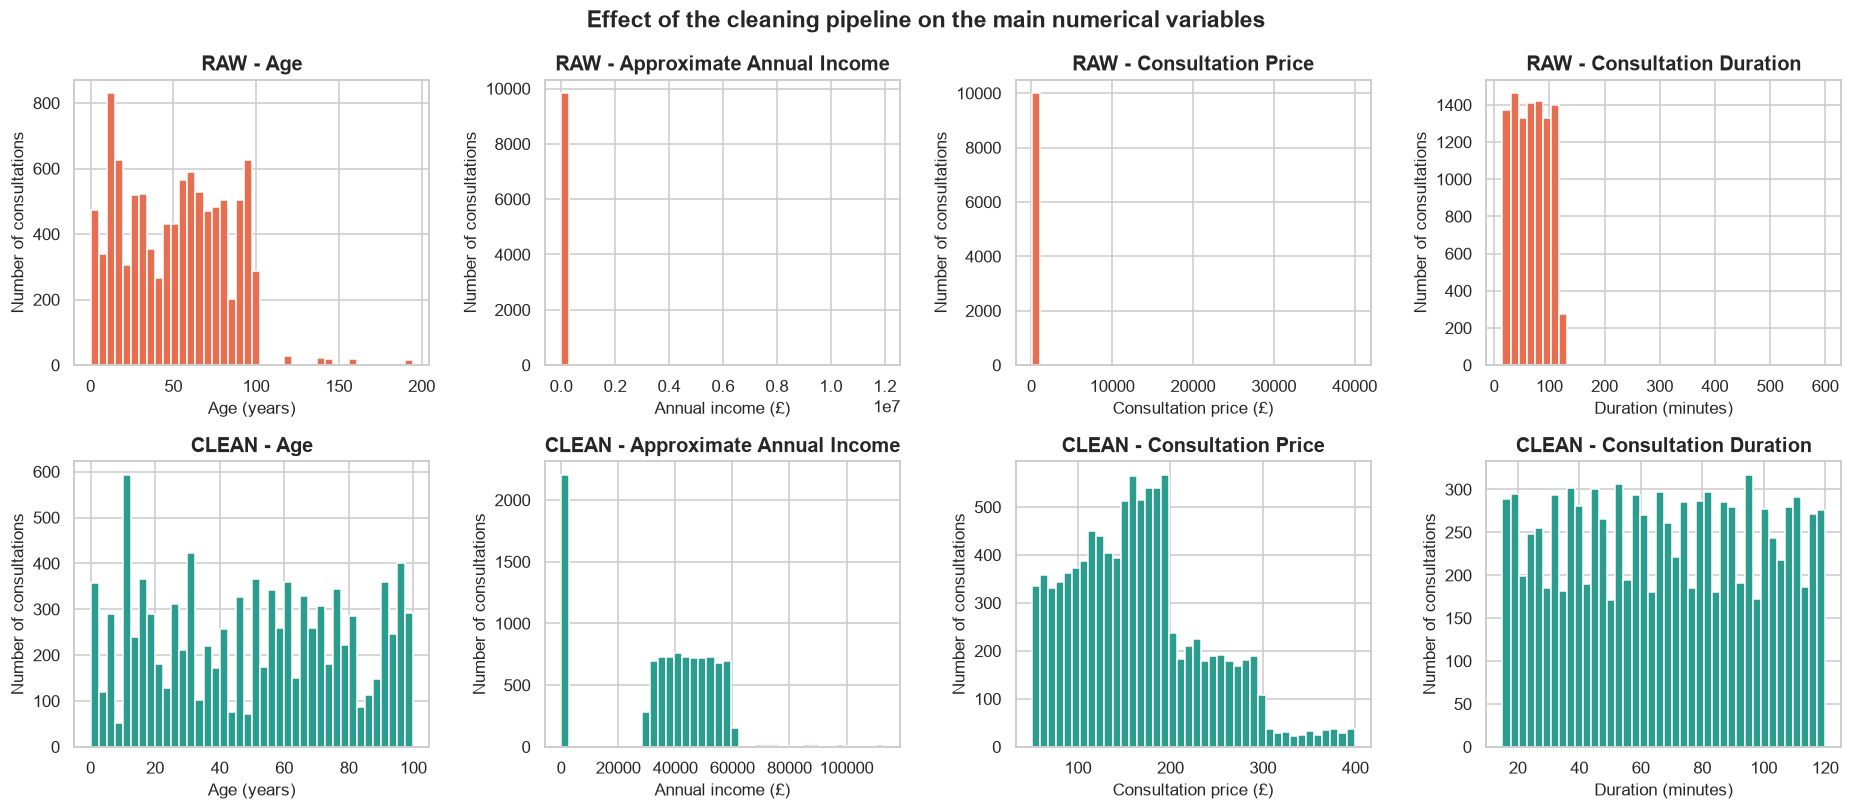

In [30]:
# ---- Visual proof: the same variables before and after cleaning ---------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
pairs = [("Age", "Age (years)"), ("Approximate Annual Income", "Annual income (£)"),
         ("Consultation Price", "Consultation price (£)"), ("Consultation Duration", "Duration (minutes)")]
for j, (col, lab) in enumerate(pairs):
    axes[0, j].hist(raw[col].dropna(), bins=40, color="#e76f51", edgecolor="white")
    axes[0, j].set_title(f"RAW - {col}")
    axes[1, j].hist(clean[col].dropna(), bins=40, color="#2a9d8f", edgecolor="white")
    axes[1, j].set_title(f"CLEAN - {col}")
    for i in (0, 1):
        axes[i, j].set_xlabel(lab); axes[i, j].set_ylabel("Number of consultations")
fig.suptitle("Effect of the cleaning pipeline on the main numerical variables", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

**Reading the audit table.** Every rule that flagged errors in the raw data now returns **0**. The only non-zero rows left are *deliberate*: the 5 patients with unusually young doctor/lawyer profiles (kept and flagged, see log) and the structural `Family History` blanks, which are now explicit and not missing any more.

**Interpretation.** Raw histograms are dominated by a few absurd values that compress the real distribution into a single bar (ages up to 195, incomes in the millions, prices in the tens of thousands). After cleaning, every distribution is readable and consistent with its meaning: ages 0-100, incomes £0-£120k, prices in four department tiers, durations uniform between 15 and 120 minutes. **No patient was removed and only 8 duplicate rows were deleted.**

In [31]:
# ---- The full issue log (this table feeds the report: "key data issues and how we handled them") ------------
issue_df = pd.DataFrame(issue_log)
issue_df["Patients affected"] = issue_df["Patients affected"].astype("Int64")
display(issue_df)
issue_df.to_csv("Data_Quality_Log.csv", index=False)
print(f"{len(issue_df)} documented decisions | log saved to Data_Quality_Log.csv")

,Area,Issue,Rows affected,Patients affected,Decision,Justification
0,Duplicates,Exact duplicate consultations,8,<NA>,Remove (keep first),Identical in all 16 columns including a 15-decimal price: the same record loaded twice.
1,Age,"Impossible ages (>110, e.g. 118, 158, 195)",103,5,Correct (age - 100),Each is a plausible age with a leading '1'; corrected age agrees with profession and education.
2,Age,Isolated missing values inside an otherwise complete patient,56,53,Impute (patient's modal value),The patient's other visits give the true value with certainty.
3,Profession,Patients under 18 recorded with an adult profession,109,6,Correct (-> Student),"Income is £0 on every visit, education is school-level and marital status is Single: three variables agree they are children."
4,Gender,Value changes between visits of the same patient,10,5,Correct (patient's modal value),A person's static attribute cannot change in 6 months; the minority entry is a typing error.
5,Education Level,Isolated missing values inside an otherwise complete patient,29,2,Impute (patient's modal value),The patient's other visits give the true value with certainty.
6,Marital Status,Value changes between visits of the same patient,5,4,Correct (patient's modal value),A person's static attribute cannot change in 6 months; the minority entry is a typing error.
7,Income,"Values above £500,000 (extra digits)",21,10,Invalid -> re-estimate,Nothing between £120k and £1.1M: they are recording errors. Replaced by the patient's median valid income.
8,Income,Missing income on some visits,154,133,Impute (patient median),"Income fluctuates by visit, so the median of the patient's other visits is the most robust estimate."
9,Price,Price > 10x its department median (£25k-£40k),7,7,Correct (remove the 2 inserted digits),Two extra digits after the hundreds; 7/7 corrected prices fall inside the department's band and the insured ones match coverage/rate exa...


19 documented decisions | log saved to Data_Quality_Log.csv


### <font color='turquoise' size='6'>2. Part B – Feature Engineering & ABT Construction </font> <a class="anchor" id="2"></a>
  [Back to TOC](#toc)

**Design principles.**
1. **One row per `Patient ID`** (500 rows), built from the cleaned visit-level table `clean`.
2. Five families of features: *static*, *visit behaviour*, *financial*, *satisfaction*, *recency & activity*.
3. Every feature is documented in a **data dictionary that is generated and checked by code** (if a column is added to the ABT and not documented, the notebook stops).
4. The ABT is **reconciled against the visit-level data** (totals must match exactly) so the next team can trust it.
5. Satisfaction features only use **valid ratings** (1-5); how many ratings were discarded is itself a feature.

## <font color='turquoise'>2.1 Patient-Level ABT Construction</font> <a class="anchor" id="2_1"></a>

### <font color='turquoise'>2.1.1 Static Attributes</font> <a class="anchor" id="2_1_1"></a>

In [32]:
price, cov, dur, sat, prov = "Consultation Price", "Insurance Coverage", "Consultation Duration", "Satisfaction Level", "Insurance Provider"
g = clean.groupby(pid)

# Static attributes are constant within a patient (validated in 1.8), so 'first' is safe; income is the median of visits.
static = g.agg(Age=("Age", "first"), Gender=("Gender", "first"), City=("City of Residence", "first"),
               Profession=("Profession", "first"), Education_Level=("Education Level", "first"),
               Marital_Status=("Marital Status", "first"), Family_History=("Family History", "first"),
               Insurance_Provider=(prov, "first"), Annual_Income=("Approximate Annual Income", "median"),
               Atypical_Profile_Flag=("flag_atypical_age_profession", "max")).reset_index()
static["Atypical_Profile_Flag"] = static["Atypical_Profile_Flag"].astype(int)

# --- derived static features ---------------------------------------------------------------------
age_bins   = [0, 12, 18, 35, 50, 65, 200]
age_labels = ["Child (0-11)", "Teen (12-17)", "Young Adult (18-34)", "Adult (35-49)", "Mature (50-64)", "Senior (65+)"]
static["Age_Group"] = pd.cut(static["Age"], bins=age_bins, labels=age_labels, right=False).astype(str)

# Income bands: 'No income' (students/children) + tertiles of the positive incomes (cut points are data-driven and documented)
pos = static["Annual_Income"] > 0
INCOME_CUTS = static.loc[pos, "Annual_Income"].quantile([1/3, 2/3]).round(-2).tolist()
static["Income_Group"] = "No income"
static.loc[pos, "Income_Group"] = pd.qcut(static.loc[pos, "Annual_Income"], 3, labels=["Low", "Medium", "High"]).astype(str)

edu_rank = {"Pre-school": 0, "Kindergarten": 1, "Elementary school": 2, "Middle school/junior high": 3,
            "High school": 4, "Undergraduate": 5, "Master": 6, "PhD": 7}
static["Education_Rank"] = static["Education_Level"].map(edu_rank).astype(int)
static["Insured"] = (static["Insurance_Provider"] != "Uninsured").astype(int)
static["Insurance_Coverage_Rate"] = static["Insurance_Provider"].map(RATE_ALL)
static["Has_Family_History"] = (static["Family_History"] != "None reported").astype(int)

print(f"Income tertile cut points for positive incomes: £{INCOME_CUTS[0]:,.0f} and £{INCOME_CUTS[1]:,.0f}")
display(static["Age_Group"].value_counts().reindex(age_labels).to_frame("patients").T)
display(static["Income_Group"].value_counts().reindex(["No income", "Low", "Medium", "High"]).to_frame("patients").T)

Income tertile cut points for positive incomes: £43,100 and £46,200


Age_Group,Child (0-11),Teen (12-17),Young Adult (18-34),Adult (35-49),Mature (50-64),Senior (65+)
patients,57,44,84,60,81,174


Income_Group,No income,Low,Medium,High
patients,110,130,130,130


### <font color='turquoise'>2.1.2 Visit Behaviour Features</font> <a class="anchor" id="2_1_2"></a>

Beyond the counts suggested in the brief, we add the **concentration of the department mix** (normalised Shannon entropy: 0 = always the same department, 1 = perfectly spread over all 13). It separates "specialist-loyal" patients from "explorers" and is a strong candidate for segmentation.

In [33]:
dept_counts = pd.crosstab(clean[pid], clean["Department"])
n_dept = dept_counts.shape[1]
dept_share = dept_counts.div(dept_counts.sum(axis=1), axis=0)

vb = g.agg(Total_Visits=("Visit Date", "size"), Distinct_Departments=("Department", "nunique"),
           Avg_Consultation_Duration=(dur, "mean"), Std_Consultation_Duration=(dur, "std"),
           Total_Time_Minutes=(dur, "sum")).reset_index()
vb["Std_Consultation_Duration"] = vb["Std_Consultation_Duration"].fillna(0)

# most frequent department (ties broken alphabetically so the result is deterministic) and its share
top_dept = dept_counts.apply(lambda r: sorted(r[r == r.max()].index)[0], axis=1).rename("Most_Frequent_Department")
top_share = (dept_counts.max(axis=1) / dept_counts.sum(axis=1)).rename("Top_Department_Share")
entropy = (-(dept_share * np.log(dept_share.where(dept_share > 0, 1))).sum(axis=1) / np.log(n_dept)).rename("Department_Diversity_Index")

emerg = pd.DataFrame({"Emergency_Visits": dept_counts["Emergency"],
                      "Emergency_Share": dept_counts["Emergency"] / dept_counts.sum(axis=1)})

dept_pivot = dept_counts.copy()
dept_pivot.columns = ["Visits_" + c.replace(" ", "_") for c in dept_pivot.columns]

behaviour = (vb.merge(top_dept.reset_index(), on=pid).merge(top_share.reset_index(), on=pid)
               .merge(entropy.reset_index(), on=pid).merge(emerg.reset_index(), on=pid)
               .merge(dept_pivot.reset_index(), on=pid))
display(behaviour.iloc[:, :11].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Patient ID,500.0,1249.50,144.48,1000.00,1124.75,1249.50,1374.25,1499.00
Total_Visits,500.0,20.00,4.63,9.00,17.00,20.00,23.00,39.00
Distinct_Departments,500.0,9.91,1.47,5.00,9.00,10.00,11.00,13.00
Avg_Consultation_Duration,500.0,67.47,6.79,48.37,62.88,67.50,71.82,86.00
Std_Consultation_Duration,500.0,30.39,3.18,20.34,28.20,30.32,32.50,38.54
Total_Time_Minutes,500.0,1349.56,340.63,615.00,1093.00,1321.50,1585.75,2467.00
Top_Department_Share,500.0,0.21,0.05,0.11,0.18,0.20,0.24,0.45
Department_Diversity_Index,500.0,0.84,0.06,0.56,0.80,0.84,0.88,0.97
Emergency_Visits,500.0,1.36,1.26,0.00,0.00,1.00,2.00,7.00
Emergency_Share,500.0,0.07,0.06,0.00,0.00,0.06,0.11,0.36


### <font color='turquoise'>2.1.3 Financial Features</font> <a class="anchor" id="2_1_3"></a>

`Out_of_Pocket = price − insurance coverage`, calculated at visit level (in 1.8) and then summed, so coverage can never exceed price.

In [34]:
fin = g.agg(Total_Spent=(price, "sum"), Avg_Consultation_Price=(price, "mean"), Max_Consultation_Price=(price, "max"),
            Total_Insurance_Coverage=(cov, "sum"), Total_Out_of_Pocket=("Out_of_Pocket", "sum")).reset_index()
fin = fin.merge(behaviour[[pid, "Total_Visits"]], on=pid)
fin["Avg_Coverage_per_Visit"]        = fin["Total_Insurance_Coverage"] / fin["Total_Visits"]
fin["Avg_Out_of_Pocket_per_Visit"]   = fin["Total_Out_of_Pocket"] / fin["Total_Visits"]
fin["Insurance_Coverage_Ratio"]      = fin["Total_Insurance_Coverage"] / fin["Total_Spent"]     # share of the bill paid by the insurer
fin["Out_of_Pocket_Share"]           = fin["Total_Out_of_Pocket"] / fin["Total_Spent"]
fin = fin.drop(columns="Total_Visits")
display(fin.drop(columns=pid).describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Total_Spent,500.0,3302.27,823.02,1532.17,2746.92,3253.47,3805.23,6229.69
Avg_Consultation_Price,500.0,165.25,16.73,125.78,154.21,164.93,176.73,244.88
Max_Consultation_Price,500.0,314.44,49.09,192.29,279.78,298.71,360.77,399.22
Total_Insurance_Coverage,500.0,2308.92,1321.43,0.00,1721.35,2529.18,3221.98,5718.72
Total_Out_of_Pocket,500.0,993.36,1189.47,0.00,262.28,610.86,1055.37,5655.72
Avg_Coverage_per_Visit,500.0,115.22,57.88,0.00,109.34,132.49,152.04,244.88
Avg_Out_of_Pocket_per_Visit,500.0,50.03,57.02,0.00,15.00,32.49,51.21,204.57
Insurance_Coverage_Ratio,500.0,0.70,0.34,0.00,0.70,0.80,0.90,1.00
Out_of_Pocket_Share,500.0,0.30,0.34,0.00,0.10,0.20,0.30,1.00


### <font color='turquoise'>2.1.4 Satisfaction Features</font> <a class="anchor" id="2_1_4"></a>

Only valid ratings (1-5) are used. `Satisfaction_Trend` is the slope of a patient's rating over time (rating points per 30 days; positive = improving experience).

In [35]:
rated = clean.dropna(subset=[sat]).sort_values([pid, "Visit Date"])
sg = rated.groupby(pid)[sat]

def rating_slope(d):
    if len(d) < 3 or d["Visit Date"].nunique() < 2:
        return 0.0
    x = (d["Visit Date"] - d["Visit Date"].min()).dt.days.to_numpy() / 30.44
    return float(np.polyfit(x, d[sat].to_numpy(), 1)[0])

satf = pd.DataFrame({"Avg_Satisfaction": sg.mean(), "Min_Satisfaction": sg.min(), "Max_Satisfaction": sg.max(),
                     "Std_Satisfaction": sg.std().fillna(0), "N_Valid_Ratings": sg.size(),
                     "Low_Rating_Share": sg.apply(lambda s: (s <= 2).mean()),
                     "Top_Rating_Share": sg.apply(lambda s: (s >= 4).mean()),
                     "Last_Rating": sg.last()})
satf["Satisfaction_Trend"] = rated.groupby(pid)[["Visit Date", sat]].apply(rating_slope)
satf = satf.reset_index().merge(behaviour[[pid, "Total_Visits"]], on=pid)
satf["N_Invalid_Ratings"] = satf["Total_Visits"] - satf["N_Valid_Ratings"]
satf = satf.drop(columns="Total_Visits")
display(satf.drop(columns=pid).describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
Avg_Satisfaction,500.0,2.984,0.347,1.917,2.769,3.000,3.216,4.071
Min_Satisfaction,500.0,1.026,0.159,1.000,1.000,1.000,1.000,2.000
Max_Satisfaction,500.0,4.970,0.171,4.000,5.000,5.000,5.000,5.000
Std_Satisfaction,500.0,1.401,0.159,0.874,1.300,1.410,1.508,1.801
N_Valid_Ratings,500.0,18.562,4.446,9.000,16.000,18.000,21.000,34.000
Low_Rating_Share,500.0,0.407,0.120,0.071,0.333,0.400,0.479,0.727
Top_Rating_Share,500.0,0.398,0.121,0.083,0.315,0.400,0.474,0.818
Last_Rating,500.0,2.956,1.433,1.000,2.000,3.000,4.000,5.000
Satisfaction_Trend,500.0,-0.009,0.209,-0.689,-0.144,-0.013,0.129,0.714
N_Invalid_Ratings,500.0,1.438,1.209,0.000,0.000,1.000,2.000,6.000


### <font color='turquoise'>2.1.5 Recency and Activity Features</font> <a class="anchor" id="2_1_5"></a>

Reference date = **1 July 2024** (as required). The observation window is exactly six calendar months, so `Visits_per_Month = Total_Visits / 6` is comparable across patients. We also keep the six monthly counts: they allow the next team to build *trend* or *churn* targets without going back to the visit table.

In [36]:
dg = g["Visit Date"].agg(First_Visit_Date="min", Last_Visit_Date="max").reset_index()
dg["Days_Since_Last_Visit"]  = (REFERENCE_DATE - dg["Last_Visit_Date"]).dt.days
dg["Days_Since_First_Visit"] = (REFERENCE_DATE - dg["First_Visit_Date"]).dt.days
dg["Tenure_Days"]            = (dg["Last_Visit_Date"] - dg["First_Visit_Date"]).dt.days

month_counts = pd.crosstab(clean[pid], clean["Visit Date"].dt.month)
month_names = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun"}
month_counts.columns = ["Visits_" + month_names[m] for m in month_counts.columns]

activity = dg.merge(behaviour[[pid, "Total_Visits"]], on=pid).merge(month_counts.reset_index(), on=pid)
OBS_MONTHS = 6
activity["Visits_per_Month"]        = activity["Total_Visits"] / OBS_MONTHS
activity["Active_Months"]           = (activity[[f"Visits_{m}" for m in month_names.values()]] > 0).sum(axis=1)
activity["Avg_Days_Between_Visits"] = activity["Tenure_Days"] / (activity["Total_Visits"] - 1).clip(lower=1)
activity["Visit_Trend"]             = activity[["Visits_Apr", "Visits_May", "Visits_Jun"]].sum(axis=1) - activity[["Visits_Jan", "Visits_Feb", "Visits_Mar"]].sum(axis=1)
activity = activity.drop(columns="Total_Visits")
display(activity[["Days_Since_Last_Visit", "Days_Since_First_Visit", "Tenure_Days", "Visits_per_Month", "Active_Months", "Avg_Days_Between_Visits", "Visit_Trend"]].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Days_Since_Last_Visit,500.0,9.52,9.13,1.00,3.00,6.50,12.00,53.00
Days_Since_First_Visit,500.0,173.83,9.11,126.00,171.00,176.00,180.00,182.00
Tenure_Days,500.0,164.30,12.63,120.00,158.00,167.00,174.00,181.00
Visits_per_Month,500.0,3.33,0.77,1.50,2.83,3.33,3.83,6.50
Active_Months,500.0,5.79,0.47,3.00,6.00,6.00,6.00,6.00
Avg_Days_Between_Visits,500.0,9.14,2.25,4.61,7.48,8.86,10.27,19.75
Visit_Trend,500.0,-0.04,4.58,-13.00,-3.00,0.00,3.00,15.00


### <font color='turquoise'>2.1.6 Assembling and Validating the ABT</font> <a class="anchor" id="2_1_6"></a>

In [37]:
ABT = (static.merge(behaviour, on=pid).merge(fin, on=pid).merge(satf, on=pid).merge(activity, on=pid))
ABT = ABT.sort_values(pid).reset_index(drop=True)

# ---- Reconciliation: the ABT must agree exactly with the visit-level data ---------------------------------
dept_cols  = list(dept_pivot.columns)                                  # the 13 Visits_<Department> columns
month_cols = [f"Visits_{m}" for m in month_names.values()]
abt_checks = {
    "One row per Patient ID (500 unique)":                       ABT[pid].is_unique and len(ABT) == clean[pid].nunique() == 500,
    "No missing values in the ABT":                              ABT.isna().sum().sum() == 0,
    "Sum of Total_Visits = number of cleaned visits":            ABT["Total_Visits"].sum() == len(clean),
    "Department visit columns add up to Total_Visits":           (ABT[dept_cols].sum(axis=1) == ABT["Total_Visits"]).all(),
    "Monthly visit columns add up to Total_Visits":              (ABT[month_cols].sum(axis=1) == ABT["Total_Visits"]).all(),
    "Total_Spent = visit-level sum of prices":                   np.isclose(ABT["Total_Spent"].sum(), clean[price].sum()),
    "Total_Spent = Coverage + Out_of_Pocket (every patient)":    np.allclose(ABT["Total_Spent"], ABT["Total_Insurance_Coverage"] + ABT["Total_Out_of_Pocket"]),
    "Coverage ratio between 0 and 1":                            ABT["Insurance_Coverage_Ratio"].between(0, 1).all(),
    "Valid + invalid ratings = Total_Visits":                    (ABT["N_Valid_Ratings"] + ABT["N_Invalid_Ratings"] == ABT["Total_Visits"]).all(),
    "Min <= Avg <= Max satisfaction":                            ((ABT["Min_Satisfaction"] <= ABT["Avg_Satisfaction"]) & (ABT["Avg_Satisfaction"] <= ABT["Max_Satisfaction"])).all(),
    "Days since last visit >= 1 (reference date is after the data)": (ABT["Days_Since_Last_Visit"] >= 1).all(),
    "Distinct departments between 1 and 13":                     ABT["Distinct_Departments"].between(1, 13).all(),
}
for k, v in abt_checks.items():
    print(("PASS  " if v else "FAIL  ") + k)
assert all(abt_checks.values()), "ABT validation failed"
print(f"\nABT shape: {ABT.shape[0]} patients x {ABT.shape[1]} columns")
ABT.head()

PASS  One row per Patient ID (500 unique)
PASS  No missing values in the ABT
PASS  Sum of Total_Visits = number of cleaned visits
PASS  Department visit columns add up to Total_Visits
PASS  Monthly visit columns add up to Total_Visits
PASS  Total_Spent = visit-level sum of prices
PASS  Total_Spent = Coverage + Out_of_Pocket (every patient)
PASS  Coverage ratio between 0 and 1
PASS  Valid + invalid ratings = Total_Visits
PASS  Min <= Avg <= Max satisfaction
PASS  Days since last visit >= 1 (reference date is after the data)
PASS  Distinct departments between 1 and 13

ABT shape: 500 patients x 74 columns


,Patient ID,Age,Gender,City,Profession,Education_Level,Marital_Status,Family_History,Insurance_Provider,Annual_Income,Atypical_Profile_Flag,Age_Group,Income_Group,Education_Rank,Insured,Insurance_Coverage_Rate,Has_Family_History,Total_Visits,Distinct_Departments,Avg_Consultation_Duration,Std_Consultation_Duration,Total_Time_Minutes,Most_Frequent_Department,Top_Department_Share,Department_Diversity_Index,Emergency_Visits,Emergency_Share,Visits_Allergology,Visits_Cardiology,Visits_Dermatology,...,Total_Out_of_Pocket,Avg_Coverage_per_Visit,Avg_Out_of_Pocket_per_Visit,Insurance_Coverage_Ratio,Out_of_Pocket_Share,Avg_Satisfaction,Min_Satisfaction,Max_Satisfaction,Std_Satisfaction,N_Valid_Ratings,Low_Rating_Share,Top_Rating_Share,Last_Rating,Satisfaction_Trend,N_Invalid_Ratings,First_Visit_Date,Last_Visit_Date,Days_Since_Last_Visit,Days_Since_First_Visit,Tenure_Days,Visits_Jan,Visits_Feb,Visits_Mar,Visits_Apr,Visits_May,Visits_Jun,Visits_per_Month,Active_Months,Avg_Days_Between_Visits,Visit_Trend
0,1000,58.0,Female,Birmingham,Artist,Undergraduate,Divorced,Hypertension,Provider D,45692.5,0,Mature (50-64),Medium,5,1,1.0,1,20,10,65.700000,30.317791,1314,Allergology,0.150000,0.877312,2,0.100000,3,2,1,...,0.000000,175.201749,0.000000,1.0,0.0,2.600000,1.0,5.0,1.429022,20,0.500000,0.400000,4.0,0.076153,0,2024-01-01,2024-06-27,4,182,178,3,2,6,3,3,3,3.333333,6,9.368421,-2
1,1001,55.0,Male,Liverpool,Lawyer,Undergraduate,Married,Heart Disease,Provider C,41338.5,0,Mature (50-64),Low,5,1,0.7,1,16,10,60.500000,24.024987,968,ENT,0.187500,0.865524,2,0.125000,1,2,0,...,719.095744,104.868129,44.943484,0.7,0.3,2.769231,1.0,5.0,1.786703,13,0.461538,0.461538,4.0,0.247298,3,2024-01-02,2024-06-27,4,181,177,4,3,3,1,3,2,2.666667,6,11.800000,-4
2,1002,10.0,Female,Liverpool,Student,Elementary school,Single,Cancer,Provider C,0.0,0,Child (0-11),No income,2,1,0.7,1,18,10,71.055556,31.062503,1279,Psychiatry,0.277778,0.809802,0,0.000000,3,0,1,...,875.776442,113.526576,48.654247,0.7,0.3,3.352941,1.0,5.0,1.366619,17,0.235294,0.411765,3.0,-0.168159,1,2024-01-06,2024-06-23,8,177,169,3,4,3,1,4,3,3.000000,6,9.941176,-2
3,1003,91.0,Male,Manchester,Retired,Master,Married,Cancer,Provider A,43130.5,0,Senior (65+),Medium,6,1,0.8,1,25,11,61.400000,27.784888,1535,Psychiatry,0.200000,0.875323,2,0.080000,1,0,0,...,897.222663,143.555626,35.888907,0.8,0.2,3.086957,1.0,5.0,1.504933,23,0.391304,0.478261,5.0,-0.261610,2,2024-01-03,2024-06-29,2,180,178,3,3,5,5,5,4,4.166667,6,7.416667,3
4,1004,11.0,Male,Glasgow,Student,Middle school/junior high,Single,Cancer,Provider B,0.0,0,Child (0-11),No income,3,1,0.9,1,26,9,62.653846,33.665344,1629,General Practice,0.192308,0.805334,3,0.115385,1,3,0,...,448.614264,155.289553,17.254395,0.9,0.1,3.043478,1.0,5.0,1.609016,23,0.434783,0.478261,5.0,0.102840,3,2024-01-01,2024-06-28,3,182,179,7,2,4,4,2,7,4.333333,6,7.160000,0


## <font color='turquoise'>2.2 Data Dictionary</font> <a class="anchor" id="2_2"></a>

Built programmatically and **cross-checked against the ABT columns**: the cell fails if any feature is undocumented or if the dictionary mentions a feature that does not exist.

In [38]:
DD = []
def add(name, group, definition, calc):
    DD.append({"Feature": name, "Group": group, "Definition": definition, "How it was calculated": calc})

# --- identifier & static ----------------------------------------------------------------------------------
add("Patient ID", "Identifier", "Unique patient identifier (primary key of the ABT).", "Taken from the source data; one row per ID.")
add("Age", "Static", "Patient age in years.", "Cleaned age (typos like 158 -> 58 corrected, gaps filled with the patient's modal age); constant per patient.")
add("Gender", "Static", "Female, Male or Other.", "Patient's modal gender across visits (conflicting minority entries corrected).")
add("City", "Static", "City of residence.", "Source 'City of Residence' (never changed within a patient).")
add("Profession", "Static", "Patient's profession.", "Modal profession; patients under 18 recoded to 'Student'.")
add("Education_Level", "Static", "Highest education level.", "Modal education level across visits (2 patients had isolated blanks).")
add("Marital_Status", "Static", "Single, Married, Divorced or Widowed.", "Modal value across visits (minority typing errors corrected).")
add("Family_History", "Static", "Disease in the family history (Cancer, Diabetes, Heart Disease, Hypertension) or 'None reported'.", "Source value; structural blanks recoded to 'None reported'.")
add("Insurance_Provider", "Static", "Provider A-D, or 'Uninsured'.", "Provider recorded on the patient's visits; recovered from the coverage rate where missing; blank + £0 coverage -> 'Uninsured'.")
add("Annual_Income", "Static", "Approximate annual income (£).", "Median of the patient's valid recorded incomes (robust to visit-to-visit noise); recording errors > £500k excluded.")
add("Atypical_Profile_Flag", "Static", "1 if the patient is a doctor aged < 24 or a lawyer aged < 22 (unusual but plausible, kept).", "Max over the patient's visits of flag_atypical_age_profession.")
add("Age_Group", "Static (derived)", "Life-stage band of the patient.", "pd.cut on Age: Child 0-11, Teen 12-17, Young Adult 18-34, Adult 35-49, Mature 50-64, Senior 65+.")
add("Income_Group", "Static (derived)", "Income band.", f"'No income' if Annual_Income = 0; otherwise tertiles of positive incomes (Low <= £{INCOME_CUTS[0]:,.0f} < Medium <= £{INCOME_CUTS[1]:,.0f} < High).")
add("Education_Rank", "Static (derived)", "Ordinal encoding of education (0 Pre-school ... 7 PhD).", "Mapping: Pre-school 0, Kindergarten 1, Elementary 2, Middle 3, High school 4, Undergraduate 5, Master 6, PhD 7.")
add("Insured", "Static (derived)", "1 if the patient has an insurance provider, 0 if self-pay.", "Insurance_Provider != 'Uninsured'.")
add("Insurance_Coverage_Rate", "Static (derived)", "Share of the price the patient's provider pays (A 0.8, B 0.9, C 0.7, D 1.0, Uninsured 0).", "Rate learned from the data (median coverage / price per provider) and mapped to the provider.")
add("Has_Family_History", "Static (derived)", "1 if any family disease is recorded.", "Family_History != 'None reported'.")

# --- visit behaviour -------------------------------------------------------------------------------------------
add("Total_Visits", "Visit behaviour", "Number of consultations in Jan-Jun 2024.", "Count of the patient's rows in the cleaned visit table.")
add("Distinct_Departments", "Visit behaviour", "Number of different departments visited (1-13).", "nunique(Department) per patient.")
add("Avg_Consultation_Duration", "Visit behaviour", "Average consultation length (minutes).", "Mean of Consultation Duration (invalid durations replaced by the patient's median).")
add("Std_Consultation_Duration", "Visit behaviour", "Variability of consultation length (minutes).", "Sample standard deviation of duration per patient.")
add("Total_Time_Minutes", "Visit behaviour", "Total time spent in consultations (minutes).", "Sum of Consultation Duration.")
add("Most_Frequent_Department", "Visit behaviour", "Department the patient visited most often.", "Mode of Department; ties broken alphabetically.")
add("Top_Department_Share", "Visit behaviour", "Share of the visits that went to the most frequent department.", "max(department count) / Total_Visits.")
add("Department_Diversity_Index", "Visit behaviour", "How spread the visits are over departments (0 = one department, 1 = evenly over all 13).", "Shannon entropy of the department shares divided by ln(13).")
add("Emergency_Visits", "Visit behaviour", "Number of Emergency consultations.", "Count of rows with Department = 'Emergency'.")
add("Emergency_Share", "Visit behaviour", "Share of visits that were Emergency.", "Emergency_Visits / Total_Visits.")
for d in sorted(dept_counts.columns):
    add("Visits_" + d.replace(" ", "_"), "Visit behaviour (department mix)", f"Number of visits to {d}.", f"Count of the patient's rows with Department = '{d}'.")

# --- financial ----------------------------------------------------------------------------------------------------
add("Total_Spent", "Financial", "Total consultation price over the period (£).", "Sum of Consultation Price (before insurance).")
add("Avg_Consultation_Price", "Financial", "Average price per visit (£).", "Mean of Consultation Price.")
add("Max_Consultation_Price", "Financial", "Most expensive visit (£).", "Max of Consultation Price.")
add("Total_Insurance_Coverage", "Financial", "Total paid by the insurer (£).", "Sum of Insurance Coverage (recomputed as rate x price where it was missing or inconsistent).")
add("Total_Out_of_Pocket", "Financial", "Total paid by the patient (£).", "Sum over visits of (Consultation Price - Insurance Coverage).")
add("Avg_Coverage_per_Visit", "Financial", "Average insurer payment per visit (£).", "Total_Insurance_Coverage / Total_Visits.")
add("Avg_Out_of_Pocket_per_Visit", "Financial", "Average patient payment per visit (£).", "Total_Out_of_Pocket / Total_Visits.")
add("Insurance_Coverage_Ratio", "Financial", "Share of the total bill paid by the insurer (0-1).", "Total_Insurance_Coverage / Total_Spent.")
add("Out_of_Pocket_Share", "Financial", "Share of the total bill paid by the patient (0-1).", "Total_Out_of_Pocket / Total_Spent = 1 - Insurance_Coverage_Ratio.")

# --- satisfaction -----------------------------------------------------------------------------------------------------
add("Avg_Satisfaction", "Satisfaction", "Average valid rating (1-5).", "Mean of Satisfaction Level over valid ratings only (the invalid '6' is excluded).")
add("Min_Satisfaction", "Satisfaction", "Lowest valid rating.", "Min of valid ratings.")
add("Max_Satisfaction", "Satisfaction", "Highest valid rating.", "Max of valid ratings.")
add("Std_Satisfaction", "Satisfaction", "Inconsistency of the ratings (std. dev.).", "Sample std of valid ratings (0 if only one rating).")
add("N_Valid_Ratings", "Satisfaction", "Number of valid ratings available for the patient.", "Count of non-missing Satisfaction Level after cleaning.")
add("N_Invalid_Ratings", "Satisfaction", "Number of ratings discarded as invalid (value 6).", "Total_Visits - N_Valid_Ratings. Useful as a data-reliability indicator.")
add("Low_Rating_Share", "Satisfaction", "Share of valid ratings that are low (1 or 2).", "mean(rating <= 2) over valid ratings.")
add("Top_Rating_Share", "Satisfaction", "Share of valid ratings that are high (4 or 5).", "mean(rating >= 4) over valid ratings.")
add("Last_Rating", "Satisfaction", "Most recent valid rating.", "Rating of the latest visit that has a valid rating.")
add("Satisfaction_Trend", "Satisfaction", "Direction of the experience: change in rating per 30 days (>0 improving).", "Slope of a least-squares line rating ~ time; 0 if < 3 ratings or all on one day.")

# --- recency & activity ---------------------------------------------------------------------------------------------------
add("First_Visit_Date", "Recency & activity", "Date of the first visit in the period.", "min(Visit Date).")
add("Last_Visit_Date", "Recency & activity", "Date of the last visit in the period.", "max(Visit Date).")
add("Days_Since_Last_Visit", "Recency & activity", "Days between the last visit and the reference date 1 July 2024.", "(2024-07-01 - Last_Visit_Date).days.")
add("Days_Since_First_Visit", "Recency & activity", "Days between the first visit and the reference date.", "(2024-07-01 - First_Visit_Date).days.")
add("Tenure_Days", "Recency & activity", "Days between the first and the last visit.", "(Last_Visit_Date - First_Visit_Date).days.")
for m in month_names.values():
    add(f"Visits_{m}", "Recency & activity (monthly)", f"Number of visits in {m} 2024.", f"Count of rows with Visit Date in {m} 2024.")
add("Visits_per_Month", "Recency & activity", "Average visits per month.", "Total_Visits / 6 (observation window = 6 months).")
add("Active_Months", "Recency & activity", "Number of months (of 6) with at least one visit.", "Count of monthly columns > 0.")
add("Avg_Days_Between_Visits", "Recency & activity", "Average gap between consecutive visits (days).", "Tenure_Days / (Total_Visits - 1).")
add("Visit_Trend", "Recency & activity", "Change in activity: visits in Apr-Jun minus visits in Jan-Mar (>0 growing).", "sum(Visits_Apr..Jun) - sum(Visits_Jan..Mar).")

data_dictionary = pd.DataFrame(DD)
data_dictionary["Type"] = data_dictionary["Feature"].map(ABT.dtypes.astype(str))

# ---- the dictionary and the ABT must describe exactly the same set of columns ----------------------------------------
undocumented = set(ABT.columns) - set(data_dictionary["Feature"])
ghost        = set(data_dictionary["Feature"]) - set(ABT.columns)
assert not undocumented, f"Undocumented features: {undocumented}"
assert not ghost, f"Documented but missing from the ABT: {ghost}"
assert data_dictionary["Feature"].is_unique

data_dictionary = data_dictionary.set_index("Feature").loc[ABT.columns].reset_index()
print(f"{len(data_dictionary)} features documented | ABT columns: {ABT.shape[1]} | undocumented: 0")
display(data_dictionary)

74 features documented | ABT columns: 74 | undocumented: 0


,index,Group,Definition,How it was calculated,Type
0,Patient ID,Identifier,Unique patient identifier (primary key of the ABT).,Taken from the source data; one row per ID.,int64
1,Age,Static,Patient age in years.,"Cleaned age (typos like 158 -> 58 corrected, gaps filled with the patient's modal age); constant per patient.",float64
2,Gender,Static,"Female, Male or Other.",Patient's modal gender across visits (conflicting minority entries corrected).,str
3,City,Static,City of residence.,Source 'City of Residence' (never changed within a patient).,str
4,Profession,Static,Patient's profession.,Modal profession; patients under 18 recoded to 'Student'.,str
...,...,...,...,...,...
69,Visits_Jun,Recency & activity (monthly),Number of visits in Jun 2024.,Count of rows with Visit Date in Jun 2024.,int64
70,Visits_per_Month,Recency & activity,Average visits per month.,Total_Visits / 6 (observation window = 6 months).,float64
71,Active_Months,Recency & activity,Number of months (of 6) with at least one visit.,Count of monthly columns > 0.,int64
72,Avg_Days_Between_Visits,Recency & activity,Average gap between consecutive visits (days).,Tenure_Days / (Total_Visits - 1).,float64


### Most important features (and why)

| Family | Features to look at first | Why they matter |
|---|---|---|
| **Value / frequency** | `Total_Visits`, `Total_Spent`, `Avg_Consultation_Price`, `Emergency_Share` | Visit volume and the department mix (Emergency is the most expensive tier) explain nearly all of the spend. |
| **Insurance** | `Insured`, `Insurance_Provider`, `Insurance_Coverage_Ratio`, `Out_of_Pocket_Share` | Separates self-pay patients (who pay 100 %) from insured ones; coverage is deterministic per provider. |
| **Behaviour** | `Distinct_Departments`, `Department_Diversity_Index`, `Most_Frequent_Department` | Distinguishes loyal single-department patients from patients navigating many services. |
| **Experience** | `Avg_Satisfaction`, `Low_Rating_Share`, `Satisfaction_Trend`, `N_Invalid_Ratings` | Natural targets for satisfaction analysis; the last one tells how much to trust a patient's score. |
| **Engagement** | `Days_Since_Last_Visit`, `Visits_per_Month`, `Visit_Trend`, monthly counts | Basis for recency/churn-type targets and demand forecasting. |
| **Profile** | `Age_Group`, `Profession`, `Income_Group`, `Education_Rank` | Segmentation descriptors. Note that `Age`, `Profession` and `Education` are strongly linked (students are children, retired people are 70+), so they carry overlapping information. |

## <font color='turquoise'>2.3 Exporting the ABT</font> <a class="anchor" id="2_3"></a>

In [39]:
ABT.to_csv("ABT_city_hospital.csv", index=False)                  # index=False: Patient ID is the key, no stray index column
data_dictionary.to_csv("Data_Dictionary_city_hospital.csv", index=False)

# Round-trip check: what is on disk is what we validated
check = pd.read_csv("ABT_city_hospital.csv")
assert check.shape == ABT.shape and check[pid].is_unique and check.isna().sum().sum() == 0
print(f"Saved ABT_city_hospital.csv  -> {check.shape[0]} rows (one per patient) x {check.shape[1]} columns")
print("Saved Data_Dictionary_city_hospital.csv and Data_Quality_Log.csv")

Saved ABT_city_hospital.csv  -> 500 rows (one per patient) x 74 columns
Saved Data_Dictionary_city_hospital.csv and Data_Quality_Log.csv


### <font color='turquoise' size='6'>3. Part C – Exploratory Visualization & Insights </font> <a class="anchor" id="3"></a>
  [Back to TOC](#toc)

**Reading guide.** Patient-level questions (who are our patients?) use the **ABT** (one row per patient, so each patient counts once). Visit-level questions (how busy is each department? how satisfied are visitors?) use the **cleaned visit table** (`clean`), because a patient with 35 visits should weigh more than one with 9. Wherever a visible difference could just be chance, we add a **statistical test** and say so: with 500 patients and ~20 visits each, random noise alone creates visible gaps.

In [40]:
# ---- shared helpers and orders for all charts --------------------------------------------------------------
DEPT_ORDER = clean["Department"].value_counts().index.tolist()          # busiest first
AGE_ORDER  = age_labels
INC_ORDER  = ["No income", "Low", "Medium", "High"]
PROV_ORDER = ["Provider A", "Provider B", "Provider C", "Provider D", "Uninsured"]
GENDER_COL = {"Female": "#e76f51", "Male": "#264653", "Other": "#e9c46a"}
N_PAT      = len(ABT)
MEAN_SAT   = clean[sat].mean()

# visit table enriched with the patient segments derived in the ABT
vis = clean.merge(ABT[[pid, "Age_Group", "Income_Group"]], on=pid, how="left")

def chi2_test(ct):
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    return chi2, p, float(np.sqrt(chi2 / (n * (min(ct.shape) - 1))))     # Cramer's V = effect size

def pct_labels(ax, total):
    for b in ax.patches:                                         # robust to seaborn's hue containers
        h = b.get_height()
        if np.isfinite(h) and h > 0:
            ax.annotate(f"{h:.0f}\n({h/total:.0%})", (b.get_x() + b.get_width() / 2, h), ha="center", va="bottom", fontsize=9)

## <font color='turquoise'>3.1 Patient Demographics</font> <a class="anchor" id="3_1"></a>

### <font color='turquoise'>3.1.1 Age Distribution</font> <a class="anchor" id="3_1_1"></a>

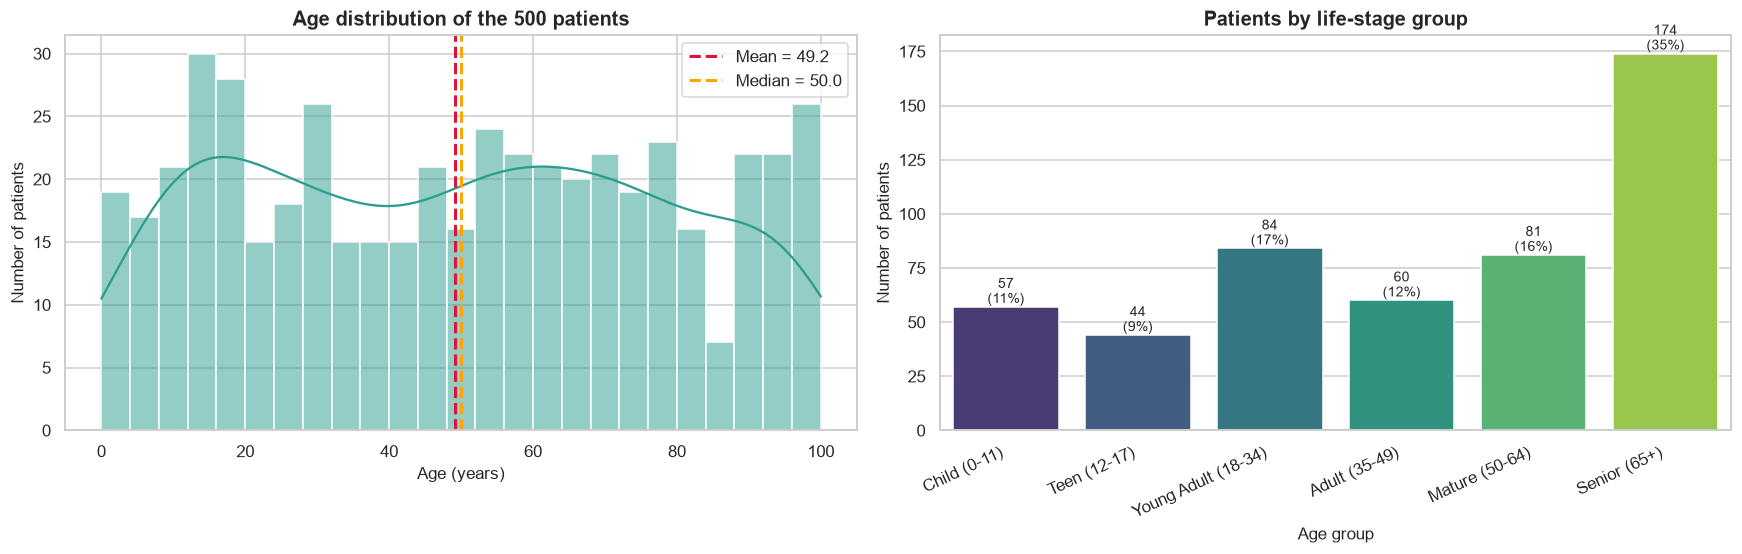

Patients under 18: 101 (20%) | aged 65+: 174 (35%) | aged 35-64: 141


In [41]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.2))
sns.histplot(ABT["Age"], bins=25, kde=True, color="#2a9d8f", edgecolor="white", ax=ax[0])
ax[0].axvline(ABT["Age"].mean(), color="crimson", ls="--", lw=2, label=f"Mean = {ABT['Age'].mean():.1f}")
ax[0].axvline(ABT["Age"].median(), color="orange", ls="--", lw=2, label=f"Median = {ABT['Age'].median():.1f}")
ax[0].set_title("Age distribution of the 500 patients")
ax[0].set_xlabel("Age (years)"); ax[0].set_ylabel("Number of patients"); ax[0].legend()

ag = ABT["Age_Group"].value_counts().reindex(AGE_ORDER)
sns.barplot(x=ag.index, y=ag.values, hue=ag.index, palette="viridis", legend=False, ax=ax[1])
pct_labels(ax[1], N_PAT)
ax[1].set_title("Patients by life-stage group")
ax[1].set_xlabel("Age group"); ax[1].set_ylabel("Number of patients")
plt.setp(ax[1].get_xticklabels(), rotation=25, ha="right")
plt.tight_layout(); plt.show()

print(f"Patients under 18: {(ABT['Age'] < 18).sum()} ({(ABT['Age'] < 18).mean():.0%}) | aged 65+: {(ABT['Age'] >= 65).sum()} ({(ABT['Age'] >= 65).mean():.0%}) | aged 35-64: {ABT['Age'].between(35, 64).sum()}")

**Interpretation.** The age profile is **bimodal, not bell-shaped**: one block of children and teenagers (101 patients, 20 %) and a very large block of seniors (174 patients, 35 % are 65+), with a thinner middle (141 patients aged 35-64). The mean (≈ 49) and median (≈ 50) sit in the valley between the two peaks, so *"the average patient is 50"* describes almost nobody. This follows from the profession structure (110 students, 174 retired) and means any model should use age groups or interactions with profession rather than a single linear age effect. Paediatric and geriatric needs are both substantial.

### <font color='turquoise'>3.1.2 Gender Distribution</font> <a class="anchor" id="3_1_2"></a>

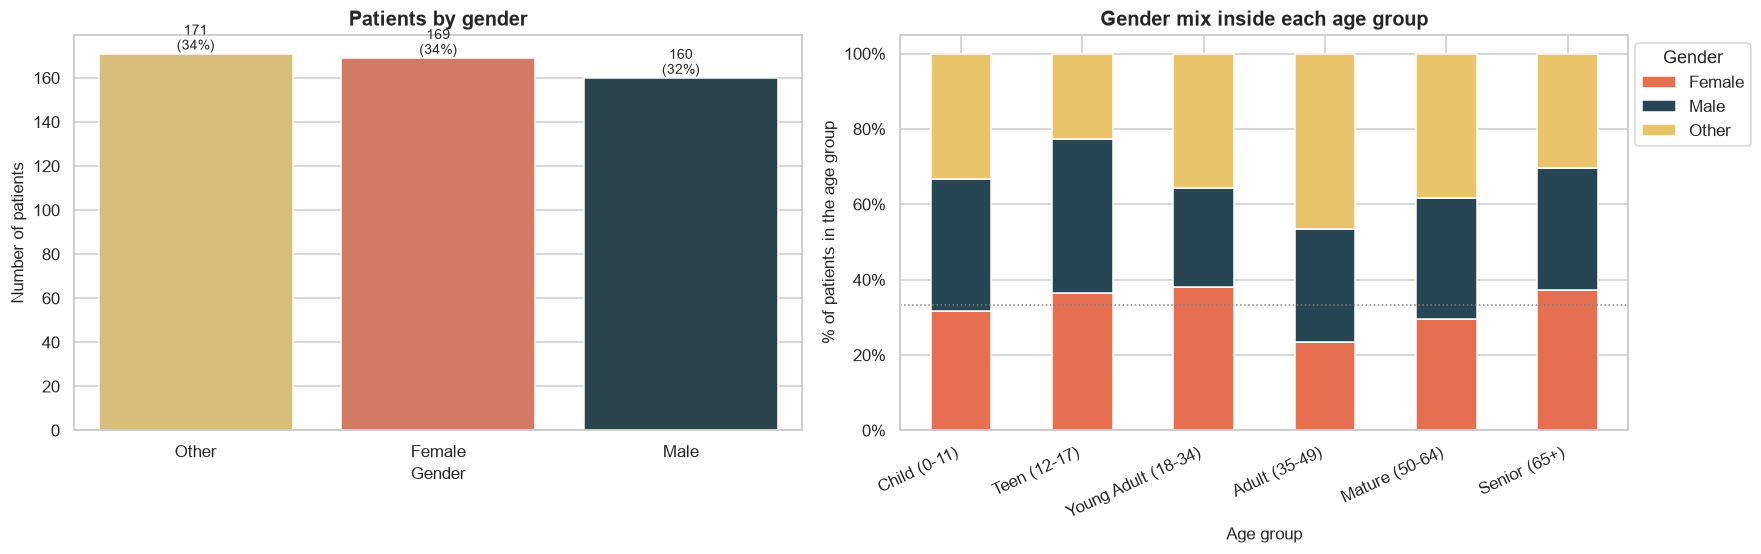

Gender vs age group: chi2 = 11.5, p = 0.323, Cramer's V = 0.11


In [42]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.2))
gc = ABT["Gender"].value_counts()
sns.barplot(x=gc.index, y=gc.values, hue=gc.index, palette=GENDER_COL, legend=False, ax=ax[0])
pct_labels(ax[0], N_PAT)
ax[0].set_title("Patients by gender"); ax[0].set_xlabel("Gender"); ax[0].set_ylabel("Number of patients")

gx = (pd.crosstab(ABT["Age_Group"], ABT["Gender"], normalize="index") * 100).reindex(AGE_ORDER)[["Female", "Male", "Other"]]
gx.plot(kind="bar", stacked=True, ax=ax[1], color=[GENDER_COL[c] for c in gx.columns], edgecolor="white", rot=25)
ax[1].axhline(100 / 3, color="grey", ls=":", lw=1)
ax[1].set_title("Gender mix inside each age group")
ax[1].set_xlabel("Age group"); ax[1].set_ylabel("% of patients in the age group")
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter()); ax[1].legend(title="Gender", loc="upper right", bbox_to_anchor=(1.18, 1))
plt.setp(ax[1].get_xticklabels(), ha="right")
plt.tight_layout(); plt.show()

chi2, p, v = chi2_test(pd.crosstab(ABT["Age_Group"], ABT["Gender"]))
print(f"Gender vs age group: chi2 = {chi2:.1f}, p = {p:.3f}, Cramer's V = {v:.2f}")

**Interpretation.** Gender is almost perfectly balanced: Other 34.2 %, Female 33.8 %, Male 32.0 %. The mix inside each age group stays close to the one-third line and the differences are not significant (chi-square p = 0.32, Cramér's V = 0.11, small), so gender does not hide an age effect. Practical note: "Other" is a full third of the patients, which is unusually high and should be confirmed with the data owners (coding convention vs. real distribution) before gender is used as a segmentation driver.

### <font color='turquoise'>3.1.3 Income Distribution</font> <a class="anchor" id="3_1_3"></a>

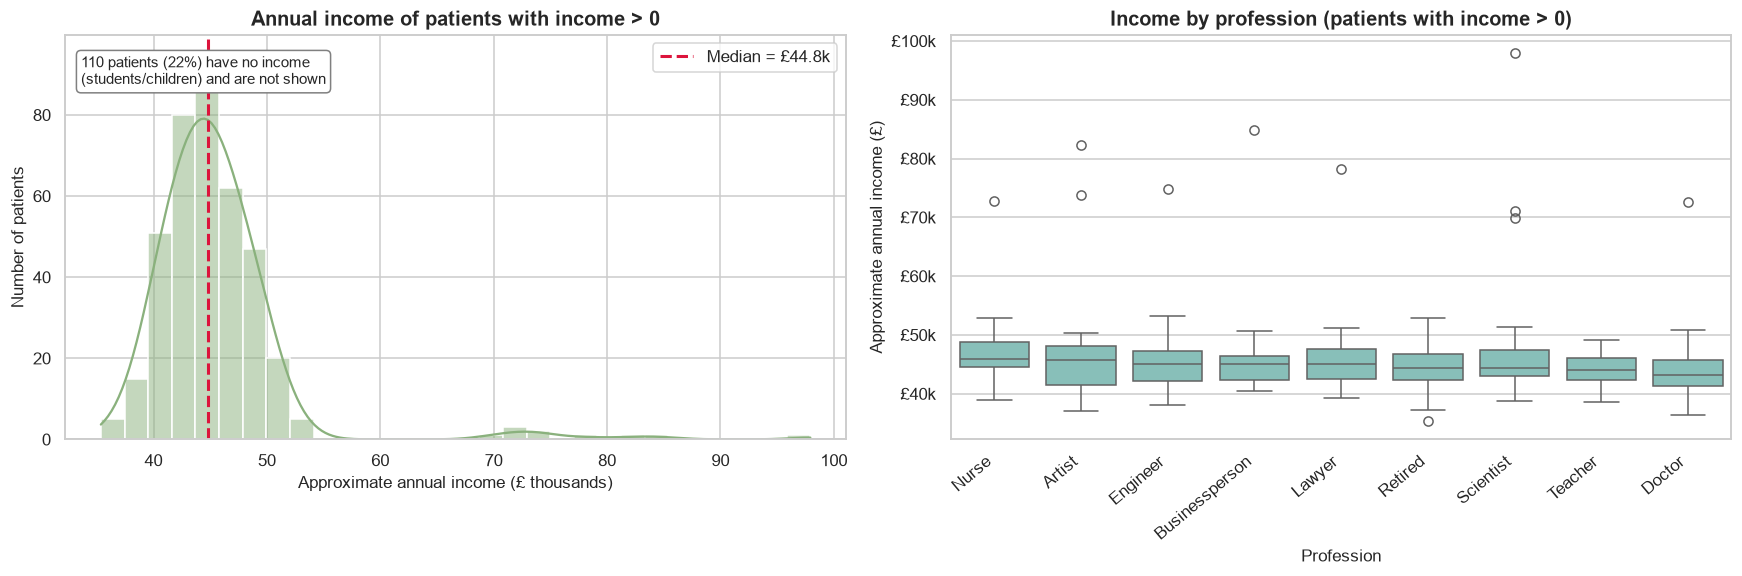

Income differs between professions? Kruskal-Wallis p = 0.318
{'Nurse': 45900.0, 'Artist': 45700.0, 'Businessperson': 45000.0, 'Lawyer': 45000.0, 'Engineer': 45000.0, 'Scientist': 44400.0, 'Retired': 44400.0, 'Teacher': 44000.0, 'Doctor': 43200.0}


In [43]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.4))
pos_inc = ABT.loc[ABT["Annual_Income"] > 0, "Annual_Income"]
sns.histplot(pos_inc / 1000, bins=30, kde=True, color="#8ab17d", edgecolor="white", ax=ax[0])
ax[0].axvline(pos_inc.median() / 1000, color="crimson", ls="--", lw=2, label=f"Median = £{pos_inc.median()/1000:.1f}k")
ax[0].text(0.02, 0.95, f"{(ABT['Annual_Income'] == 0).sum()} patients ({(ABT['Annual_Income'] == 0).mean():.0%}) have no income\n(students/children) and are not shown",
           transform=ax[0].transAxes, va="top", fontsize=10, bbox=dict(boxstyle="round", fc="white", ec="grey"))
ax[0].set_title("Annual income of patients with income > 0")
ax[0].set_xlabel("Approximate annual income (£ thousands)"); ax[0].set_ylabel("Number of patients"); ax[0].legend(loc="upper right")

prof_order = (ABT[ABT["Annual_Income"] > 0].groupby("Profession")["Annual_Income"].median().sort_values(ascending=False).index)
sns.boxplot(data=ABT[ABT["Annual_Income"] > 0], x="Profession", y="Annual_Income", order=prof_order, color="#7fc8c0", ax=ax[1])
ax[1].set_title("Income by profession (patients with income > 0)")
ax[1].set_xlabel("Profession"); ax[1].set_ylabel("Approximate annual income (£)")
ax[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"£{x/1000:.0f}k"))
plt.setp(ax[1].get_xticklabels(), rotation=40, ha="right")
plt.tight_layout(); plt.show()

kw = stats.kruskal(*[g_["Annual_Income"].values for _, g_ in ABT[ABT["Annual_Income"] > 0].groupby("Profession")])
print(f"Income differs between professions? Kruskal-Wallis p = {kw.pvalue:.3f}")
print(ABT[ABT["Annual_Income"] > 0].groupby("Profession")["Annual_Income"].median().round(-2).sort_values(ascending=False).to_dict())

**Interpretation.** 110 patients (22 %) have no income (students and children); everyone else sits in a narrow band between roughly £30k and £60k with a median of ≈ £44-45k, with no long right tail. More surprising is the right panel: median income is almost identical across professions (£43-46k) and the difference is not significant (p = 0.32); doctors are not better paid than nurses or artists. Income therefore behaves more like a generic "has income / has none" indicator than a socio-economic ladder, and the next team should not expect it to discriminate between professions.

## <font color='turquoise'>3.2 Department and Service Usage</font> <a class="anchor" id="3_2"></a>

### <font color='turquoise'>3.2.1 Consultations by Department</font> <a class="anchor" id="3_2_1"></a>

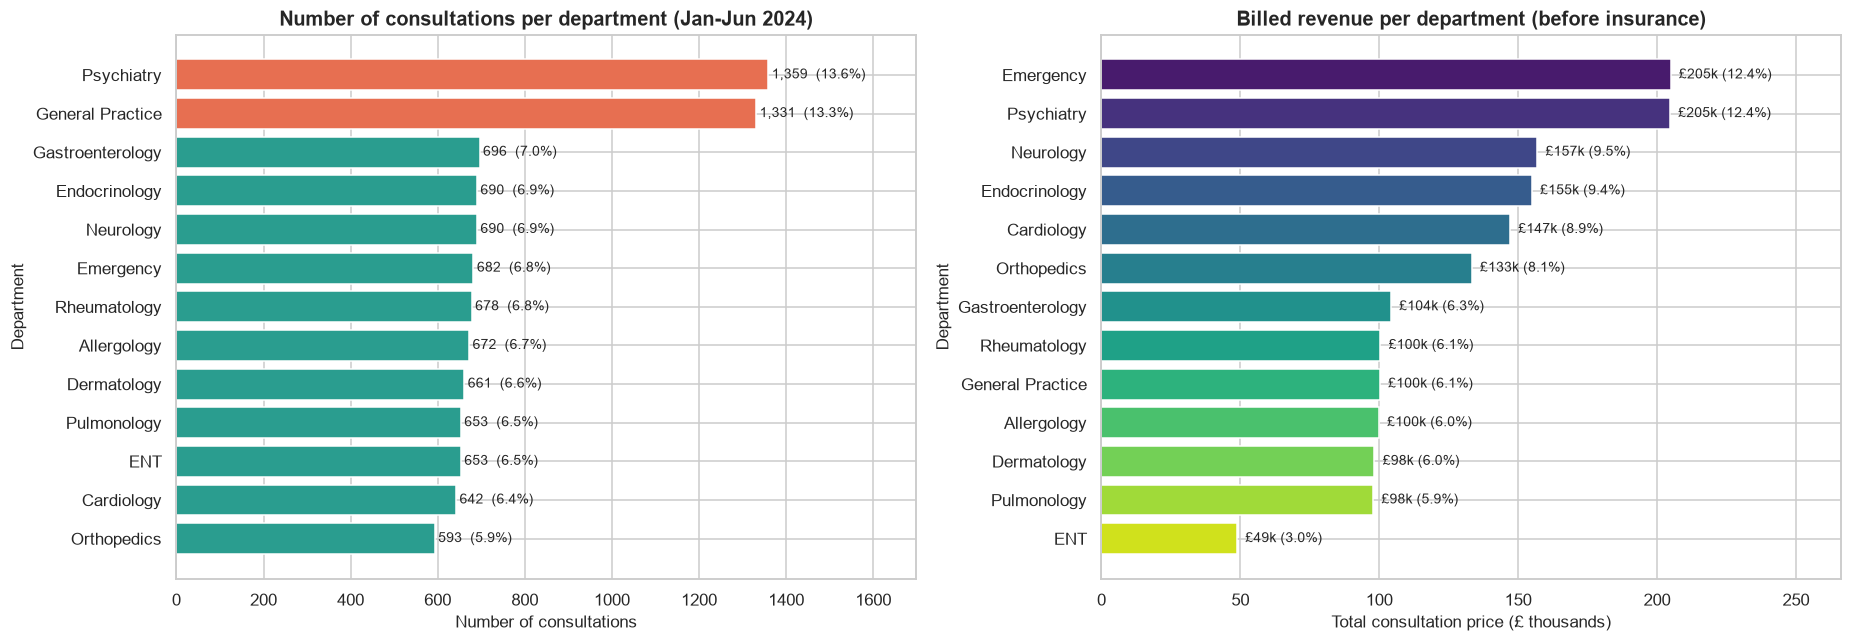

Top-2 departments (Psychiatry, General Practice) = 26.9% of consultations; the other 11 average 665 visits each (range 593-696)
Average price per visit: Emergency £300, Psychiatry £151, General Practice £75, ENT £75


In [44]:
dv = clean["Department"].value_counts()
rev = clean.groupby("Department")[price].sum().reindex(DEPT_ORDER)
fig, ax = plt.subplots(1, 2, figsize=(17, 6))

colors = ["#e76f51" if d in dv.index[:2] else "#2a9d8f" for d in DEPT_ORDER]
ax[0].barh(DEPT_ORDER, dv.reindex(DEPT_ORDER).values, color=colors, edgecolor="white")
ax[0].invert_yaxis()
for i, v in enumerate(dv.reindex(DEPT_ORDER).values):
    ax[0].text(v + 8, i, f"{v:,}  ({v/len(clean):.1%})", va="center", fontsize=9)
ax[0].set_xlim(0, dv.max() * 1.25)
ax[0].set_title("Number of consultations per department (Jan-Jun 2024)")
ax[0].set_xlabel("Number of consultations"); ax[0].set_ylabel("Department")

rev_order = rev.sort_values(ascending=False)
ax[1].barh(rev_order.index, rev_order.values / 1000, color=sns.color_palette("viridis", len(rev_order)), edgecolor="white")
ax[1].invert_yaxis()
for i, v in enumerate(rev_order.values):
    ax[1].text(v / 1000 + 3, i, f"£{v/1000:,.0f}k ({v/rev.sum():.1%})", va="center", fontsize=9)
ax[1].set_xlim(0, rev_order.max() / 1000 * 1.3)
ax[1].set_title("Billed revenue per department (before insurance)")
ax[1].set_xlabel("Total consultation price (£ thousands)"); ax[1].set_ylabel("Department")
plt.tight_layout(); plt.show()

print(f"Top-2 departments ({dv.index[0]}, {dv.index[1]}) = {dv.iloc[:2].sum()/len(clean):.1%} of consultations; the other 11 average {dv.iloc[2:].mean():.0f} visits each (range {dv.iloc[2:].min()}-{dv.iloc[2:].max()})")
print(f"Average price per visit: " + ", ".join(f"{d} £{clean.loc[clean['Department']==d, price].mean():.0f}" for d in ['Emergency', 'Psychiatry', 'General Practice', 'ENT']))

**Interpretation.** **Psychiatry (1,359 visits) and General Practice (1,331) together account for 26.9 % of all consultations** and are about twice as busy as every other department; the remaining 11 are strikingly uniform (593-696 visits each). Revenue tells a different story because prices come in tiers: Emergency (£300 per visit) generates as much billing as Psychiatry (12.4 % each) with half the visits, while ENT and General Practice charge only ≈ £75, so ENT is the smallest revenue line (3.0 %). Busy ≠ valuable: General Practice is #2 in visits but only #9 in revenue.

### <font color='turquoise'>3.2.2 Consultations Over Time</font> <a class="anchor" id="3_2_2"></a>

Months have different lengths (February 2024 has 29 days), so raw monthly counts would mislead; we compare **visits per day**. The right panel shows each department's month relative to its own six-month average (100 = normal).

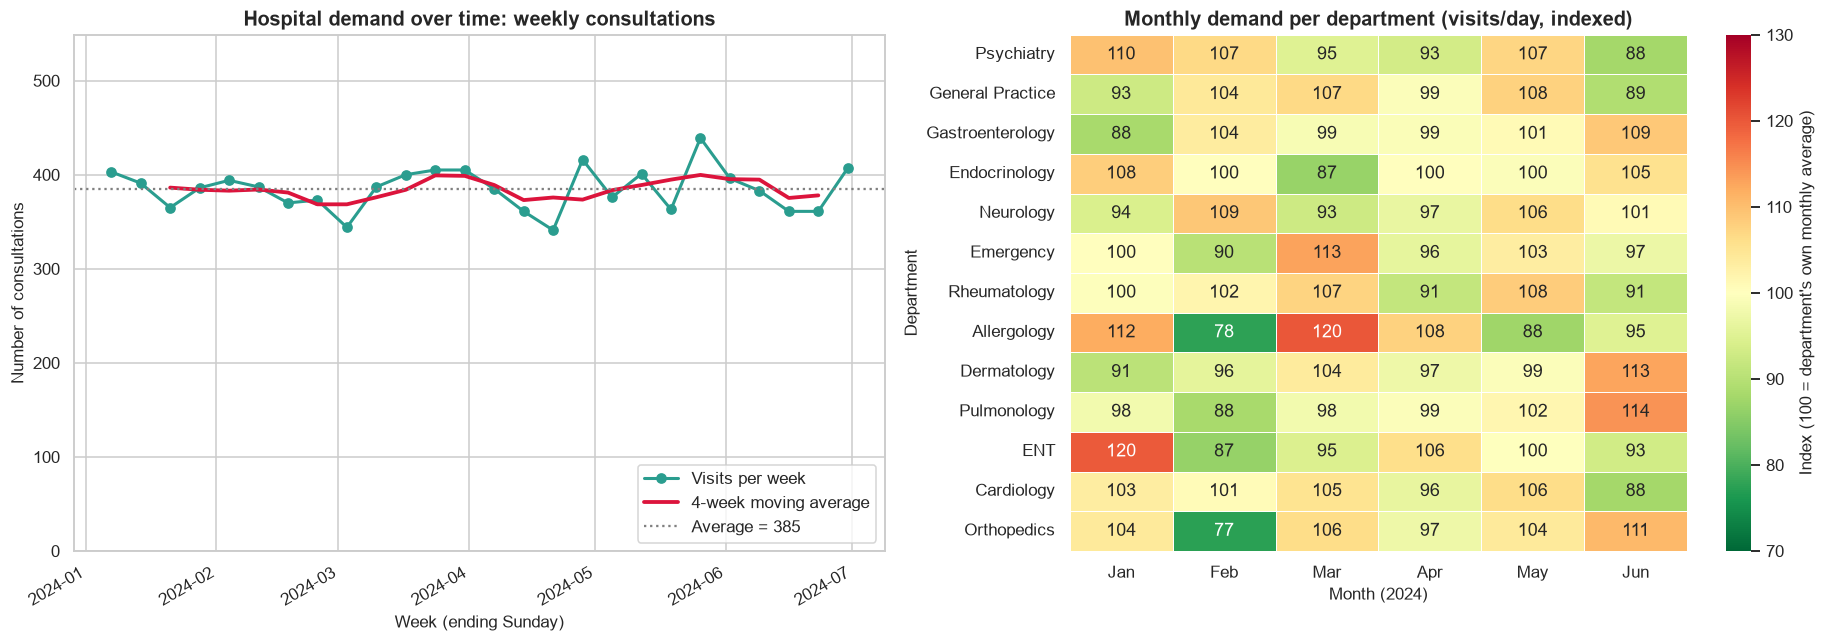

Visits per day by month: {'Jan': 55.7, 'Feb': 53.3, 'Mar': 56.0, 'Apr': 53.9, 'May': 56.6, 'Jun': 53.9}
Jan->Jun change in visits/day: -3.4% | weekly visits: mean 385, min 341, max 439 (CV = 5.9%)
Largest single department-month deviation from its own average: 23 index points


In [45]:
days_in_month = pd.Series({1: 31, 2: 29, 3: 31, 4: 30, 5: 31, 6: 30})
fig, ax = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1.05, 1]})

wk = clean.set_index("Visit Date").resample("W-SUN").size()                    # 26 full Monday-Sunday weeks
ax[0].plot(wk.index, wk.values, marker="o", color="#2a9d8f", lw=2, label="Visits per week")
ax[0].plot(wk.index, wk.rolling(4, center=True).mean(), color="crimson", lw=2.5, label="4-week moving average")
ax[0].axhline(wk.mean(), color="grey", ls=":", label=f"Average = {wk.mean():.0f}")
ax[0].set_ylim(0, wk.max() * 1.25)
ax[0].set_title("Hospital demand over time: weekly consultations")
ax[0].set_xlabel("Week (ending Sunday)"); ax[0].set_ylabel("Number of consultations"); ax[0].legend(loc="lower right")
plt.setp(ax[0].get_xticklabels(), rotation=30, ha="right")

dm = pd.crosstab(clean["Department"], clean["Visit Date"].dt.month)
idx = (dm.div(days_in_month, axis=1)).div((dm.div(days_in_month, axis=1)).mean(axis=1), axis=0) * 100
idx.columns = [month_names[m] for m in idx.columns]
sns.heatmap(idx.loc[DEPT_ORDER], annot=True, fmt=".0f", cmap="RdYlGn_r", center=100, vmin=70, vmax=130, linewidths=.5,
            cbar_kws={"label": "Index (100 = department's own monthly average)"}, ax=ax[1])
ax[1].set_title("Monthly demand per department (visits/day, indexed)")
ax[1].set_xlabel("Month (2024)"); ax[1].set_ylabel("Department")
plt.tight_layout(); plt.show()

mpd = clean.groupby(clean["Visit Date"].dt.month).size() / days_in_month
print("Visits per day by month:", {month_names[m]: round(v, 1) for m, v in mpd.items()})
print(f"Jan->Jun change in visits/day: {mpd[6]/mpd[1]-1:+.1%} | weekly visits: mean {wk.mean():.0f}, min {wk.min()}, max {wk.max()} (CV = {wk.std()/wk.mean():.1%})")
print(f"Largest single department-month deviation from its own average: {abs(idx - 100).max().max():.0f} index points")

**Interpretation.** Demand is **stable, with no growth or seasonality**: between 53 and 57 visits per day in every month (January to June −3.4 %), and weekly volume fluctuates only ±6 % around 385 visits (range 341-439). The apparent dip in February disappears once we divide by the number of days (29), so it is a calendar effect. In the heatmap even the most extreme department-month is only 23 index points from the department's own average, which is what ordinary random variation produces for ~100 visits per cell. Capacity planning can therefore assume flat demand and focus on department structure rather than seasonal peaks.

### <font color='turquoise'>3.2.3 Department Usage by Gender and Age Group</font> <a class="anchor" id="3_2_3"></a>

Two complementary views: the **share of each department's visits by gender** (a perfectly neutral department would be ≈ 1/3 each) and the **lift by age group** (share of the department's visits that come from an age group ÷ that age group's share of all visits; 1.0 = no preference, > 1 over-represented).

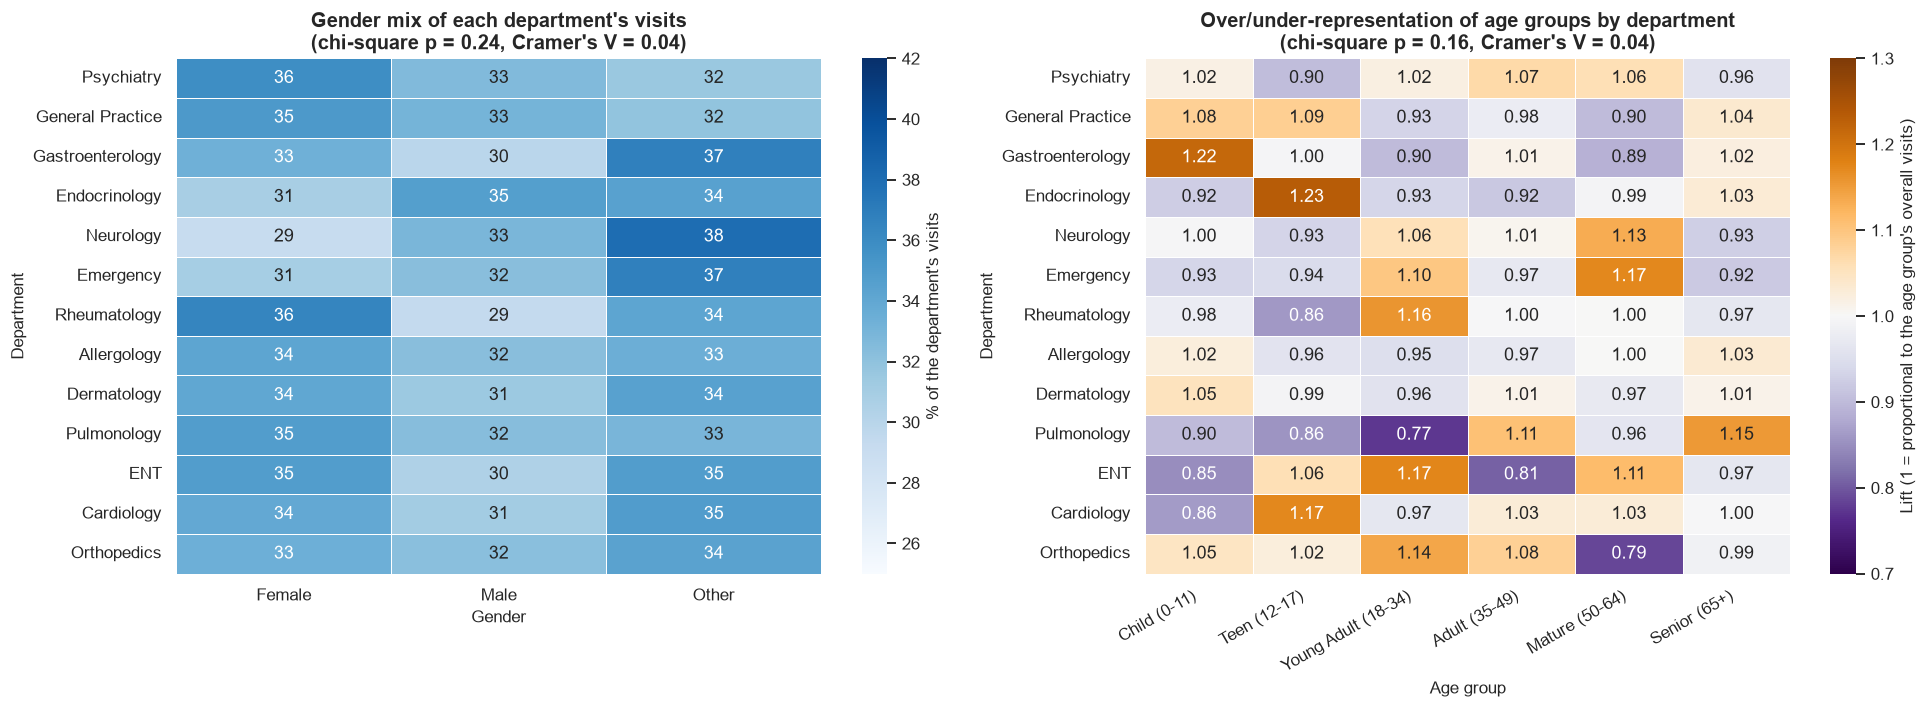

Strongest over-representations: [('ENT / Young Adult (18-34)', 1.17), ('Gastroenterology / Child (0-11)', 1.22), ('Endocrinology / Teen (12-17)', 1.23)]
Strongest under-representations: [('Pulmonology / Young Adult (18-34)', 0.77), ('Orthopedics / Mature (50-64)', 0.79), ('ENT / Adult (35-49)', 0.81)]
Share of department x age cells with lift outside 0.85-1.15: 14%
If age had NO relation to department, the most extreme lift would still reach about 1.31 (median of 300 shuffles) -> observed max lift is 1.29


In [46]:
fig, ax = plt.subplots(1, 2, figsize=(18, 6.6))

ct_g = pd.crosstab(vis["Department"], vis["Gender"]).loc[DEPT_ORDER]
share_g = ct_g.div(ct_g.sum(axis=1), axis=0) * 100
chi_g, p_g, v_g = chi2_test(ct_g)
sns.heatmap(share_g[["Female", "Male", "Other"]], annot=True, fmt=".0f", cmap="Blues", vmin=25, vmax=42, linewidths=.5,
            cbar_kws={"label": "% of the department's visits"}, ax=ax[0])
ax[0].set_title(f"Gender mix of each department's visits\n(chi-square p = {p_g:.2f}, Cramer's V = {v_g:.2f})")
ax[0].set_xlabel("Gender"); ax[0].set_ylabel("Department")

ct_a = pd.crosstab(vis["Department"], vis["Age_Group"]).loc[DEPT_ORDER, AGE_ORDER]
lift = ct_a.div(ct_a.sum(axis=1), axis=0).div(ct_a.sum(axis=0) / ct_a.values.sum(), axis=1)
chi_a, p_a, v_a = chi2_test(ct_a)
sns.heatmap(lift, annot=True, fmt=".2f", cmap="PuOr_r", center=1, vmin=0.7, vmax=1.3, linewidths=.5,
            cbar_kws={"label": "Lift (1 = proportional to the age group's overall visits)"}, ax=ax[1])
ax[1].set_title(f"Over/under-representation of age groups by department\n(chi-square p = {p_a:.2f}, Cramer's V = {v_a:.2f})")
ax[1].set_xlabel("Age group"); ax[1].set_ylabel("Department")
plt.setp(ax[1].get_xticklabels(), rotation=30, ha="right")
plt.tight_layout(); plt.show()

stack = lift.stack().sort_values()
print("Strongest over-representations:", [(f"{d} / {a}", round(v, 2)) for (d, a), v in stack.tail(3).items()])
print("Strongest under-representations:", [(f"{d} / {a}", round(v, 2)) for (d, a), v in stack.head(3).items()])
print(f"Share of department x age cells with lift outside 0.85-1.15: {((lift < 0.85) | (lift > 1.15)).values.mean():.0%}")
# what the lift range looks like when nothing is going on: shuffle age groups across patients 500 times
rng = np.random.default_rng(42); mx = []
pat_ag = ABT.set_index(pid)["Age_Group"]
for _ in range(300):
    shuf = pd.Series(rng.permutation(pat_ag.values), index=pat_ag.index)
    t = pd.crosstab(clean["Department"], clean[pid].map(shuf)).reindex(index=DEPT_ORDER, columns=AGE_ORDER)
    l_ = t.div(t.sum(axis=1), axis=0).div(t.sum(axis=0) / t.values.sum(), axis=1)
    mx.append(max(l_.max().max(), 1 / l_.min().min()))
print(f"If age had NO relation to department, the most extreme lift would still reach about {np.percentile(mx, 50):.2f} (median of 300 shuffles) -> observed max lift is {max(lift.max().max(), 1/lift.min().min()):.2f}")

**Interpretation.** Neither gender (p = 0.24) nor age group (p = 0.16) is significantly related to department choice, and both Cramér's V values are tiny. Some cells look striking (Endocrinology for teenagers lift 1.23, Gastroenterology for young children 1.22, Pulmonology under-used by young adults 0.77), but the shuffle experiment shows that if age were completely unrelated to department we would *still* expect a most-extreme lift of about 1.3 - we observe 1.29. These are therefore noise, not patterns, and we deliberately avoid presenting them as findings. The honest answer to "which groups use which departments?" is: **all groups use the hospital in the same proportions**, with Psychiatry and General Practice leading everywhere.

## <font color='turquoise'>3.3 Patient Satisfaction</font> <a class="anchor" id="3_3"></a>

All satisfaction results use **valid ratings only** (1-5). Remember that ~36 % of ENT and General Practice ratings were invalid (value 6) and are excluded, so those two departments rest on fewer ratings and the intervals below are wider.

### <font color='turquoise'>3.3.1 Satisfaction by Department</font> <a class="anchor" id="3_3_1"></a>

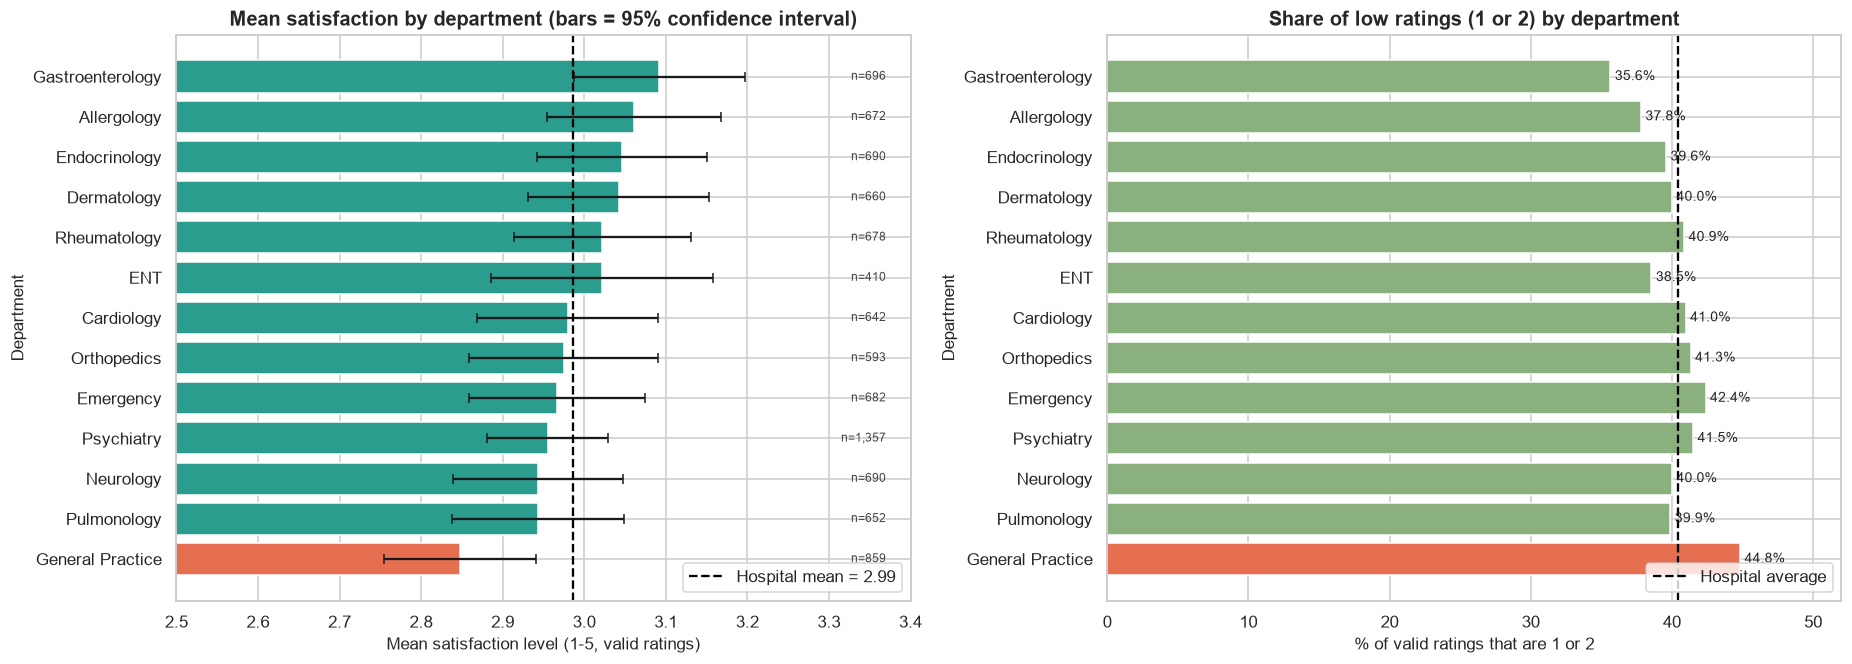

Do departments differ in satisfaction? Kruskal-Wallis H = 19.2, p = 0.084
Lowest: General Practice (2.85) vs all other departments (3.00): Mann-Whitney p = 0.003
Spread between best and worst department: 0.24 rating points (hospital-wide std of a single rating = 1.41)


In [47]:
sd = clean.groupby("Department")[sat].agg(["mean", "count", "std"])
sd["ci95"] = stats.t.ppf(.975, sd["count"] - 1) * sd["std"] / np.sqrt(sd["count"])
sd["low_share"] = clean.groupby("Department")[sat].apply(lambda s: (s.dropna() <= 2).mean()) * 100
sd = sd.sort_values("mean")

fig, ax = plt.subplots(1, 2, figsize=(17, 6.2))
cols = ["#e76f51" if i == 0 else "#2a9d8f" for i in range(len(sd))]
ax[0].barh(sd.index, sd["mean"], xerr=sd["ci95"], color=cols, edgecolor="white", capsize=3)
ax[0].axvline(MEAN_SAT, color="black", ls="--", lw=1.5, label=f"Hospital mean = {MEAN_SAT:.2f}")
ax[0].set_xlim(2.5, 3.4)
for i, (d, r) in enumerate(sd.iterrows()):
    ax[0].text(3.37, i, f"n={int(r['count']):,}", va="center", ha="right", fontsize=8, color="#444")
ax[0].set_title("Mean satisfaction by department (bars = 95% confidence interval)")
ax[0].set_xlabel("Mean satisfaction level (1-5, valid ratings)"); ax[0].set_ylabel("Department"); ax[0].legend(loc="lower right")

sl = sd["low_share"]
ax[1].barh(sl.index, sl.values, color=["#e76f51" if v == sl.max() else "#8ab17d" for v in sl.values], edgecolor="white")
ax[1].bar_label(ax[1].containers[0], fmt="%.1f%%", padding=3, fontsize=9)
ax[1].axvline(clean[sat].dropna().le(2).mean() * 100, color="black", ls="--", lw=1.5, label="Hospital average")
ax[1].set_xlim(0, 52)
ax[1].set_title("Share of low ratings (1 or 2) by department")
ax[1].set_xlabel("% of valid ratings that are 1 or 2"); ax[1].set_ylabel("Department"); ax[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

kw = stats.kruskal(*[g_.dropna().values for _, g_ in clean.groupby("Department")[sat]])
worst = sd.index[0]
mw = stats.mannwhitneyu(clean.loc[clean["Department"] == worst, sat].dropna(), clean.loc[clean["Department"] != worst, sat].dropna())
print(f"Do departments differ in satisfaction? Kruskal-Wallis H = {kw.statistic:.1f}, p = {kw.pvalue:.3f}")
print(f"Lowest: {worst} ({sd['mean'].iloc[0]:.2f}) vs all other departments ({clean.loc[clean['Department'] != worst, sat].mean():.2f}): Mann-Whitney p = {mw.pvalue:.3f}")
print(f"Spread between best and worst department: {sd['mean'].max() - sd['mean'].min():.2f} rating points (hospital-wide std of a single rating = {clean[sat].std():.2f})")

**Interpretation.** Average satisfaction is ≈ 3.0 out of 5 in every department and the spread between best (Gastroenterology 3.09) and worst (General Practice 2.85) is only 0.24 points, versus a single-rating standard deviation of 1.41; overall the departments are **not significantly different** (Kruskal-Wallis p = 0.08). **General Practice is the exception to watch**: it is the lowest on both mean and share of low ratings (45 % vs 36-42 % elsewhere) and is significantly below the rest of the hospital (Mann-Whitney p = 0.003, which only just survives a 13-department multiple-testing correction of 0.0038). Two caveats: (1) General Practice is also the second-busiest department, so a modest dissatisfaction there affects many patients; (2) 36 % of its ratings were invalid and discarded, so if those missing ratings were not random the true gap could be different.

### <font color='turquoise'>3.3.2 Satisfaction by Patient Segment</font> <a class="anchor" id="3_3_2"></a>

Patient-level view: each point is the mean of the patients' average rating in the segment, with a 95 % confidence interval. We test **all** segmentation variables and apply a Bonferroni correction (testing 8 variables at 5 % each would produce a "significant" result by chance about one time in three).

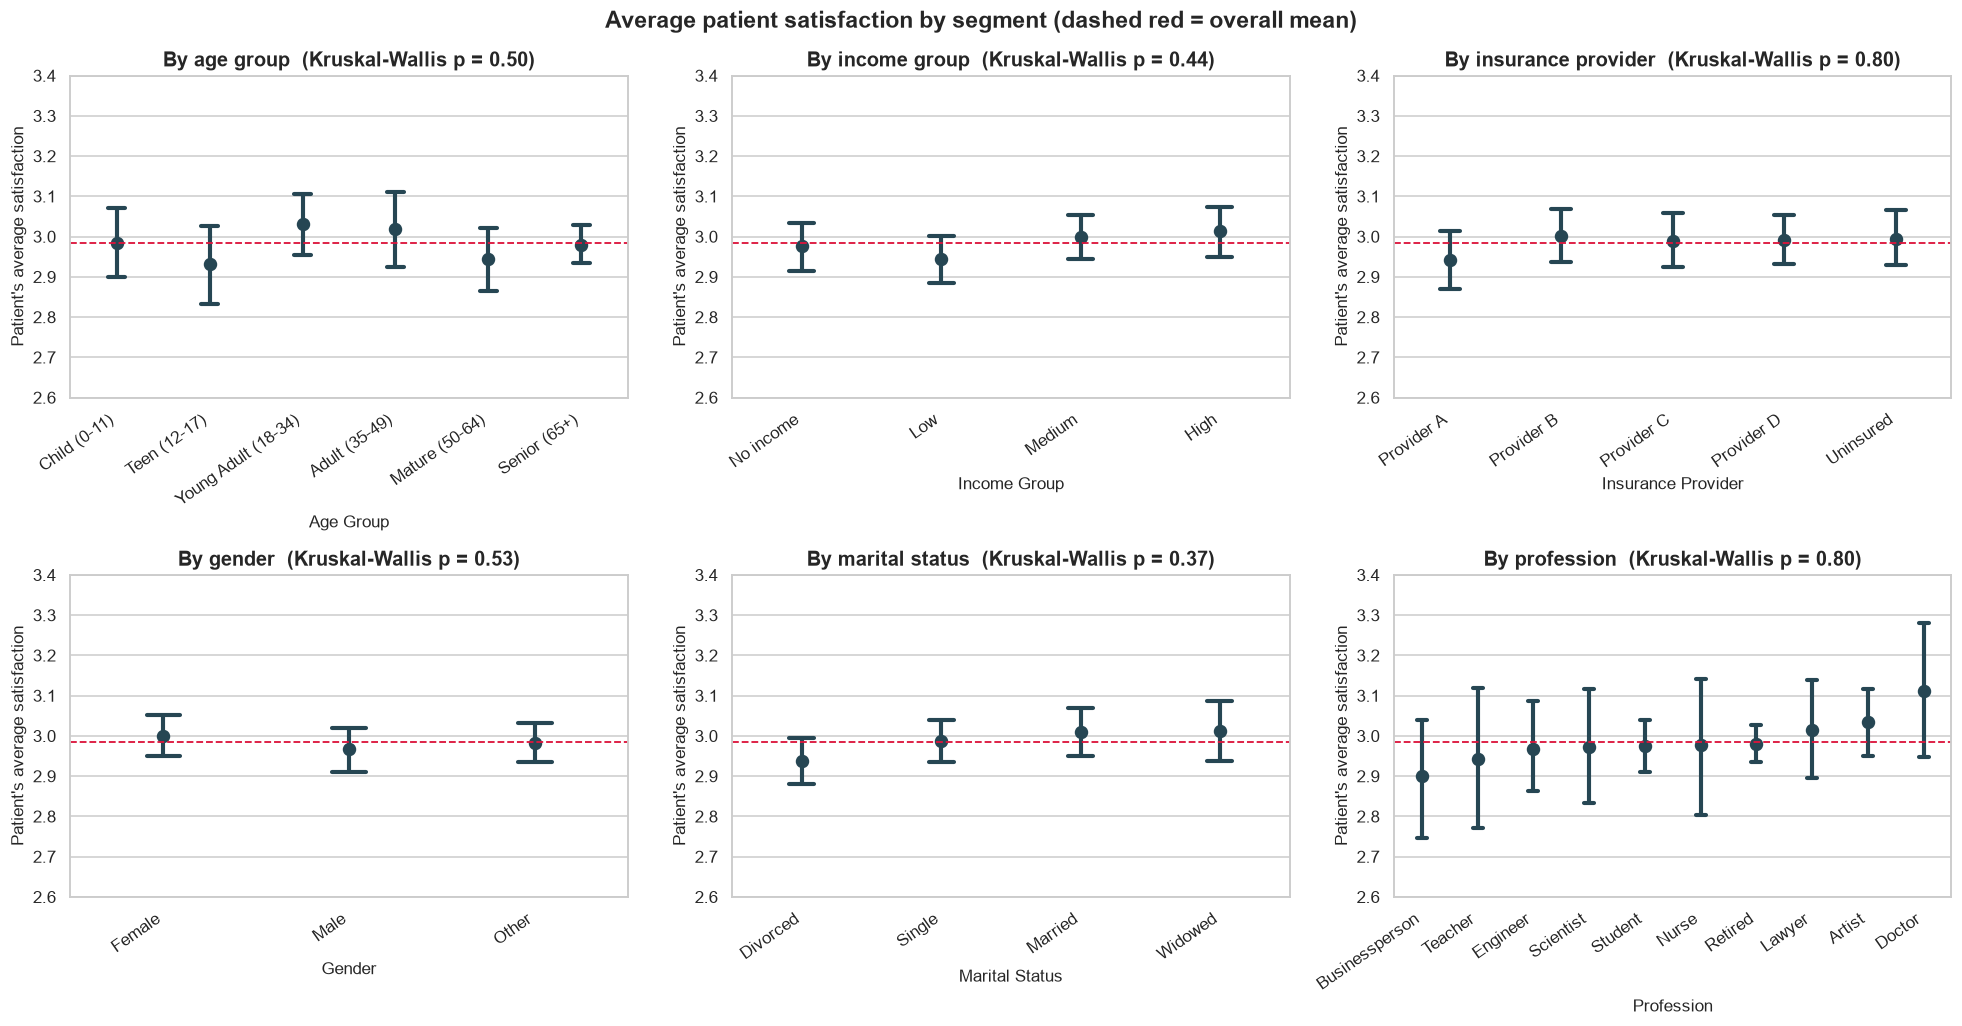

,Kruskal-Wallis p,Best group,Worst group,Gap,Significant after Bonferroni (a = 0.05/8)
Segment variable,,,,,
Age_Group,0.501,Young Adult (18-34) (3.03),Teen (12-17) (2.93),0.099,False
Income_Group,0.440,High (3.01),Low (2.94),0.069,False
Insurance_Provider,0.800,Provider B (3.00),Provider A (2.94),0.059,False
Gender,0.528,Female (3.00),Male (2.97),0.031,False
Marital_Status,0.372,Widowed (3.01),Divorced (2.94),0.074,False
Profession,0.803,Doctor (3.11),Businessperson (2.90),0.210,False
City,0.909,Manchester (3.02),Liverpool (2.95),0.069,False
Family_History,0.049,Diabetes (3.05),Hypertension (2.94),0.116,False


In [48]:
seg_specs = [("Age_Group", AGE_ORDER), ("Income_Group", INC_ORDER), ("Insurance_Provider", PROV_ORDER),
             ("Gender", ["Female", "Male", "Other"]), ("Marital_Status", None), ("Profession", None)]
fig, axes = plt.subplots(2, 3, figsize=(18, 9.5))
for ax, (col, order) in zip(axes.ravel(), seg_specs):
    order = order or ABT.groupby(col)["Avg_Satisfaction"].mean().sort_values().index.tolist()
    sns.pointplot(data=ABT, x=col, y="Avg_Satisfaction", order=order, errorbar=("ci", 95), capsize=.18,
                  color="#264653", linestyle="none", ax=ax)
    ax.axhline(ABT["Avg_Satisfaction"].mean(), color="crimson", ls="--", lw=1.2)
    p_ = stats.kruskal(*[g_["Avg_Satisfaction"].values for _, g_ in ABT.groupby(col)]).pvalue
    ax.set_ylim(2.6, 3.4)
    ax.set_title(f"By {col.replace('_', ' ').lower()}  (Kruskal-Wallis p = {p_:.2f})")
    ax.set_xlabel(col.replace("_", " ")); ax.set_ylabel("Patient's average satisfaction")
    plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
fig.suptitle("Average patient satisfaction by segment (dashed red = overall mean)", fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

rows = []
for col in ["Age_Group", "Income_Group", "Insurance_Provider", "Gender", "Marital_Status", "Profession", "City", "Family_History"]:
    grp = [g_["Avg_Satisfaction"].values for _, g_ in ABT.groupby(col)]
    means = ABT.groupby(col)["Avg_Satisfaction"].mean()
    rows.append({"Segment variable": col, "Kruskal-Wallis p": stats.kruskal(*grp).pvalue,
                 "Best group": f"{means.idxmax()} ({means.max():.2f})", "Worst group": f"{means.idxmin()} ({means.min():.2f})",
                 "Gap": means.max() - means.min()})
seg_tests = pd.DataFrame(rows).set_index("Segment variable").round(3)
seg_tests["Significant after Bonferroni (a = 0.05/8)"] = seg_tests["Kruskal-Wallis p"] < 0.05 / 8
display(seg_tests)

**Interpretation.** No patient segment stands out: every confidence interval overlaps the hospital average and the p-values range from 0.37 to 0.91 for age, income, insurance, gender, marital status, profession and city. The only borderline result is family history (p = 0.049), which fails the Bonferroni threshold (0.05/8 = 0.006) and should be treated as chance. So the answer to "which patient groups are least satisfied?" is **none in a statistically defensible way**; apparent gaps (e.g. Doctors 3.11 vs Businesspeople 2.90) rest on only 20-22 patients each and disappear in the noise.

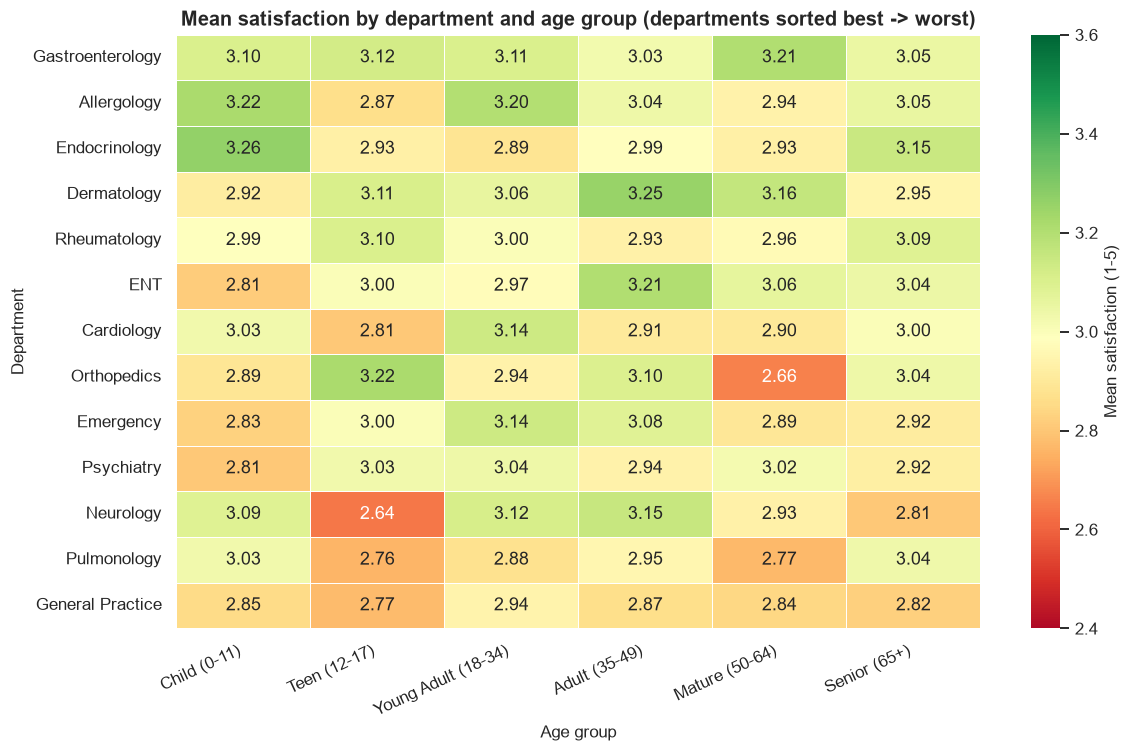

Ratings per cell: min 35, median 101  ->  a single cell has a standard error of about ±0.14 points
Three lowest cells: [('Neurology / Teen (12-17)', 2.64), ('Orthopedics / Mature (50-64)', 2.66), ('Pulmonology / Teen (12-17)', 2.76)]


In [49]:
# Department x age group: where could dissatisfaction concentrate?  (visit level, cells have ~100 ratings each)
hm = vis.pivot_table(index="Department", columns="Age_Group", values=sat, aggfunc="mean").loc[sd.index[::-1], AGE_ORDER]
cnt = vis.pivot_table(index="Department", columns="Age_Group", values=sat, aggfunc="count")
fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(hm, annot=True, fmt=".2f", cmap="RdYlGn", center=MEAN_SAT, vmin=2.4, vmax=3.6, linewidths=.5,
            cbar_kws={"label": "Mean satisfaction (1-5)"}, ax=ax)
ax.set_title("Mean satisfaction by department and age group (departments sorted best -> worst)")
ax.set_xlabel("Age group"); ax.set_ylabel("Department")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
plt.tight_layout(); plt.show()

print(f"Ratings per cell: min {int(cnt.min().min())}, median {int(cnt.stack().median())}  ->  a single cell has a standard error of about ±{clean[sat].std()/np.sqrt(cnt.stack().median()):.2f} points")
low_cells = hm.stack().sort_values().head(3)
print("Three lowest cells:", [(f"{d} / {a}", round(v, 2)) for (d, a), v in low_cells.items()])

**Interpretation.** The three lowest cells (Neurology/Teens 2.64, Orthopedics/Mature 2.66, Pulmonology/Teens 2.76) look worrying but each rests on about 100 ratings (some on only 35), giving a standard error of ±0.14: with 78 cells in the table, a few cells ≈ 2 standard errors below average are expected by chance. The map confirms the department finding (General Practice is red across most age groups, a consistent, rather than isolated, signal) and shows no age-specific problem. Any follow-up on dissatisfaction should be done at department level (General Practice), not at department × age level.

## <font color='turquoise'>3.4 Additional Visualizations</font> <a class="anchor" id="3_4"></a>

These plots answer the remaining management question (*how much do insurers cover and how much do patients pay?*) and support the recommendations for the next team: patient value concentration, correlations between features, a segmentation preview and engagement/recency.

### Insurance coverage and out-of-pocket spending

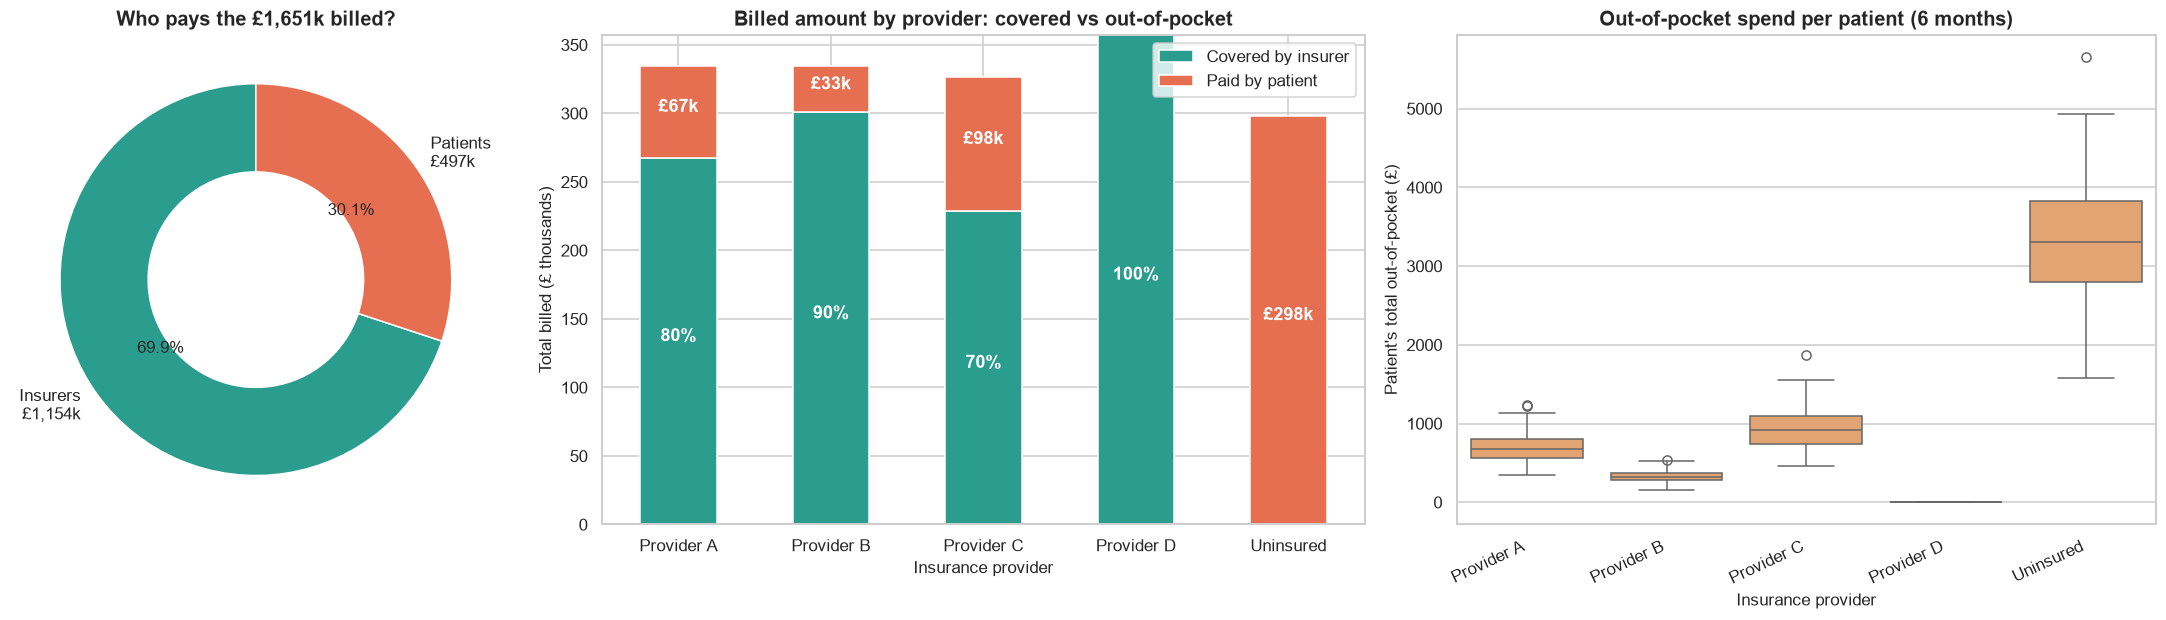

Insurers cover 69.9% of the billed amount; patients pay 30.1% (£496,678).
Uninsured: 90 patients (18%) pay £298,362 = 60% of ALL out-of-pocket money; avg £3,315 per patient vs £484 for insured.
                    Patients     Spent   Covered       OOP  Covered %
Insurance_Provider                                                   
Provider A                97  334514.9  267612.0   66903.0       80.0
Provider B               102  334293.0  300863.7   33429.3       90.0
Provider C               106  326612.6  228628.8   97983.8       70.0
Provider D               105  357355.1  357355.1       0.0      100.0
Uninsured                 90  298361.5       0.0  298361.5        0.0


In [50]:
tot_price, tot_cov = clean[price].sum(), clean[cov].sum()
tot_oop = tot_price - tot_cov
prov = ABT.groupby("Insurance_Provider").agg(Patients=("Insured", "size"), Spent=("Total_Spent", "sum"),
                                              Covered=("Total_Insurance_Coverage", "sum"), OOP=("Total_Out_of_Pocket", "sum")).reindex(PROV_ORDER)
prov["Covered %"] = prov["Covered"] / prov["Spent"] * 100

fig, ax = plt.subplots(1, 3, figsize=(20, 5.8), gridspec_kw={"width_ratios": [0.8, 1.2, 1.1]})
ax[0].pie([tot_cov, tot_oop], labels=[f"Insurers\n£{tot_cov/1000:,.0f}k", f"Patients\n£{tot_oop/1000:,.0f}k"], colors=["#2a9d8f", "#e76f51"],
          autopct="%1.1f%%", startangle=90, wedgeprops=dict(width=0.45, edgecolor="white"), textprops={"fontsize": 11})
ax[0].set_title("Who pays the £{:,.0f}k billed?".format(tot_price / 1000))

pp = prov[["Covered", "OOP"]] / 1000
pp.plot(kind="bar", stacked=True, ax=ax[1], color=["#2a9d8f", "#e76f51"], edgecolor="white", rot=0)
for i, (c_, o_) in enumerate(zip(pp["Covered"], pp["OOP"])):
    if c_ > 15: ax[1].text(i, c_ / 2, f"{prov['Covered %'].iloc[i]:.0f}%", ha="center", color="white", fontweight="bold")
    if o_ > 15: ax[1].text(i, c_ + o_ / 2, f"£{o_:,.0f}k", ha="center", color="white", fontweight="bold")
ax[1].set_title("Billed amount by provider: covered vs out-of-pocket")
ax[1].set_xlabel("Insurance provider"); ax[1].set_ylabel("Total billed (£ thousands)"); ax[1].legend(["Covered by insurer", "Paid by patient"])

oop_pat = ABT["Total_Out_of_Pocket"]
bp = ABT.assign(Provider=pd.Categorical(ABT["Insurance_Provider"], PROV_ORDER))
sns.boxplot(data=bp, x="Provider", y="Total_Out_of_Pocket", color="#f4a261", ax=ax[2], order=PROV_ORDER)
ax[2].set_title("Out-of-pocket spend per patient (6 months)")
ax[2].set_xlabel("Insurance provider"); ax[2].set_ylabel("Patient's total out-of-pocket (£)")
plt.setp(ax[2].get_xticklabels(), rotation=25, ha="right")
plt.tight_layout(); plt.show()

unins = ABT[ABT["Insured"] == 0]
print(f"Insurers cover {tot_cov/tot_price:.1%} of the billed amount; patients pay {tot_oop/tot_price:.1%} (£{tot_oop:,.0f}).")
print(f"Uninsured: {len(unins)} patients ({len(unins)/N_PAT:.0%}) pay £{unins['Total_Out_of_Pocket'].sum():,.0f} = {unins['Total_Out_of_Pocket'].sum()/ABT['Total_Out_of_Pocket'].sum():.0%} of ALL out-of-pocket money; avg £{unins['Total_Out_of_Pocket'].mean():,.0f} per patient vs £{ABT.loc[ABT['Insured']==1, 'Total_Out_of_Pocket'].mean():,.0f} for insured.")
print(prov.round(1).to_string())

**Interpretation.** Of the £1.65 million billed, **insurers pay 69.9 % and patients pay 30.1 % (£497k)**. Coverage follows a fixed rule per provider (D 100 %, B 90 %, A 80 %, C 70 %), so Provider D patients pay nothing, while Provider C patients pay 30 %. The striking finding is the **uninsured group: 90 patients (18 %) pay £298k, 60 % of all out-of-pocket money**, an average of £3,315 each in six months versus £484 for insured patients. Self-pay patients are the clearest financial-vulnerability and potential bad-debt segment in the hospital, and the group where an insurance-enrolment or payment-plan initiative would have the greatest impact.

### Patient value: spend vs frequency and concentration

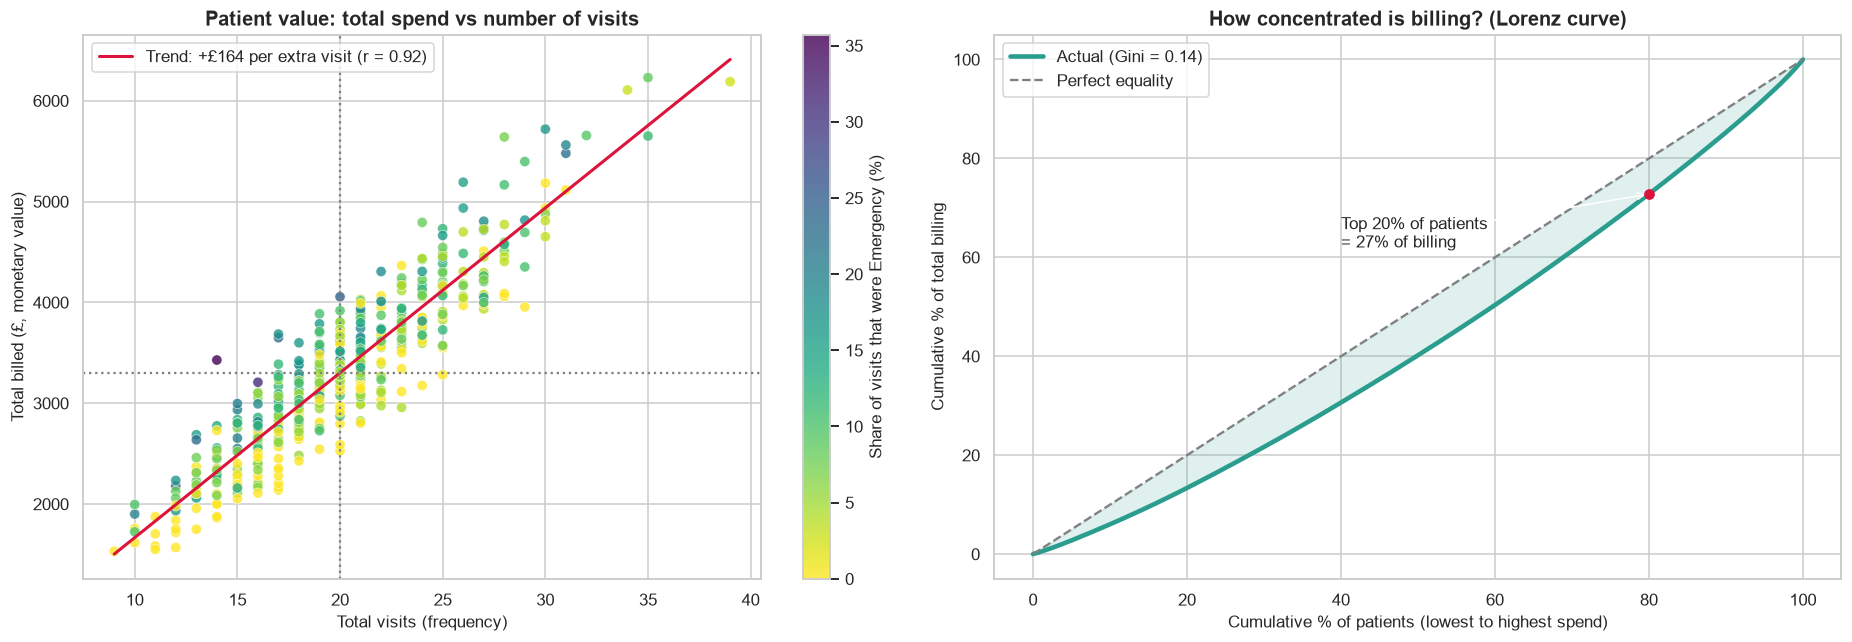

Visits explain 85% of the variance in spend; Gini = 0.14; top 20% = 27.2% of billing; bottom 50% = 40.2%.


In [51]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sc = ax[0].scatter(ABT["Total_Visits"], ABT["Total_Spent"], c=ABT["Emergency_Share"] * 100, cmap="viridis_r", s=45, alpha=.8, edgecolor="white", lw=.4)
cb = plt.colorbar(sc, ax=ax[0]); cb.set_label("Share of visits that were Emergency (%)")
m_, b_ = np.polyfit(ABT["Total_Visits"], ABT["Total_Spent"], 1)
xs = np.linspace(ABT["Total_Visits"].min(), ABT["Total_Visits"].max(), 50)
ax[0].plot(xs, m_ * xs + b_, color="crimson", lw=2, label=f"Trend: +£{m_:,.0f} per extra visit (r = {ABT['Total_Visits'].corr(ABT['Total_Spent']):.2f})")
ax[0].axvline(ABT["Total_Visits"].mean(), color="grey", ls=":"); ax[0].axhline(ABT["Total_Spent"].mean(), color="grey", ls=":")
ax[0].set_title("Patient value: total spend vs number of visits")
ax[0].set_xlabel("Total visits (frequency)"); ax[0].set_ylabel("Total billed (£, monetary value)"); ax[0].legend(loc="upper left")

vals = np.sort(ABT["Total_Spent"].to_numpy()); n = len(vals)
cum = np.concatenate([[0], np.cumsum(vals) / vals.sum()]); xs_ = np.linspace(0, 1, n + 1)
gini = (2 * np.sum(np.arange(1, n + 1) * vals) / (n * vals.sum())) - (n + 1) / n
top20 = vals[-int(.2 * n):].sum() / vals.sum()
ax[1].plot(xs_ * 100, cum * 100, color="#2a9d8f", lw=3, label=f"Actual (Gini = {gini:.2f})")
ax[1].plot([0, 100], [0, 100], color="grey", ls="--", label="Perfect equality")
ax[1].fill_between(xs_ * 100, cum * 100, xs_ * 100, color="#2a9d8f", alpha=.15)
ax[1].scatter([80], [(1 - top20) * 100], color="crimson", zorder=5)
ax[1].annotate(f"Top 20% of patients\n= {top20:.0%} of billing", xy=(80, (1 - top20) * 100), xytext=(40, 62), arrowprops=dict(arrowstyle="->"), fontsize=11)
ax[1].set_title("How concentrated is billing? (Lorenz curve)")
ax[1].set_xlabel("Cumulative % of patients (lowest to highest spend)"); ax[1].set_ylabel("Cumulative % of total billing"); ax[1].legend(loc="upper left")
plt.tight_layout(); plt.show()
print(f"Visits explain {ABT['Total_Visits'].corr(ABT['Total_Spent'])**2:.0%} of the variance in spend; Gini = {gini:.2f}; top 20% = {top20:.1%} of billing; bottom 50% = {vals[:n//2].sum()/vals.sum():.1%}.")

**Interpretation.** Spend is driven almost entirely by **how often a patient comes**: visits alone explain 85 % of the variation in billing (r = 0.92); the department mix explains most of the rest (patients with more Emergency visits sit above the trend, in the lighter colours). Billing is **not concentrated**: the Gini coefficient is only 0.14, the top 20 % of patients generate 27 % of billing and the bottom half still generates 40 %. Unlike many businesses there is no small "VIP" group to protect; revenue depends on the whole base returning regularly, so retention matters more than top-customer management.

### Correlations between ABT features

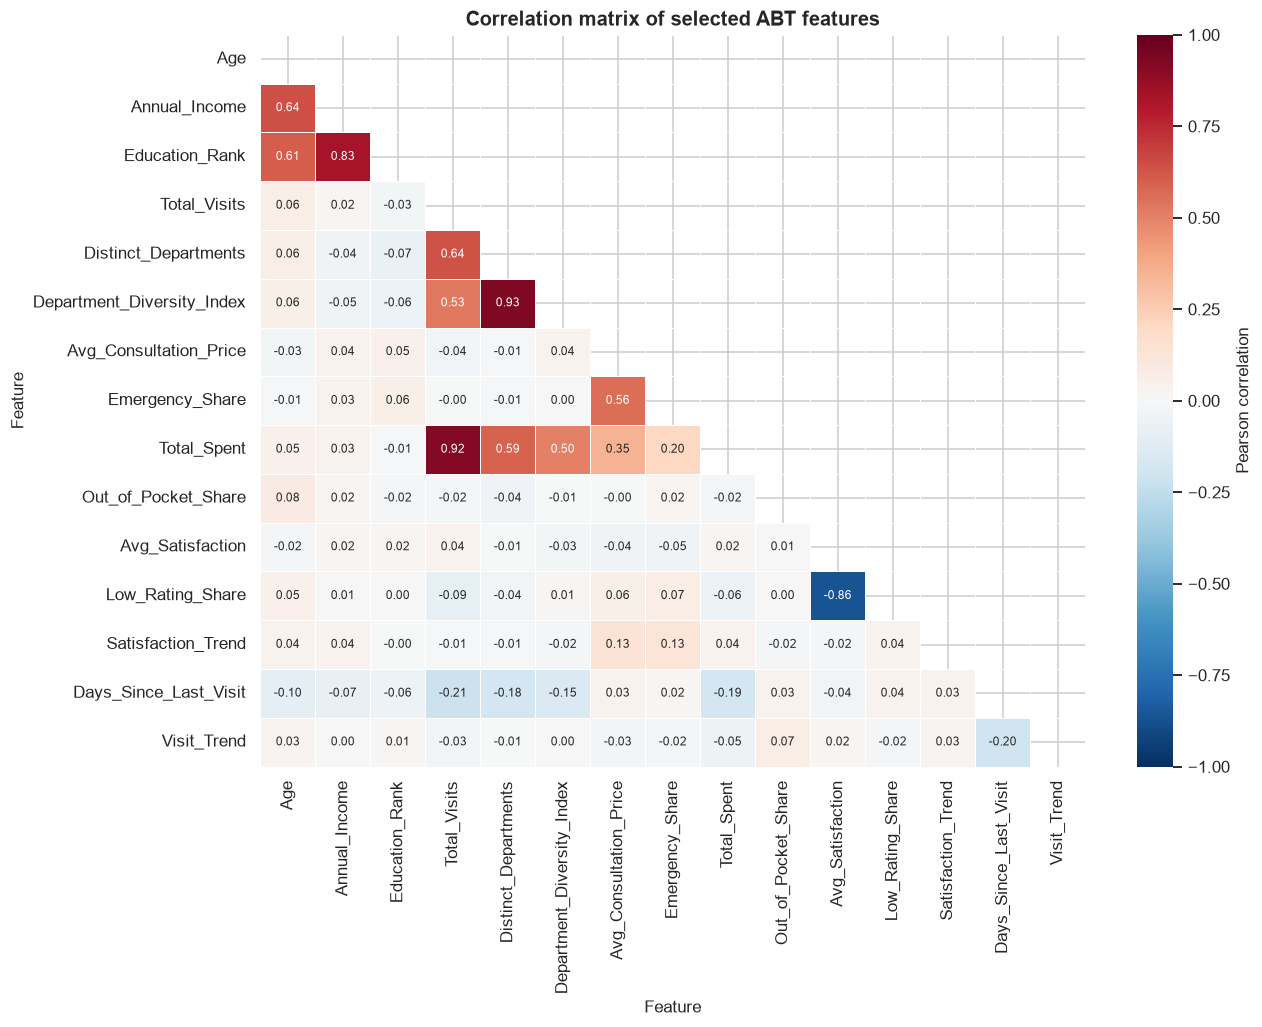

Strongest relationships:


,Feature A,Feature B,r
79,Department_Diversity_Index,Distinct_Departments,0.93
123,Total_Spent,Total_Visits,0.92
175,Low_Rating_Share,Avg_Satisfaction,-0.86
31,Education_Rank,Annual_Income,0.83
15,Annual_Income,Age,0.64
63,Distinct_Departments,Total_Visits,0.64
30,Education_Rank,Age,0.61


Satisfaction: strongest |r| with any other feature = 0.86 (Low_Rating_Share)


In [52]:
corr_cols = ["Age", "Annual_Income", "Education_Rank", "Total_Visits", "Distinct_Departments", "Department_Diversity_Index", "Avg_Consultation_Price",
             "Emergency_Share", "Total_Spent", "Out_of_Pocket_Share", "Avg_Satisfaction", "Low_Rating_Share", "Satisfaction_Trend",
             "Days_Since_Last_Visit", "Visit_Trend"]
corr = ABT[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, linewidths=.5, annot_kws={"size": 8},
            cbar_kws={"label": "Pearson correlation"}, ax=ax)
ax.set_title("Correlation matrix of selected ABT features")
ax.set_xlabel("Feature"); ax.set_ylabel("Feature")
plt.tight_layout(); plt.show()

pairs = corr.where(~mask).stack().rename("r").reset_index()
pairs["abs"] = pairs["r"].abs()
print("Strongest relationships:"); display(pairs.sort_values("abs", ascending=False).head(7)[["level_0", "level_1", "r"]].round(2).rename(columns={"level_0": "Feature A", "level_1": "Feature B"}))
sat_r = corr.loc["Avg_Satisfaction"].drop("Avg_Satisfaction").abs()
print(f"Satisfaction: strongest |r| with any other feature = {sat_r.max():.2f} ({sat_r.idxmax()})")

**Interpretation.** Several pairs are strongly correlated for mechanical reasons the next team must handle: `Department_Diversity_Index` and `Distinct_Departments` (0.93), `Total_Spent` and `Total_Visits` (0.92), `Low_Rating_Share` and `Avg_Satisfaction` (−0.86), `Annual_Income` with `Education_Rank` (0.83) and `Age` (0.64, students have no income). These are redundancy/leakage risks: keep one feature per pair when modelling. At the other extreme, **satisfaction is uncorrelated with everything that is not derived from itself** (|r| < 0.06 against age, income, visits, price, emergency use, recency...), the first sign that it will be very hard to predict.

### Segmentation preview (for the next team)

A quick K-means on standardised behavioural, financial and satisfaction features. We do **not** assume clusters exist: the silhouette score (1 = well-separated groups, 0 = no structure) tells us whether natural segments are there.

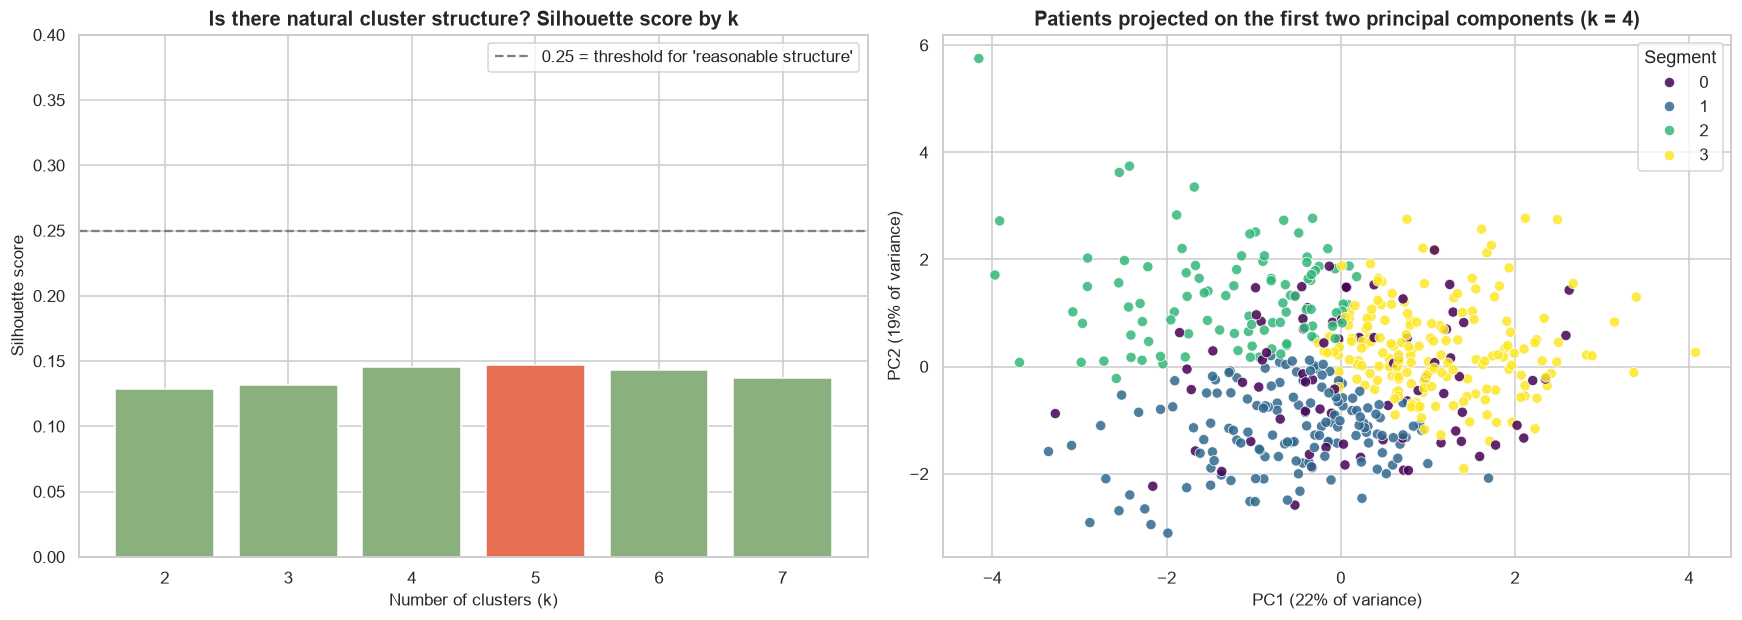

,Patients,Age,Total_Visits,Avg_Consultation_Price,Out_of_Pocket_Share,Emergency_Share,Distinct_Departments,Avg_Satisfaction,Days_Since_Last_Visit
Segment_Preview,,,,,,,,,
0,79,56.89,20.68,161.67,1.00,0.06,10.10,2.99,9.19
1,145,41.43,17.20,153.65,0.17,0.03,9.08,3.04,11.41
2,97,44.77,16.97,183.03,0.25,0.14,8.95,2.96,12.04
3,179,54.40,23.61,166.60,0.13,0.07,11.01,2.94,6.78


Silhouette scores: {2: 0.129, 3: 0.132, 4: 0.146, 5: 0.147, 6: 0.143, 7: 0.137} -> best k = 5
PCA loadings (what drives each axis):


,PC1,PC2
Age,0.15,0.01
Total_Visits,0.63,0.16
Avg_Consultation_Price,-0.17,0.68
Out_of_Pocket_Share,-0.05,-0.00
Emergency_Share,-0.15,0.69
Distinct_Departments,0.62,0.17
Avg_Satisfaction,0.06,-0.09
Days_Since_Last_Visit,-0.36,-0.05


In [53]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

seg_feats = ["Age", "Total_Visits", "Avg_Consultation_Price", "Out_of_Pocket_Share", "Emergency_Share",
             "Distinct_Departments", "Avg_Satisfaction", "Days_Since_Last_Visit"]
Xs = StandardScaler().fit_transform(ABT[seg_feats])

sil = {k: silhouette_score(Xs, KMeans(n_clusters=k, n_init=20, random_state=42).fit_predict(Xs)) for k in range(2, 8)}
best_k = max(sil, key=sil.get)
K_SHOW = 4                                                      # a business-sized number of segments for illustration
ABT["Segment_Preview"] = KMeans(n_clusters=K_SHOW, n_init=20, random_state=42).fit_predict(Xs)
pcs = PCA(n_components=2, random_state=42).fit(Xs)
Z = pcs.transform(Xs)

fig, ax = plt.subplots(1, 2, figsize=(16, 5.8))
ax[0].bar([str(k) for k in sil], list(sil.values()), color=["#e76f51" if k == best_k else "#8ab17d" for k in sil], edgecolor="white")
ax[0].axhline(0.25, color="grey", ls="--", label="0.25 = threshold for 'reasonable structure'")
ax[0].set_title("Is there natural cluster structure? Silhouette score by k")
ax[0].set_xlabel("Number of clusters (k)"); ax[0].set_ylabel("Silhouette score"); ax[0].legend(); ax[0].set_ylim(0, 0.4)

sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=ABT["Segment_Preview"], palette="viridis", s=45, alpha=.85, ax=ax[1])
ax[1].set_title(f"Patients projected on the first two principal components (k = {K_SHOW})")
ax[1].set_xlabel(f"PC1 ({pcs.explained_variance_ratio_[0]:.0%} of variance)"); ax[1].set_ylabel(f"PC2 ({pcs.explained_variance_ratio_[1]:.0%} of variance)")
ax[1].legend(title="Segment")
plt.tight_layout(); plt.show()

profile = ABT.groupby("Segment_Preview")[seg_feats].mean().round(2)
profile.insert(0, "Patients", ABT["Segment_Preview"].value_counts().sort_index())
display(profile)
print("Silhouette scores:", {k: round(v, 3) for k, v in sil.items()}, f"-> best k = {best_k}")
print("PCA loadings (what drives each axis):"); display(pd.DataFrame(pcs.components_.T, index=seg_feats, columns=["PC1", "PC2"]).round(2))

**Interpretation.** The silhouette scores are low for every k (0.13-0.15, well below the 0.25 usually regarded as meaningful structure), and the PCA scatter shows one continuous cloud: **patients do not form natural clusters** on these features. The k = 4 solution is still useful descriptively because it isolates business-relevant types: segment 0 (79 patients) is essentially the **uninsured** (out-of-pocket share 1.00); segment 2 (97) the **Emergency-heavy / high-price** group (14 % emergency share, £183 per visit); segment 3 (179) the **high-frequency, multi-department** users (≈ 24 visits, 11 departments, most recent last visit); segment 1 (145) the **lighter users**. Recommendation: use business-rule segments (insurance status, utilisation level, emergency use) rather than expecting an algorithm to find hidden groups.

### Engagement and recency

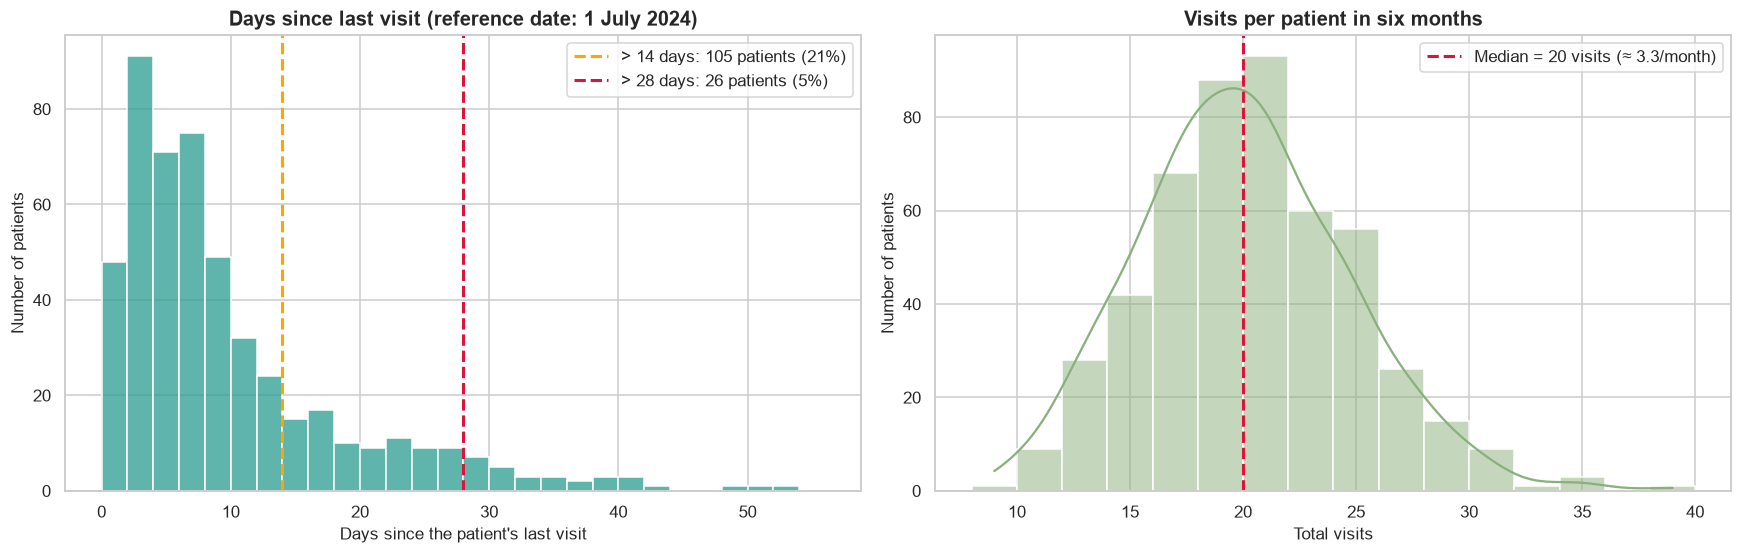

Patients with no visit in the last 14 days: 105 | last 28 days: 26
Visits per patient: min 9, median 20, max 39 | high utilisers (>= 23 visits): 137
Patients who were active in all 6 months: 81%


In [54]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.2))
sns.histplot(ABT["Days_Since_Last_Visit"], bins=range(0, 58, 2), color="#2a9d8f", edgecolor="white", ax=ax[0])
for thr, col_ in [(14, "orange"), (28, "crimson")]:
    ax[0].axvline(thr, color=col_, ls="--", lw=2, label=f"> {thr} days: {(ABT['Days_Since_Last_Visit'] > thr).sum()} patients ({(ABT['Days_Since_Last_Visit'] > thr).mean():.0%})")
ax[0].set_title("Days since last visit (reference date: 1 July 2024)")
ax[0].set_xlabel("Days since the patient's last visit"); ax[0].set_ylabel("Number of patients"); ax[0].legend()

sns.histplot(ABT["Total_Visits"], bins=range(8, 42, 2), color="#8ab17d", edgecolor="white", kde=True, ax=ax[1])
ax[1].axvline(ABT["Total_Visits"].median(), color="crimson", ls="--", lw=2, label=f"Median = {ABT['Total_Visits'].median():.0f} visits (≈ {ABT['Total_Visits'].median()/6:.1f}/month)")
ax[1].set_title("Visits per patient in six months")
ax[1].set_xlabel("Total visits"); ax[1].set_ylabel("Number of patients"); ax[1].legend()
plt.tight_layout(); plt.show()

q75 = ABT["Total_Visits"].quantile(.75)
print(f"Patients with no visit in the last 14 days: {(ABT['Days_Since_Last_Visit'] > 14).sum()} | last 28 days: {(ABT['Days_Since_Last_Visit'] > 28).sum()}")
print(f"Visits per patient: min {ABT['Total_Visits'].min()}, median {ABT['Total_Visits'].median():.0f}, max {ABT['Total_Visits'].max()} | high utilisers (>= {q75:.0f} visits): {(ABT['Total_Visits'] >= q75).sum()}")
print(f"Patients who were active in all 6 months: {(ABT['Active_Months'] == 6).mean():.0%}")

**Interpretation.** Engagement is high and regular: 81 % of patients came in all six months and the median patient has 20 visits (≈ 3.3 per month). Only 105 patients (21 %) had not been seen in the 14 days before the reference date and 26 (5 %) in the last 28 days, which makes a recency-based "inactive patient" flag feasible but with a modest positive class. Visit counts per patient are narrowly distributed (9-39), so frequency differences between patients are mostly moderate.

## <font color='turquoise'>3.5 Management Questions and Key Insights</font> <a class="anchor" id="3_5"></a>

The answers below are **computed from the data** (not typed), so they update if the data are refreshed.

In [55]:
dv = clean["Department"].value_counts()
mpd = clean.groupby(clean["Visit Date"].dt.month).size() / days_in_month
worst_sat = sd["mean"].idxmin(); best_sat = sd["mean"].idxmax()
unins = ABT[ABT["Insured"] == 0]
answers = {
 "Q1. Which departments are the busiest, and how does demand change Jan-Jun?":
    f"{dv.index[0]} ({dv.iloc[0]:,} visits) and {dv.index[1]} ({dv.iloc[1]:,}) are about twice as busy as any other department "
    f"({(dv.iloc[:2].sum()/len(clean)):.0%} of all consultations together). Overall demand is flat: {mpd.min():.1f}-{mpd.max():.1f} visits/day every month "
    f"(Jan->Jun {mpd[6]/mpd[1]-1:+.1%}); no department shows a sustained trend.",
 "Q2. Which patient groups use which departments most?":
    f"No group has a distinct department profile: department mix does not differ by gender (p = {p_g:.2f}) nor by age group (p = {p_a:.2f}). "
    f"Every group sends most visits to {dv.index[0]} and {dv.index[1]}. The visible 'lifts' are within what random shuffling produces.",
 "Q3. Which departments / groups report the lowest satisfaction?":
    f"{worst_sat} is lowest ({sd['mean'].min():.2f} vs hospital {MEAN_SAT:.2f}; {sd.loc[worst_sat,'low_share']:.0f}% low ratings) and {best_sat} highest ({sd['mean'].max():.2f}), "
    f"but department differences are small and not conclusive (Kruskal-Wallis p = {kw.pvalue:.2f}). No patient segment differs significantly after correcting for multiple tests.",
 "Q4. How much of the cost is covered by insurance and how much do patients pay?":
    f"Insurers cover {tot_cov/tot_price:.1%} of the £{tot_price:,.0f} billed; patients pay {tot_oop/tot_price:.1%} (£{tot_oop:,.0f}). "
    f"Coverage depends only on the provider (A 80%, B 90%, C 70%, D 100%). The {len(unins)} uninsured patients ({len(unins)/N_PAT:.0%}) pay "
    f"{unins['Total_Out_of_Pocket'].sum()/ABT['Total_Out_of_Pocket'].sum():.0%} of all out-of-pocket money.",
}
for q, a in answers.items():
    print(f"{q}\n   -> {a}\n")

Q1. Which departments are the busiest, and how does demand change Jan-Jun?
   -> Psychiatry (1,359 visits) and General Practice (1,331) are about twice as busy as any other department (27% of all consultations together). Overall demand is flat: 53.3-56.6 visits/day every month (Jan->Jun -3.4%); no department shows a sustained trend.

Q2. Which patient groups use which departments most?
   -> No group has a distinct department profile: department mix does not differ by gender (p = 0.24) nor by age group (p = 0.16). Every group sends most visits to Psychiatry and General Practice. The visible 'lifts' are within what random shuffling produces.

Q3. Which departments / groups report the lowest satisfaction?
   -> General Practice is lowest (2.85 vs hospital 2.99; 45% low ratings) and Gastroenterology highest (3.09), but department differences are small and not conclusive (Kruskal-Wallis p = 0.08). No patient segment differs significantly after correcting for multiple tests.

Q4. How much o

### Key insights at a glance

1. **Two departments carry the volume.** Psychiatry and General Practice = 27 % of consultations, twice any other department; the other 11 are uniform.
2. **Volume ≠ value.** Emergency (£300/visit) equals Psychiatry in revenue (12.4 %) with half the visits; General Practice is #2 in volume but #9 in revenue.
3. **Demand is flat** (53-57 visits/day each month) - no seasonality or growth to plan for.
4. **The hospital serves two very different populations**: children/teens (20 %) and seniors 65+ (35 %), with a thin middle; the "average" age of 49 is misleading.
5. **Insurance is the main financial divide**: insurers pay 70 %, but the 18 % uninsured patients pay 60 % of everything patients pay out of pocket (avg £3,315 vs £484).
6. **Satisfaction is ≈ 3.0 everywhere.** General Practice is the only department with evidence of a lower score (2.85, p = 0.003); no patient segment differs; and satisfaction cannot be predicted from the available features (AUC 0.49).
7. **No hidden group preferences**: department choice is unrelated to gender and age group once random variation is accounted for.
8. **The data quality issues mattered**: capping the invalid rating "6" at 5 would have made ENT and General Practice look like the best-rated departments (≈ 4.0 vs 3.0 clean) - the opposite of the truth for General Practice.

## <font color='turquoise'>3.6 Recommendations for the Next Analytics Team</font> <a class="anchor" id="3_6"></a>

In [56]:
# Quantify the candidate targets so the next team can see class balance before choosing
targets = pd.DataFrame({
    "Candidate target": ["Inactive patient (no visit > 14 days before 1 Jul)", "High spender (top quartile of Total_Spent)",
                          "High out-of-pocket burden (Out_of_Pocket_Share >= 0.5)", "Dissatisfied patient (Avg_Satisfaction < 2.75)",
                          "Frequent Emergency user (>= 3 Emergency visits)", "Declining activity (Visit_Trend <= -3)"],
    "Definition (ABT columns)": ["Days_Since_Last_Visit > 14", "Total_Spent >= Q3", "Out_of_Pocket_Share >= 0.5", "Avg_Satisfaction < 2.75",
                                 "Emergency_Visits >= 3", "Visit_Trend <= -3"],
    "Positive patients": [(ABT["Days_Since_Last_Visit"] > 14).sum(), (ABT["Total_Spent"] >= ABT["Total_Spent"].quantile(.75)).sum(),
                          (ABT["Out_of_Pocket_Share"] >= .5).sum(), (ABT["Avg_Satisfaction"] < 2.75).sum(),
                          (ABT["Emergency_Visits"] >= 3).sum(), (ABT["Visit_Trend"] <= -3).sum()]})
targets["% of patients"] = (targets["Positive patients"] / N_PAT * 100).round(1)
display(targets)

# Predictive signal check on the most 'obvious' target: can ABT features tell dissatisfied patients apart? (cross-validated AUC)
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
y_dis = (ABT["Avg_Satisfaction"] < 2.75).astype(int)
Xnum = pd.get_dummies(ABT[["Age", "Annual_Income", "Education_Rank", "Total_Visits", "Distinct_Departments", "Avg_Consultation_Price",
                           "Emergency_Share", "Out_of_Pocket_Share", "Insured", "Days_Since_Last_Visit", "Gender", "Profession", "Marital_Status", "City"]], drop_first=True)
auc = cross_val_score(RandomForestClassifier(300, min_samples_leaf=5, random_state=42), Xnum, y_dis, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="roc_auc")
print(f"Cross-validated ROC-AUC for predicting 'dissatisfied' from all other features: {auc.mean():.2f} ± {auc.std():.2f}   (0.50 = coin flip)")

,Candidate target,Definition (ABT columns),Positive patients,% of patients
0,Inactive patient (no visit > 14 days before 1 Jul),Days_Since_Last_Visit > 14,105,21.0
1,High spender (top quartile of Total_Spent),Total_Spent >= Q3,125,25.0
2,High out-of-pocket burden (Out_of_Pocket_Share >= 0.5),Out_of_Pocket_Share >= 0.5,90,18.0
3,Dissatisfied patient (Avg_Satisfaction < 2.75),Avg_Satisfaction < 2.75,116,23.2
4,Frequent Emergency user (>= 3 Emergency visits),Emergency_Visits >= 3,88,17.6
5,Declining activity (Visit_Trend <= -3),Visit_Trend <= -3,142,28.4


Cross-validated ROC-AUC for predicting 'dissatisfied' from all other features: 0.49 ± 0.05   (0.50 = coin flip)


### Suggestions for the next analytics team

**Sensible targets** (class balance shown in the table above)
- **Inactivity / churn:** `Days_Since_Last_Visit > 14` (21 % positive). The most realistic target: recency is a genuine behavioural signal. A forward-looking version needs a longer observation window.
- **High-cost patients:** `Total_Spent` top quartile - strongly predictable from `Total_Visits` and `Emergency_Share`, so use visit history up to a cut-off date to avoid trivial leakage.
- **Financial vulnerability:** `Out_of_Pocket_Share ≥ 0.5` (18 %): this is *exactly* the uninsured group, so it is a classification of insurance status, not a behavioural target; model out-of-pocket **amount** among insured patients instead if a financial target is needed.
- **Next department / Emergency propensity:** multi-class or binary models on the department visit counts and the monthly columns (`Visits_Jan` ... `Visits_Jun`).
- **Do not rely on satisfaction as a target.** With a cross-validated AUC of 0.49 for "dissatisfied", ratings behave like noise relative to every available variable. Before modelling satisfaction the hospital should check the rating process (see below).

**Segmentation ideas**
- Rule-based segments rather than K-means (silhouette ≈ 0.15): *insurance status × utilisation level* (insured/uninsured × low/high visits) and *life-stage* (child/teen, adult, senior).
- Department-mix profiles: cluster on the 13 `Visits_*` shares or on `Department_Diversity_Index` to separate specialist-loyal from multi-department patients.
- RFM-style value segments with `Days_Since_Last_Visit`, `Total_Visits` and `Total_Spent` (note that spend is nearly 1:1 with frequency).

**Cautions and data follow-ups**
- **Rating scale:** 36 % of ENT and General Practice ratings had the invalid value 6 versus ≈ 0 % elsewhere. Ask the information-systems team whether those departments use a different form; until answered, treat their satisfaction figures as less reliable (`N_Invalid_Ratings` is in the ABT).
- **Income** varies from visit to visit and does not distinguish professions; it is most useful as "has income / has none".
- **Redundant features:** `Age`/`Profession`/`Education_Level`, `Total_Spent`/`Total_Visits`, `Distinct_Departments`/`Department_Diversity_Index`, `Insurance_Provider`/`Insurance_Coverage_Ratio` (the last is deterministic). Pick one per group.
- **Gender "Other"** is 34 % of patients; confirm the coding convention.
- **Only six months of data**: seasonality cannot be assessed, and patient-level trends rest on 20 visits on average.

---
### Deliverables produced by this notebook

| File | Content |
|---|---|
| `ABT_city_hospital.csv` | Analytic Base Table - one row per patient (500 × 74) |
| `Data_Dictionary_city_hospital.csv` | Name, group, definition and calculation of every ABT feature |
| `Data_Quality_Log.csv` | Every cleaning decision with rows/patients affected and its justification |

The notebook runs from start to finish with `Project_Data.xlsx` (or `Project_Data_nova.xlsx`) in the same folder; the raw file is never modified.